In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx
import pandas as pd
from shapely.geometry import Point, LineString, MultiLineString
import seaborn as sns
import numpy as np
import os
from shapely.ops import nearest_points
from sklearn.neighbors import KDTree
import json
from tqdm.notebook import tqdm

In [ ]:
landuse_gdf = gpd.read_file('land_uset.shp')
restrictions_gdf = gpd.read_file('restrictiont.shp')
streets_gdf = gpd.read_file('street.shp')

/usr/local/lib/python3.10/dist-packages/geopandas/plotting.py:658: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  warnings.warn(


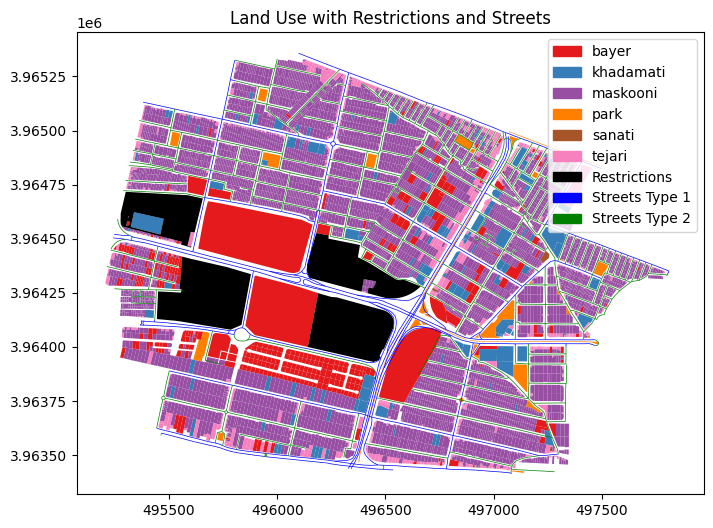

In [ ]:
column_name = 'landuse2'

fig, ax = plt.subplots(1, 1, figsize=(10, 6))

unique_values = sorted(landuse_gdf[column_name].unique())

cmap = plt.get_cmap('Set1')
colors = {val: cmap(i / len(unique_values)) for i, val in enumerate(unique_values)}

landuse_gdf.plot(column=column_name, ax=ax, color=[colors[val] for val in landuse_gdf[column_name]], legend=False)

handles = [mpatches.Patch(color=colors[val], label=val) for val in unique_values]

restrictions_gdf.plot(ax=ax, color='black')

streets_type1 = streets_gdf[streets_gdf['type'] == 1]
streets_type1.plot(ax=ax, color='blue', linewidth=0.5)
streets_type2 = streets_gdf[streets_gdf['type'] == 2]
streets_type2.plot(ax=ax, color='green', linewidth=0.5)

restriction_patch = mpatches.Patch(color='black', label='Restrictions')
streets_type1_patch = mpatches.Patch(color='blue', label='Streets Type 1')
streets_type2_patch = mpatches.Patch(color='green', label='Streets Type 2')

handles.append(restriction_patch)
handles.append(streets_type1_patch)
handles.append(streets_type2_patch)

ax.set_title('Land Use with Restrictions and Streets')
ax.legend(handles=handles, loc='upper right')

plt.show()

/usr/local/lib/python3.10/dist-packages/geopandas/plotting.py:658: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  warnings.warn(


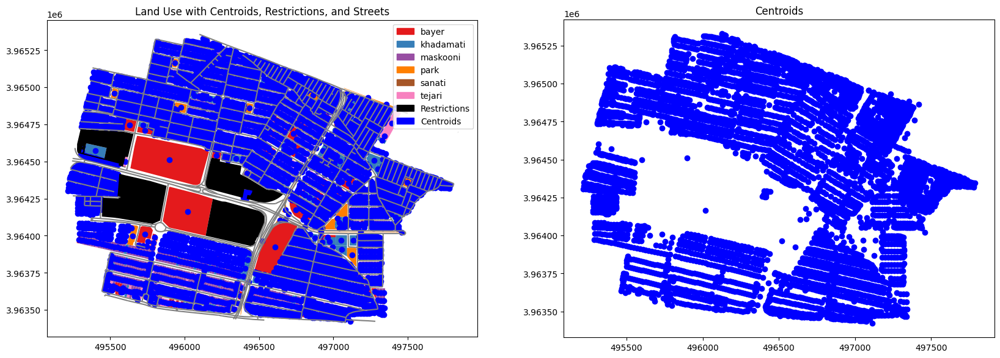

In [ ]:
landuse_gdf = gpd.read_file('land_uset.shp')
restrictions_gdf = gpd.read_file('restrictiont.shp')
streets_gdf = gpd.read_file('street.shp')


landuse_gdf['centroid'] = landuse_gdf.centroid
centroids_gdf = gpd.GeoDataFrame(landuse_gdf[['landuse2', 'SHAPE_Area', 'centroid']], geometry='centroid')

G = nx.Graph()

def add_edge_from_linestring(line):
    coords = list(line.coords)
    for i in range(len(coords) - 1):
        start_point = Point(coords[i])
        end_point = Point(coords[i + 1])
        G.add_edge((start_point.x, start_point.y), (end_point.x, end_point.y))

for idx, row in streets_gdf.iterrows():
    if isinstance(row.geometry, LineString):
        add_edge_from_linestring(row.geometry)
    elif isinstance(row.geometry, MultiLineString):
        for line in row.geometry:
            add_edge_from_linestring(line)


for idx, row in centroids_gdf.iterrows():
    centroid = row['centroid']
    G.add_node((centroid.x, centroid.y), landuse=row['landuse2'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))

unique_values = sorted(landuse_gdf['landuse2'].unique())
cmap = plt.get_cmap('Set1')
colors = {val: cmap(i / len(unique_values)) for i, val in enumerate(unique_values)}

landuse_gdf.plot(column='landuse2', ax=ax1, color=[colors[val] for val in landuse_gdf['landuse2']], legend=False)
centroids_gdf.plot(ax=ax1, color='blue', marker='o', label='Centroids')
restrictions_gdf.plot(ax=ax1, color='black')
streets_gdf.plot(ax=ax1, color='grey')

handles = [mpatches.Patch(color=colors[val], label=val) for val in unique_values]
restriction_patch = mpatches.Patch(color='black', label='Restrictions')
centroids_patch = mpatches.Patch(color='blue', label='Centroids')
handles.append(restriction_patch)
handles.append(centroids_patch)

ax1.set_title('Land Use with Centroids, Restrictions, and Streets')
ax1.legend(handles=handles, loc='upper right')

centroids_gdf.plot(ax=ax2, color='blue', marker='o')
ax2.set_title('Centroids')

plt.show()


In [ ]:
centroids_gdf.head(10)

,landuse2,SHAPE_Area,centroid
0,park,136.512665,POINT (496915.431 3964027.831)
1,park,1245.557294,POINT (497183.976 3964024.884)
2,tejari,45.584853,POINT (496851.133 3964479.844)
3,maskooni,130.751441,POINT (496971.087 3964476.500)
4,tejari,30.951847,POINT (497554.328 3964266.334)
5,maskooni,160.263962,POINT (497391.730 3964307.667)
6,khadamati,171.410198,POINT (497466.450 3964315.446)
7,maskooni,59.244715,POINT (497780.181 3964318.185)
8,maskooni,430.649646,POINT (497381.003 3964312.960)
9,tejari,24.741739,POINT (497781.069 3964325.974)


In [ ]:
landuse_gdf.head(10)

,OBJECTID,landuse2,SHAPE_Leng,SHAPE_Area,geometry,centroid
0,1,park,105.455958,136.512665,"POLYGON ((496940.491 3964027.419, 496940.621 3...",POINT (496915.431 3964027.831)
1,2,park,947.914231,1245.557294,"POLYGON ((497351.336 3964025.545, 497380.877 3...",POINT (497183.976 3964024.884)
2,3,tejari,34.123117,45.584853,"POLYGON ((496857.933 3964477.785, 496856.737 3...",POINT (496851.133 3964479.844)
3,4,maskooni,48.355071,130.751441,"POLYGON ((496978.598 3964481.452, 496975.810 3...",POINT (496971.087 3964476.500)
4,5,tejari,22.322830,30.951847,"POLYGON ((497557.699 3964268.273, 497556.913 3...",POINT (497554.328 3964266.334)
5,6,maskooni,64.110491,160.263962,"POLYGON ((497394.030 3964320.795, 497396.397 3...",POINT (497391.730 3964307.667)
6,7,khadamati,57.224694,171.410198,"POLYGON ((497477.052 3964315.745, 497476.151 3...",POINT (497466.450 3964315.446)
7,8,maskooni,35.636910,59.244715,"POLYGON ((497783.290 3964323.849, 497781.705 3...",POINT (497780.181 3964318.185)
8,9,maskooni,83.900775,430.649646,"POLYGON ((497383.229 3964325.255, 497387.813 3...",POINT (497381.003 3964312.960)
9,10,tejari,20.913249,24.741739,"POLYGON ((497783.290 3964323.849, 497777.797 3...",POINT (497781.069 3964325.974)


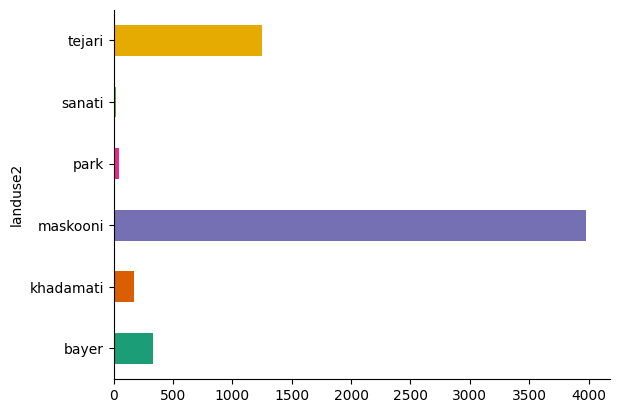

In [ ]:
# @title landuse2

from matplotlib import pyplot as plt
import seaborn as sns
centroids_gdf.groupby('landuse2').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

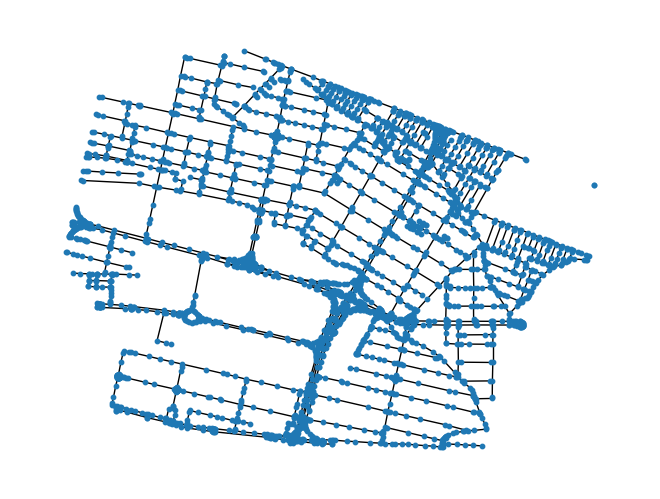

In [ ]:
street_data = gpd.read_file('street.shp')

street_network = nx.Graph()

def add_edges_from_line(line):
    coordinates = list(line.coords)
    for i in range(len(coordinates) - 1):
        start_point = Point(coordinates[i])
        end_point = Point(coordinates[i + 1])
        street_network.add_edge((start_point.x, start_point.y), (end_point.x, end_point.y), weight=start_point.distance(end_point))

for index, row in street_data.iterrows():
    if isinstance(row.geometry, LineString):
        add_edges_from_line(row.geometry)
    elif isinstance(row.geometry, MultiLineString):
        for line in row.geometry:
            add_edges_from_line(line)

positions = {node: node for node in street_network.nodes()}
nx.draw(street_network, positions, with_labels=False, node_size=10)
plt.show()

In [ ]:
adjacency_matrix = nx.adjacency_matrix(street_network)

adj_matrix_dense = adjacency_matrix.todense()
adj_matrix_df = pd.DataFrame(adj_matrix_dense)

unweighted_adj_matrix = nx.adjacency_matrix(street_network, weight=None)

unweighted_adj_matrix_dense = unweighted_adj_matrix.todense()
unweighted_adj_matrix_df = pd.DataFrame(unweighted_adj_matrix_dense)

In [ ]:
od_cost_dict = dict(nx.all_pairs_dijkstra_path_length(street_network, weight='weight'))

nodes = sorted(street_network.nodes())

od_cost_df = pd.DataFrame(index=nodes, columns=nodes)

for origin, dest_dict in od_cost_dict.items():
    for dest, cost in dest_dict.items():
        od_cost_df.at[origin, dest] = cost

od_cost_df = od_cost_df.fillna(float('inf'))
np.fill_diagonal(od_cost_df.values, 0)

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

In [ ]:
# Specify the directory path in your Google Drive
# drive_directory_path = '/content/drive/My Drive/ColabData/'

# Create the directory if it doesn't exist
# os.makedirs(drive_directory_path, exist_ok=True)

# Save the OD cost matrix to the specified directory
# od_cost_df.to_csv(os.path.join(drive_directory_path, 'od_cost_matrix_street_network.csv'))

# Similarly, save the adjacency matrices
# adj_matrix_df.to_csv(os.path.join(drive_directory_path, 'weighted_adjacency_matrix_street_network.csv'))
# unweighted_adj_matrix_df.to_csv(os.path.join(drive_directory_path, 'unweighted_adjacency_matrix_street_network.csv'))

Shortest path from (495220.83459224086, 3964369.77076325) to (495787.9970550891, 3964075.538899999): [(495220.83459224086, 3964369.77076325), (495251.28160000127, 3964362.4219000004), (495271.3090000022, 3964357.5179000013), (495293.2880467735, 3964352.1360384375), (495335.3431000011, 3964341.8383000027), (495414.6003361726, 3964322.049608225), (495416.79000000004, 3964321.5029000025), (495406.99116481654, 3964275.5018123295), (495404.57210000046, 3964264.1454000007), (495438.56640000176, 3964263.7123000007), (495441.1525000008, 3964263.683699999), (495440.9667829629, 3964257.7406826727), (495440.1218999997, 3964230.7041000035), (495440.08820000105, 3964229.6547000036), (495439.1345000006, 3964200.015200002), (495438.7477000002, 3964187.9338000026), (495437.3562000003, 3964169.741600001), (495436.39180401806, 3964157.132706307), (495434.5217801193, 3964132.68327184), (495434.11000000034, 3964127.2994999997), (495433.78166525904, 3964123.0066408757), (495433.2097000005, 3964115.52840000

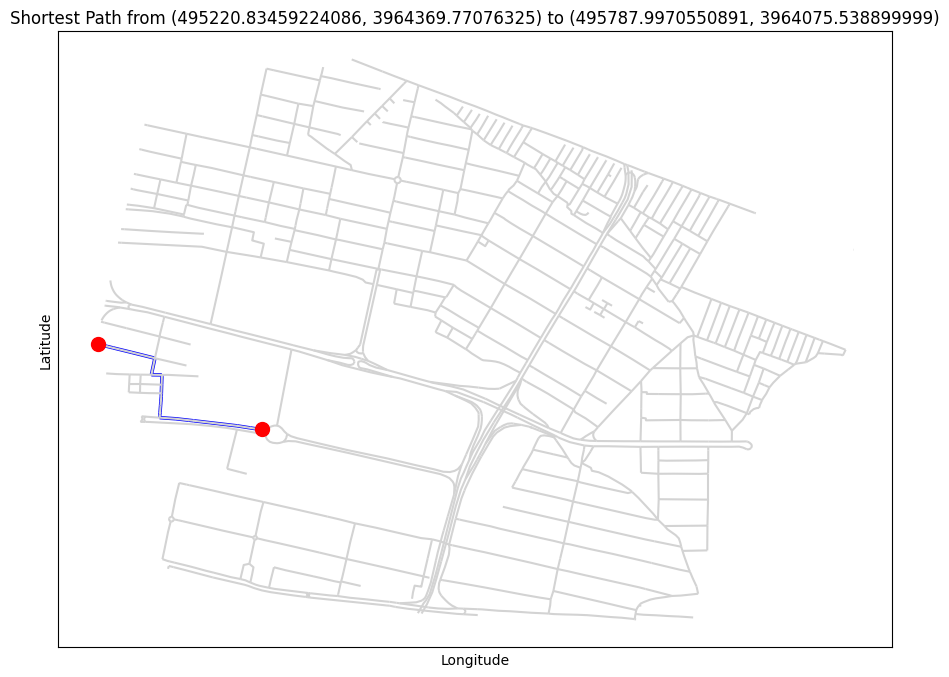

In [ ]:
id_1 = nodes[1]
id_0 = nodes[500]

# Find the shortest path
shortest_path = nx.shortest_path(street_network, source=id_1, target=id_0, weight='weight')
print(f"Shortest path from {id_1} to {id_0}: {shortest_path}")

total_distance = sum(street_network[u][v]['weight'] for u, v in zip(shortest_path[:-1], shortest_path[1:]))
print(f"Total distance of the shortest path: {total_distance}")

plt.figure(figsize=(12, 8))
ax = plt.gca()

street_data.plot(ax=ax, color='lightgrey')

# Plot the shortest path
path_edges = list(zip(shortest_path, shortest_path[1:]))
for edge in path_edges:
    nx.draw_networkx_edges(street_network, pos={node: (node[0], node[1]) for node in street_network.nodes()}, edgelist=[edge], edge_color='blue', width=2.5)

highlight_nodes = [id_1, id_0]
nx.draw_networkx_nodes(street_network, pos={node: (node[0], node[1]) for node in street_network.nodes()}, nodelist=highlight_nodes, node_color='red', node_size=100)

plt.title(f"Shortest Path from {id_1} to {id_0}")
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

In [ ]:
od_cost_df.at[id_0, id_1]

802.6695241226314

In [ ]:
od_cost_df.head(10)

,"(495212.52630000096, 3964371.7761000004)","(495220.83459224086, 3964369.77076325)","(495230.01600000076, 3964447.9047000036)","(495230.6526821228, 3964447.744311195)","(495231.8502000002, 3964452.5503000002)","(495235.1117000012, 3964458.695100002)","(495238.78249999974, 3964464.4607000016)","(495240.2850856595, 3964466.4442736413)","(495241.8026318252, 3964444.9354885854)","(495242.41399999894, 3964503.8231000006)",...,"(497759.2392999986, 3964370.9877000004)","(497774.25009972416, 3964365.0903769135)","(497785.84083459154, 3964334.2822638657)","(497795.5250000013, 3964333.615599999)","(497796.22002440505, 3964356.459008405)","(497801.2589000007, 3964330.827800002)","(497808.9408370545, 3964351.4613571484)","(497810.8808000004, 3964350.6992000006)","(497837.7793604238, 3964697.7969585285)","(497838.69900000095, 3964697.4858000036)"
"(495212.52630000096, 3964371.7761000004)",0.000000,8.546876,497.263965,496.607391,596.815418,589.858698,583.023721,580.535282,485.109093,568.728586,...,2937.724022,2953.851716,2934.703742,2944.410827,2977.456337,2950.786518,2974.949175,2972.864867,inf,inf
"(495220.83459224086, 3964369.77076325)",8.546876,0.000000,488.717089,488.060515,588.268542,581.311822,574.476844,571.988406,476.562217,560.181709,...,2929.177145,2945.304840,2926.156865,2935.863950,2968.909460,2942.239642,2966.402299,2964.317991,inf,inf
"(495230.01600000076, 3964447.9047000036)",497.263965,488.717089,0.000000,0.656573,519.409531,512.452812,505.617834,503.129395,12.154872,491.322699,...,2860.318135,2876.445829,2857.297855,2867.004940,2900.050450,2873.380631,2897.543288,2895.458980,inf,inf
"(495230.6526821228, 3964447.744311195)",496.607391,488.060515,0.656573,0.000000,518.752958,511.796238,504.961261,502.472822,11.498298,490.666126,...,2859.661562,2875.789256,2856.641282,2866.348367,2899.393877,2872.724058,2896.886715,2894.802407,inf,inf
"(495231.8502000002, 3964452.5503000002)",596.815418,588.268542,519.409531,518.752958,0.000000,6.956720,13.791697,16.280136,507.254660,135.145025,...,2818.756611,2834.884305,2815.736331,2825.443416,2858.488926,2831.819107,2855.981764,2853.897456,inf,inf
"(495235.1117000012, 3964458.695100002)",589.858698,581.311822,512.452812,511.796238,6.956720,0.000000,6.834977,9.323416,500.297940,128.188305,...,2811.799891,2827.927586,2808.779611,2818.486696,2851.532206,2824.862387,2849.025045,2846.940737,inf,inf
"(495238.78249999974, 3964464.4607000016)",583.023721,574.476844,505.617834,504.961261,13.791697,6.834977,0.000000,2.488439,493.462962,121.353328,...,2804.964914,2821.092608,2801.944634,2811.651719,2844.697229,2818.027410,2842.190067,2840.105759,inf,inf
"(495240.2850856595, 3964466.4442736413)",580.535282,571.988406,503.129395,502.472822,16.280136,9.323416,2.488439,0.000000,490.974524,118.864889,...,2802.476475,2818.604169,2799.456195,2809.163280,2842.208790,2815.538971,2839.701628,2837.617320,inf,inf
"(495241.8026318252, 3964444.9354885854)",485.109093,476.562217,12.154872,11.498298,507.254660,500.297940,493.462962,490.974524,0.000000,479.167828,...,2848.163263,2864.290958,2845.142983,2854.850068,2887.895578,2861.225760,2885.388417,2883.304109,inf,inf
"(495242.41399999894, 3964503.8231000006)",568.728586,560.181709,491.322699,490.666126,135.145025,128.188305,121.353328,118.864889,479.167828,0.000000,...,2790.669779,2806.797473,2787.649499,2797.356584,2830.402094,2803.732275,2827.894932,2825.810624,inf,inf


### Failed

/usr/local/lib/python3.10/dist-packages/geopandas/plotting.py:695: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/geopandas/plotting.py:695: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  warnings.warn(


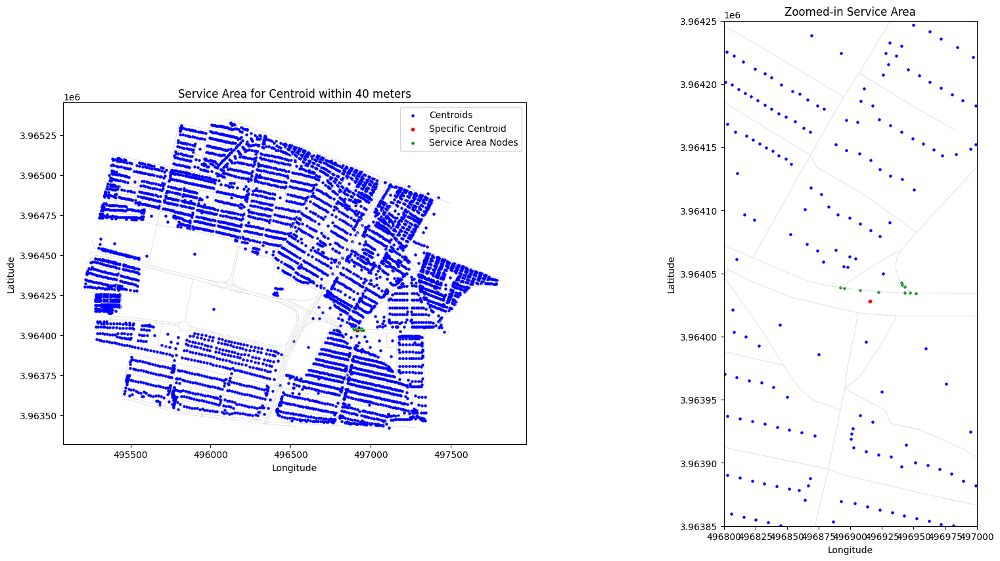

In [ ]:
specific_centroid = centroids_gdf.iloc[0].centroid
centroid_coord = (specific_centroid.x, specific_centroid.y)

closest_node = min(street_network.nodes, key=lambda node: Point(node).distance(Point(centroid_coord)))

service_area = nx.single_source_dijkstra_path_length(street_network, closest_node, cutoff=40, weight='weight')

service_area_nodes = list(service_area.keys())

service_area_points = [Point(node) for node in service_area_nodes]

service_area_gdf = gpd.GeoDataFrame(geometry=service_area_points)

selected_centroids = centroids_gdf[centroids_gdf.geometry.apply(lambda point: any(Point(node).distance(point) == 0 for node in service_area_nodes))]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))

street_data.plot(ax=ax1, color='lightgrey', linewidth=0.5)
street_data.plot(ax=ax2, color='lightgrey', linewidth=0.5)

centroids_gdf.plot(ax=ax1, color='blue', markersize=5, label='Centroids')
centroids_gdf.plot(ax=ax2, color='blue', markersize=5)

centroids_gdf[centroids_gdf.centroid == specific_centroid].plot(ax=ax1, color='red', markersize=10, label='Specific Centroid')
centroids_gdf[centroids_gdf.centroid == specific_centroid].plot(ax=ax2, color='red', markersize=10)

service_area_gdf.plot(ax=ax1, color='green', markersize=5, label='Service Area Nodes')
service_area_gdf.plot(ax=ax2, color='green', markersize=5)

selected_centroids.plot(ax=ax1, color='yellow', markersize=10, label='Selected Centroids')
selected_centroids.plot(ax=ax2, color='yellow', markersize=10)

ax1.legend()
ax1.set_title(f'Service Area for Centroid within 40 meters')
ax1.set_xlabel('Longitude')
ax1.set_ylabel('Latitude')

ax2.set_xlim(496800, 497000)
ax2.set_ylim(3963850, 3964250)

ax2.set_title('Zoomed-in Service Area')
ax2.set_xlabel('Longitude')
ax2.set_ylabel('Latitude')

plt.show()

### Failed

/usr/local/lib/python3.10/dist-packages/geopandas/plotting.py:695: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/geopandas/plotting.py:695: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/geopandas/plotting.py:695: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  warnings.warn(


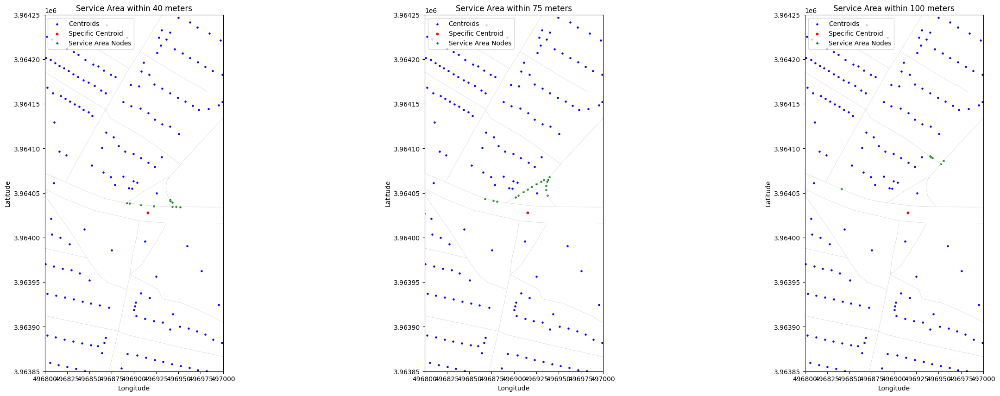

In [ ]:
# Calculate service areas
service_area_40 = nx.single_source_dijkstra_path_length(street_network, closest_node, cutoff=40, weight='weight')
service_area_75 = nx.single_source_dijkstra_path_length(street_network, closest_node, cutoff=75, weight='weight')
service_area_100 = nx.single_source_dijkstra_path_length(street_network, closest_node, cutoff=100, weight='weight')

service_area_nodes_40 = set(service_area_40.keys())
service_area_nodes_75 = set(service_area_75.keys()) - service_area_nodes_40
service_area_nodes_100 = set(service_area_100.keys()) - service_area_nodes_40 - service_area_nodes_75

service_area_points_40 = [Point(node) for node in service_area_nodes_40]
service_area_points_75 = [Point(node) for node in service_area_nodes_75]
service_area_points_100 = [Point(node) for node in service_area_nodes_100]

service_area_gdf_40 = gpd.GeoDataFrame(geometry=service_area_points_40)
service_area_gdf_75 = gpd.GeoDataFrame(geometry=service_area_points_75)
service_area_gdf_100 = gpd.GeoDataFrame(geometry=service_area_points_100)

selected_centroids_40 = centroids_gdf[centroids_gdf.geometry.apply(lambda point: any(Point(node).distance(point) == 0 for node in service_area_nodes_40))]
selected_centroids_75 = centroids_gdf[centroids_gdf.geometry.apply(lambda point: any(Point(node).distance(point) == 0 for node in service_area_nodes_75))]
selected_centroids_100 = centroids_gdf[centroids_gdf.geometry.apply(lambda point: any(Point(node).distance(point) == 0 for node in service_area_nodes_100))]

fig, axes = plt.subplots(1, 3, figsize=(30, 10))
def plot_service_area(ax, street_data, centroids_gdf, specific_centroid, service_area_gdf, selected_centroids, title):
    street_data.plot(ax=ax, color='lightgrey', linewidth=0.5)
    centroids_gdf.plot(ax=ax, color='blue', markersize=5, label='Centroids')
    centroids_gdf[centroids_gdf.centroid == specific_centroid].plot(ax=ax, color='red', markersize=10, label='Specific Centroid')
    service_area_gdf.plot(ax=ax, color='green', markersize=5, label='Service Area Nodes')
    selected_centroids.plot(ax=ax, color='yellow', markersize=10, label='Selected Centroids')
    ax.legend(loc='upper left')
    ax.set_title(title)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_xlim(496800, 497000)
    ax.set_ylim(3963850, 3964250)

plot_service_area(axes[0], street_data, centroids_gdf, specific_centroid, service_area_gdf_40, selected_centroids_40, 'Service Area within 40 meters')
plot_service_area(axes[1], street_data, centroids_gdf, specific_centroid, service_area_gdf_75, selected_centroids_75, 'Service Area within 75 meters')
plot_service_area(axes[2], street_data, centroids_gdf, specific_centroid, service_area_gdf_100, selected_centroids_100, 'Service Area within 100 meters')

plt.show()

<ipython-input-126-bcf76725a0ed>:16: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend(loc='upper left')


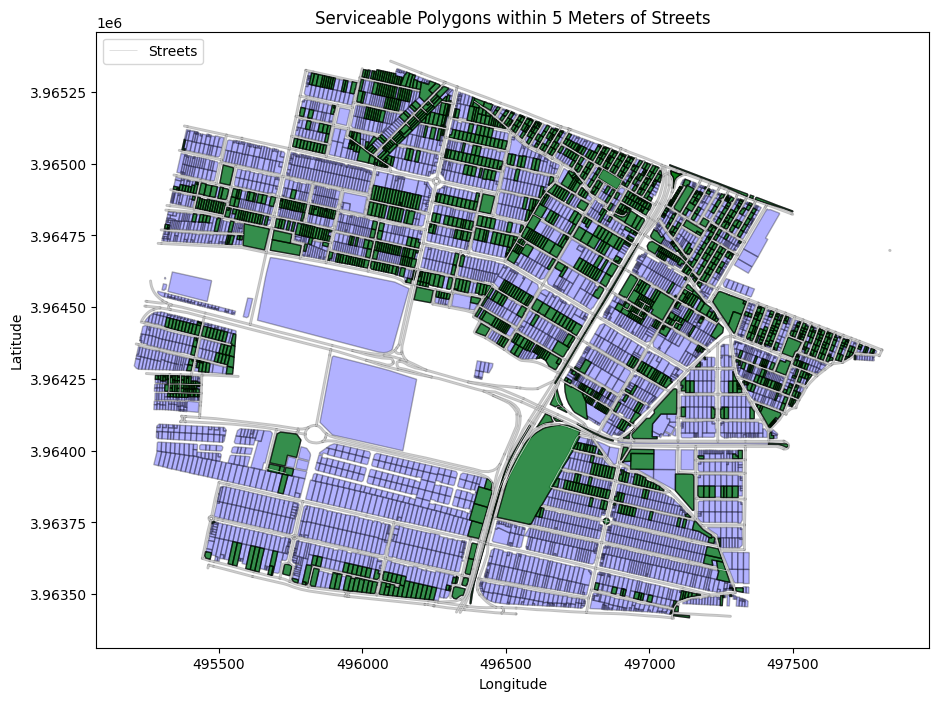

In [ ]:
buffer_distance = 5
buffered_streets = street_data.buffer(buffer_distance)

serviceable_polygons = landuse_gdf[landuse_gdf.geometry.apply(lambda poly: any(poly.intersects(buffer) for buffer in buffered_streets))]

fig, ax = plt.subplots(1, 1, figsize=(12, 8))

street_data.plot(ax=ax, color='lightgrey', linewidth=0.5, label='Streets')

gpd.GeoSeries(buffered_streets).plot(ax=ax, color='grey', alpha=0.5, label='Buffered Streets')

landuse_gdf.plot(ax=ax, color='blue', alpha=0.3, edgecolor='black', label='All Polygons')

serviceable_polygons.plot(ax=ax, color='green', alpha=0.7, edgecolor='black', label='Serviceable Polygons')

ax.legend(loc='upper left')

plt.title('Serviceable Polygons within 5 Meters of Streets')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.show()


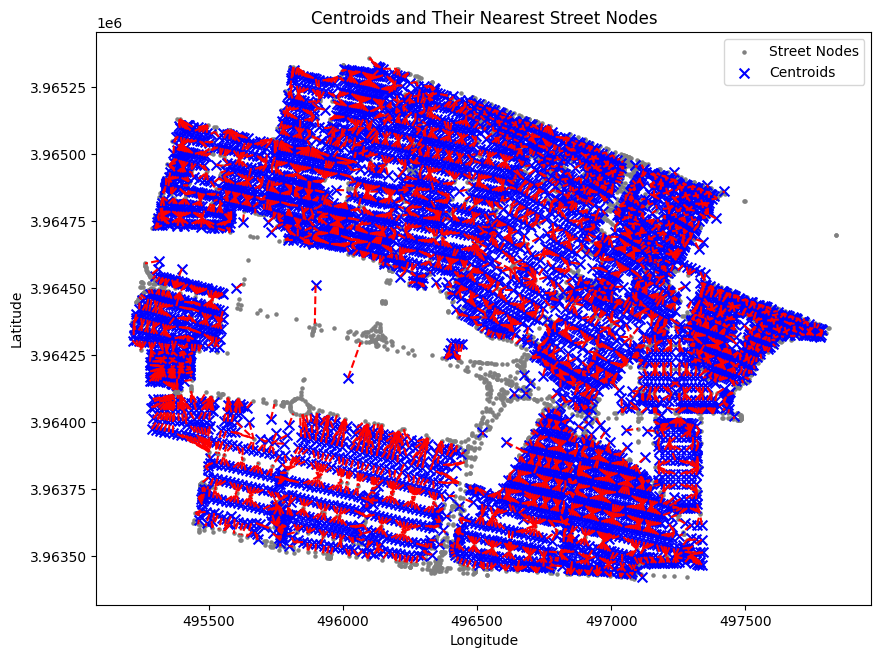

In [ ]:
street_network = nx.Graph()

def add_edges_from_line(line):
    coordinates = list(line.coords)
    for i in range(len(coordinates) - 1):
        start_point = Point(coordinates[i])
        end_point = Point(coordinates[i + 1])
        street_network.add_edge((start_point.x, start_point.y), (end_point.x, end_point.y), weight=start_point.distance(end_point))

for index, row in street_data.iterrows():
    if isinstance(row.geometry, LineString):
        add_edges_from_line(row.geometry)
    elif isinstance(row.geometry, MultiLineString):
        for line in row.geometry:
            add_edges_from_line(line)

nodes = list(street_network.nodes())
nodes_gdf = gpd.GeoDataFrame(geometry=[Point(x, y) for x, y in nodes], crs=street_data.crs)

nodes_gdf['node_id'] = range(len(nodes_gdf))


node_coords = nodes_gdf['geometry'].apply(lambda geom: (geom.x, geom.y)).tolist()
centroid_coords = centroids_gdf['centroid'].apply(lambda geom: (geom.x, geom.y)).tolist()

tree = KDTree(node_coords)
dist, idx = tree.query(centroid_coords, k=1)

centroids_gdf['nearest_node_id'] = idx.flatten()
centroids_gdf['nearest_node_geom'] = centroids_gdf['nearest_node_id'].apply(lambda i: nodes_gdf.iloc[i].geometry)

centroids_gdf.head()

fig, ax = plt.subplots(1, 1, figsize=(10, 10))

nodes_gdf.plot(ax=ax, marker='o', color='gray', markersize=5, label='Street Nodes')

centroids_gdf.plot(ax=ax, marker='x', color='blue', markersize=50, label='Centroids')

for idx, row in centroids_gdf.iterrows():
    plt.plot([row.centroid.x, row.nearest_node_geom.x], [row.centroid.y, row.nearest_node_geom.y], color='red', linestyle='--')

plt.legend()
plt.title('Centroids and Their Nearest Street Nodes')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.show()

In [ ]:
centroids_gdf

,landuse2,SHAPE_Area,centroid,nearest_node_id,nearest_node_geom
0,park,136.512665,POINT (496915.431 3964027.831),2041,POINT (496922.5059000002 3964035.3859)
1,park,1245.557294,POINT (497183.976 3964024.884),433,POINT (497167.44568414893 3964033.1890327446)
2,tejari,45.584853,POINT (496851.133 3964479.844),2316,POINT (496835.55346126296 3964457.3217535187)
3,maskooni,130.751441,POINT (496971.087 3964476.500),489,POINT (496968.60214586835 3964486.218867479)
4,tejari,30.951847,POINT (497554.328 3964266.334),288,POINT (497541.4882866964 3964279.326565519)
...,...,...,...,...,...
5792,park,2968.212275,POINT (496864.014 3964945.780),753,POINT (496882.71949999966 3964957.216499999)
5793,maskooni,125.997007,POINT (496606.894 3965063.154),1495,POINT (496613.6111932434 3965054.915243998)
5794,bayer,78996.068483,POINT (496018.950 3964163.729),2992,POINT (496066.2435999997 3964297.2091000024)
5795,tejari,116.937616,POINT (496107.713 3963699.088),1323,POINT (496099.8373999996 3963707.3340000007)


/usr/local/lib/python3.10/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


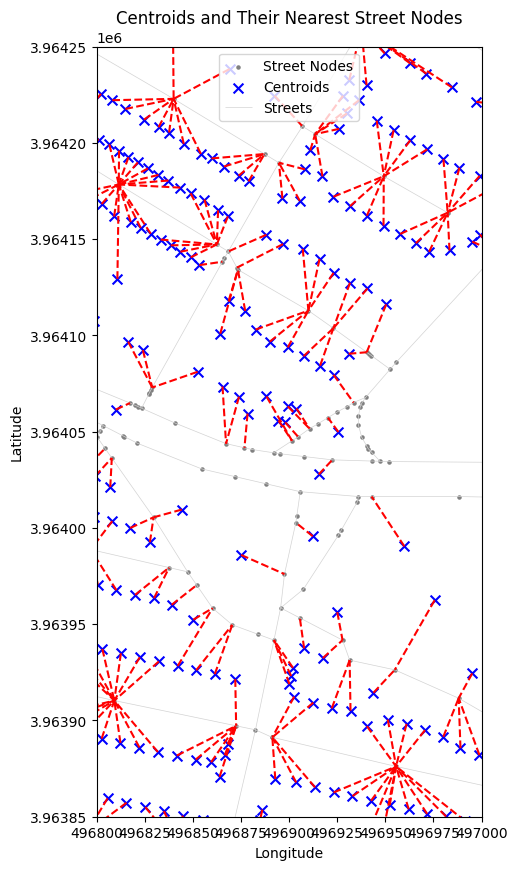

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

nodes_gdf.plot(ax=ax, marker='o', color='gray', markersize=5, label='Street Nodes')

centroids_gdf.plot(ax=ax, marker='x', color='blue', markersize=50, label='Centroids')

street_data.plot(ax=ax, color='lightgrey', linewidth=0.5, label='Streets')

for idx, row in centroids_gdf.iterrows():
    plt.plot([row.centroid.x, row.nearest_node_geom.x], [row.centroid.y, row.nearest_node_geom.y], color='red', linestyle='--')

plt.legend()
plt.title('Centroids and Their Nearest Street Nodes')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.xlim(496800, 497000)
plt.ylim(3963850, 3964250)

plt.show()

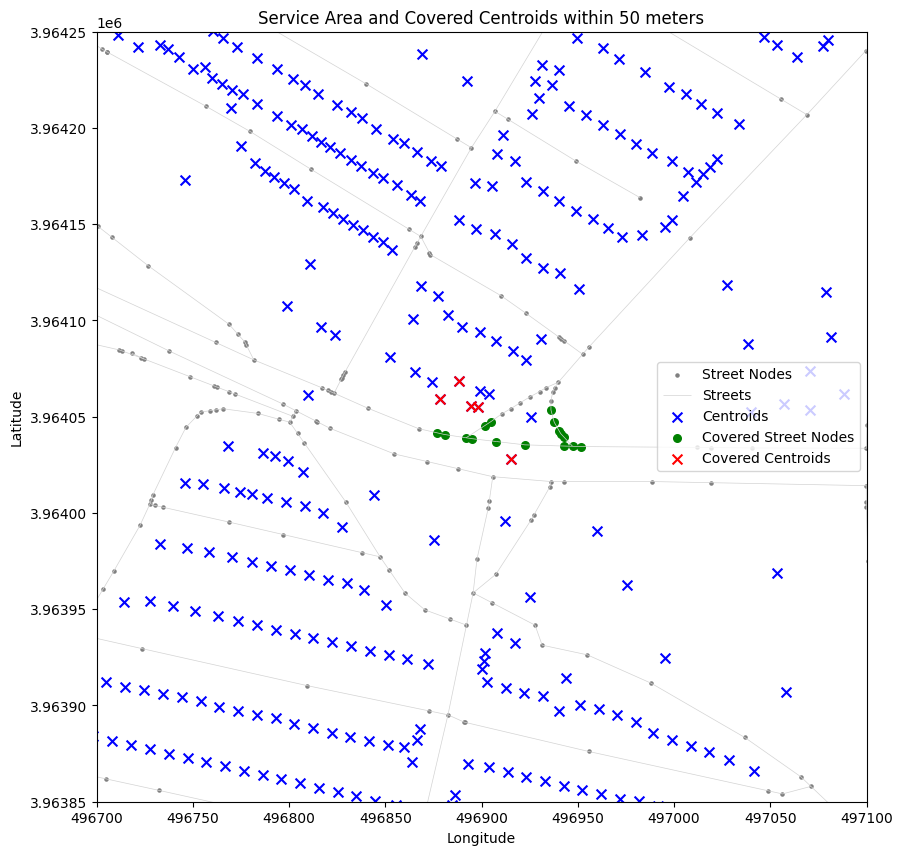

In [ ]:
# Select a sample point from centroids_gdf
sample_point = centroids_gdf.iloc[0]

nearest_node_id = sample_point['nearest_node_id']
nearest_node_geom = sample_point['nearest_node_geom']

service_area_nodes_50 = nx.single_source_dijkstra_path_length(street_network, (nearest_node_geom.x, nearest_node_geom.y), cutoff=50, weight='weight')

covered_nodes_50 = [Point(x, y) for x, y in service_area_nodes_50.keys()]

covered_nodes_gdf_50 = gpd.GeoDataFrame(geometry=covered_nodes_50, crs=nodes_gdf.crs)

covered_node_ids_50 = [nodes_gdf[nodes_gdf.geometry == node].node_id.values[0] for node in covered_nodes_gdf_50.geometry]
covered_centroids_50 = centroids_gdf[centroids_gdf['nearest_node_id'].isin(covered_node_ids_50)]

fig, ax = plt.subplots(1, 1, figsize=(10, 10))

nodes_gdf.plot(ax=ax, marker='o', color='gray', markersize=5, label='Street Nodes')

street_data.plot(ax=ax, color='lightgrey', linewidth=0.5, label='Streets')
centroids_gdf.plot(ax=ax, marker='x', color='blue', markersize=50, label='Centroids')

covered_nodes_gdf_50.plot(ax=ax, marker='o', color='green', markersize=30, label='Covered Street Nodes')

covered_centroids_50.plot(ax=ax, marker='x', color='red', markersize=50, label='Covered Centroids')

plt.legend()
plt.title('Service Area and Covered Centroids within 50 meters')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.xlim(496700, 497100)
plt.ylim(3963850, 3964250)

plt.show()

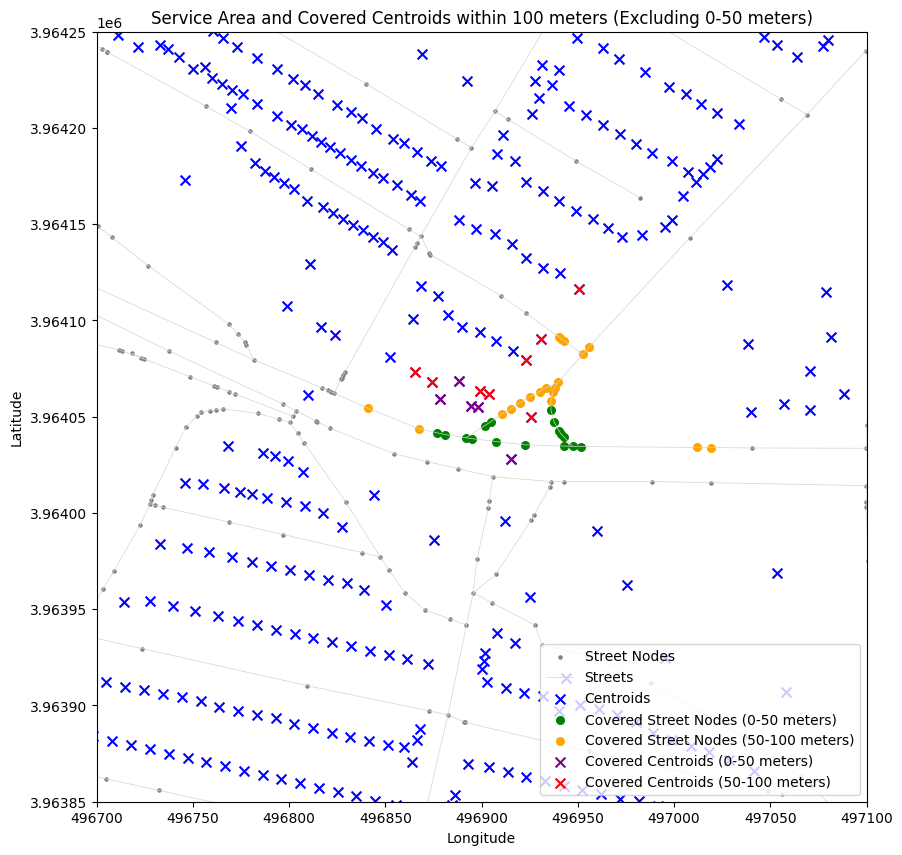

In [ ]:
# Perform a network analysis to find the service area within a 100-meter distance
service_area_nodes_100 = nx.single_source_dijkstra_path_length(street_network, (nearest_node_geom.x, nearest_node_geom.y), cutoff=100, weight='weight')

covered_nodes_100 = [Point(x, y) for x, y in service_area_nodes_100.keys()]

covered_nodes_gdf_100 = gpd.GeoDataFrame(geometry=covered_nodes_100, crs=nodes_gdf.crs)

new_covered_nodes_50_2 = set(service_area_nodes_100.keys()) - set(service_area_nodes_50.keys())
new_covered_nodes_gdf_50_2 = gpd.GeoDataFrame(geometry=[Point(x, y) for x, y in new_covered_nodes_50_2], crs=nodes_gdf.crs)

new_covered_node_ids_50_2 = [nodes_gdf[nodes_gdf.geometry == node].node_id.values[0] for node in new_covered_nodes_gdf_50_2.geometry]
new_covered_centroids_50_2 = centroids_gdf[centroids_gdf['nearest_node_id'].isin(new_covered_node_ids_50_2)]

fig, ax = plt.subplots(1, 1, figsize=(10, 10))

nodes_gdf.plot(ax=ax, marker='o', color='gray', markersize=5, label='Street Nodes')

street_data.plot(ax=ax, color='lightgrey', linewidth=0.5, label='Streets')

centroids_gdf.plot(ax=ax, marker='x', color='blue', markersize=50, label='Centroids')

covered_nodes_gdf_50.plot(ax=ax, marker='o', color='green', markersize=30, label='Covered Street Nodes (0-50 meters)')

new_covered_nodes_gdf_50_2.plot(ax=ax, marker='o', color='orange', markersize=30, label='Covered Street Nodes (50-100 meters)')

covered_centroids_50.plot(ax=ax, marker='x', color='purple', markersize=50, label='Covered Centroids (0-50 meters)')

new_covered_centroids_50_2.plot(ax=ax, marker='x', color='red', markersize=50, label='Covered Centroids (50-100 meters)')

plt.legend()
plt.title('Service Area and Covered Centroids within 100 meters (Excluding 0-50 meters)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.xlim(496700, 497100)
plt.ylim(3963850, 3964250)

plt.show()

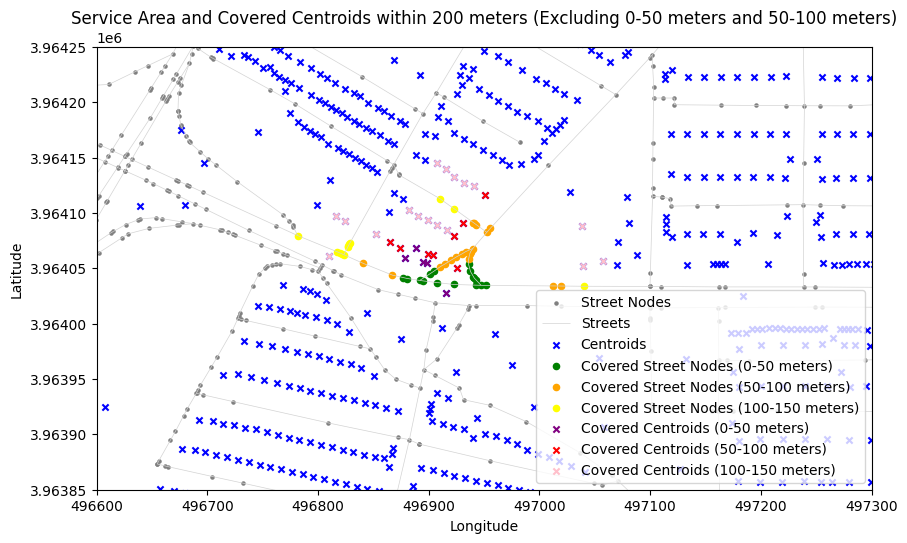

In [ ]:
# Perform a network analysis to find the service area within a 150-meter distance
service_area_nodes_150 = nx.single_source_dijkstra_path_length(street_network, (nearest_node_geom.x, nearest_node_geom.y), cutoff=150, weight='weight')

covered_nodes_150 = [Point(x, y) for x, y in service_area_nodes_150.keys()]

covered_nodes_gdf_150 = gpd.GeoDataFrame(geometry=covered_nodes_150, crs=nodes_gdf.crs)

new_covered_nodes_50_3 = set(service_area_nodes_150.keys()) - set(service_area_nodes_100.keys())
new_covered_nodes_gdf_50_3 = gpd.GeoDataFrame(geometry=[Point(x, y) for x, y in new_covered_nodes_50_3], crs=nodes_gdf.crs)

new_covered_node_ids_50_3 = [nodes_gdf[nodes_gdf.geometry == node].node_id.values[0] for node in new_covered_nodes_gdf_50_3.geometry]
new_covered_centroids_50_3 = centroids_gdf[centroids_gdf['nearest_node_id'].isin(new_covered_node_ids_50_3)]
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

nodes_gdf.plot(ax=ax, marker='o', color='gray', markersize=5, label='Street Nodes')

street_data.plot(ax=ax, color='lightgrey', linewidth=0.5, label='Streets')

centroids_gdf.plot(ax=ax, marker='x', color='blue', markersize=20, label='Centroids')

covered_nodes_gdf_50.plot(ax=ax, marker='o', color='green', markersize=20, label='Covered Street Nodes (0-50 meters)')

new_covered_nodes_gdf_50_2.plot(ax=ax, marker='o', color='orange', markersize=20, label='Covered Street Nodes (50-100 meters)')

new_covered_nodes_gdf_50_3.plot(ax=ax, marker='o', color='yellow', markersize=20, label='Covered Street Nodes (100-150 meters)')

covered_centroids_50.plot(ax=ax, marker='x', color='purple', markersize=20, label='Covered Centroids (0-50 meters)')

new_covered_centroids_50_2.plot(ax=ax, marker='x', color='red', markersize=20, label='Covered Centroids (50-100 meters)')

new_covered_centroids_50_3.plot(ax=ax, marker='x', color='pink', markersize=20, label='Covered Centroids (100-150 meters)')

plt.legend()
plt.title('Service Area and Covered Centroids within 200 meters (Excluding 0-50 meters and 50-100 meters)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.xlim(496600, 497300)
plt.ylim(3963850, 3964250)

plt.show()


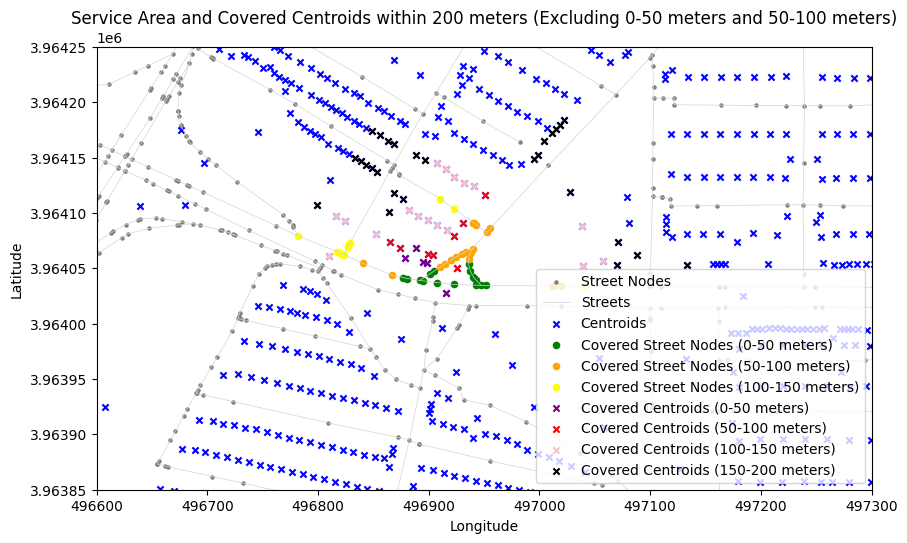

In [ ]:
# Perform a network analysis to find the service area within a 200-meter distance
service_area_nodes_200 = nx.single_source_dijkstra_path_length(street_network, (nearest_node_geom.x, nearest_node_geom.y), cutoff=200, weight='weight')

covered_nodes_200 = [Point(x, y) for x, y in service_area_nodes_200.keys()]

covered_nodes_gdf_200 = gpd.GeoDataFrame(geometry=covered_nodes_200, crs=nodes_gdf.crs)

new_covered_nodes_50_4 = set(service_area_nodes_200.keys()) - set(service_area_nodes_150.keys())
new_covered_nodes_gdf_50_4 = gpd.GeoDataFrame(geometry=[Point(x, y) for x, y in new_covered_nodes_50_4], crs=nodes_gdf.crs)

new_covered_node_ids_50_4 = [nodes_gdf[nodes_gdf.geometry == node].node_id.values[0] for node in new_covered_nodes_gdf_50_4.geometry]
new_covered_centroids_50_4 = centroids_gdf[centroids_gdf['nearest_node_id'].isin(new_covered_node_ids_50_4)]

fig, ax = plt.subplots(1, 1, figsize=(10, 10))

nodes_gdf.plot(ax=ax, marker='o', color='gray', markersize=5, label='Street Nodes')

street_data.plot(ax=ax, color='lightgrey', linewidth=0.5, label='Streets')

centroids_gdf.plot(ax=ax, marker='x', color='blue', markersize=20, label='Centroids')

covered_nodes_gdf_50.plot(ax=ax, marker='o', color='green', markersize=20, label='Covered Street Nodes (0-50 meters)')

new_covered_nodes_gdf_50_2.plot(ax=ax, marker='o', color='orange', markersize=20, label='Covered Street Nodes (50-100 meters)')

new_covered_nodes_gdf_50_3.plot(ax=ax, marker='o', color='yellow', markersize=20, label='Covered Street Nodes (100-150 meters)')

covered_centroids_50.plot(ax=ax, marker='x', color='purple', markersize=20, label='Covered Centroids (0-50 meters)')

new_covered_centroids_50_2.plot(ax=ax, marker='x', color='red', markersize=20, label='Covered Centroids (50-100 meters)')

new_covered_centroids_50_3.plot(ax=ax, marker='x', color='pink', markersize=20, label='Covered Centroids (100-150 meters)')

new_covered_centroids_50_4.plot(ax=ax, marker='x', color='black', markersize=20, label='Covered Centroids (150-200 meters)')

plt.legend()
plt.title('Service Area and Covered Centroids within 200 meters (Excluding 0-50 meters and 50-100 meters)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.xlim(496600, 497300)
plt.ylim(3963850, 3964250)

plt.show()


In [ ]:
sample_data = {
    "sample_centroid": {
        "geometry": sample_point.centroid,
        "attributes": sample_point.to_dict(),
        "covered_ranges": {
            "0-50 meters": {
                "centroids": [],
                "attributes": []
            },
            "50-100 meters": {
                "centroids": [],
                "attributes": []
            },
            "100-150 meters": {
                "centroids": [],
                "attributes": []
            },
            "150-200 meters": {
            "centroids": [],
            "attributes": []
            }
        }
    }
}

sample_data["sample_centroid"]["covered_ranges"]["0-50 meters"]["centroids"] = covered_centroids_50['centroid'].tolist()
sample_data["sample_centroid"]["covered_ranges"]["0-50 meters"]["attributes"] = covered_centroids_50.drop(columns='centroid').to_dict('records')

sample_data["sample_centroid"]["covered_ranges"]["50-100 meters"]["centroids"] = new_covered_centroids_50_2['centroid'].tolist()
sample_data["sample_centroid"]["covered_ranges"]["50-100 meters"]["attributes"] = new_covered_centroids_50_2.drop(columns='centroid').to_dict('records')


sample_data["sample_centroid"]["covered_ranges"]["100-150 meters"]["centroids"] = new_covered_centroids_50_3['centroid'].tolist()
sample_data["sample_centroid"]["covered_ranges"]["100-150 meters"]["attributes"] = new_covered_centroids_50_3.drop(columns='centroid').to_dict('records')

sample_data["sample_centroid"]["covered_ranges"]["150-200 meters"]["centroids"] = new_covered_centroids_50_4['centroid'].tolist()
sample_data["sample_centroid"]["covered_ranges"]["150-200 meters"]["attributes"] = new_covered_centroids_50_4.drop(columns='centroid').to_dict('records')

sample_data

{'sample_centroid': {'geometry': <POINT (496915.431 3964027.831)>,
  'attributes': {'landuse2': 'park',
   'SHAPE_Area': 136.512664915,
   'centroid': <POINT (496915.431 3964027.831)>,
   'nearest_node_id': 2041,
   'nearest_node_geom': <POINT (496922.506 3964035.386)>},
  'covered_ranges': {'0-50 meters': {'centroids': [<POINT (496915.431 3964027.831)>,
     <POINT (496888.294 3964068.3)>,
     <POINT (496894.506 3964055.823)>,
     <POINT (496878.462 3964059.421)>,
     <POINT (496898.039 3964054.841)>],
    'attributes': [{'landuse2': 'park',
      'SHAPE_Area': 136.512664915,
      'nearest_node_id': 2041,
      'nearest_node_geom': <POINT (496922.506 3964035.386)>},
     {'landuse2': 'maskooni',
      'SHAPE_Area': 305.705513978,
      'nearest_node_id': 2038,
      'nearest_node_geom': <POINT (496901.547 3964045.288)>},
     {'landuse2': 'tejari',
      'SHAPE_Area': 20.3319021153,
      'nearest_node_id': 2038,
      'nearest_node_geom': <POINT (496901.547 3964045.288)>},
     {

In [ ]:
sample_centroids_gdf = centroids_gdf.iloc[:50].reset_index(drop=True)

In [ ]:
sample_50_centroids_data = {}

for idx, sample_point in tqdm(sample_centroids_gdf.iterrows(), total=sample_centroids_gdf.shape[0], desc="Processing Centroids"):
    nearest_node_id = sample_point['nearest_node_id']
    nearest_node_geom = sample_point['nearest_node_geom']

    centroid_data = {
        "centroid": sample_point.centroid,
        "attributes": sample_point.to_dict(),
        "covered_ranges": {
            "0-50 meters": {
                "centroids": [],
                "attributes": []
            },
            "50-100 meters": {
                "centroids": [],
                "attributes": []
            },
            "100-150 meters": {
                "centroids": [],
                "attributes": []
            },
            "150-200 meters": {
            "centroids": [],
            "attributes": []
            }
        }
    }

    service_area_nodes_50 = nx.single_source_dijkstra_path_length(street_network, (nearest_node_geom.x, nearest_node_geom.y), cutoff=50, weight='weight')

    covered_nodes_50 = [Point(x, y) for x, y in service_area_nodes_50.keys()]
    covered_nodes_gdf_50 = gpd.GeoDataFrame(geometry=covered_nodes_50, crs=nodes_gdf.crs)
    covered_node_ids_50 = [nodes_gdf[nodes_gdf.geometry == node].node_id.values[0] for node in covered_nodes_gdf_50.geometry]
    covered_centroids_50 = centroids_gdf[centroids_gdf['nearest_node_id'].isin(covered_node_ids_50)]

    centroid_data["covered_ranges"]["0-50 meters"]["centroids"] = covered_centroids_50['centroid'].tolist()
    centroid_data["covered_ranges"]["0-50 meters"]["attributes"] = covered_centroids_50.drop(columns='centroid').to_dict('records')

    service_area_nodes_100 = nx.single_source_dijkstra_path_length(street_network, (nearest_node_geom.x, nearest_node_geom.y), cutoff=100, weight='weight')
    covered_nodes_100 = [Point(x, y) for x, y in service_area_nodes_100.keys()]
    covered_nodes_gdf_100 = gpd.GeoDataFrame(geometry=covered_nodes_100, crs=nodes_gdf.crs)
    new_covered_nodes_50_2 = set(service_area_nodes_100.keys()) - set(service_area_nodes_50.keys())
    new_covered_nodes_gdf_50_2 = gpd.GeoDataFrame(geometry=[Point(x, y) for x, y in new_covered_nodes_50_2], crs=nodes_gdf.crs)
    new_covered_node_ids_50_2 = [nodes_gdf[nodes_gdf.geometry == node].node_id.values[0] for node in new_covered_nodes_gdf_50_2.geometry]
    new_covered_centroids_50_2 = centroids_gdf[centroids_gdf['nearest_node_id'].isin(new_covered_node_ids_50_2)]

    centroid_data["covered_ranges"]["50-100 meters"]["centroids"] = new_covered_centroids_50_2['centroid'].tolist()
    centroid_data["covered_ranges"]["50-100 meters"]["attributes"] = new_covered_centroids_50_2.drop(columns='centroid').to_dict('records')

    service_area_nodes_150 = nx.single_source_dijkstra_path_length(street_network, (nearest_node_geom.x, nearest_node_geom.y), cutoff=150, weight='weight')
    covered_nodes_150 = [Point(x, y) for x, y in service_area_nodes_150.keys()]
    covered_nodes_gdf_150 = gpd.GeoDataFrame(geometry=covered_nodes_150, crs=nodes_gdf.crs)
    new_covered_nodes_50_3 = set(service_area_nodes_150.keys()) - set(service_area_nodes_100.keys())
    new_covered_nodes_gdf_50_3 = gpd.GeoDataFrame(geometry=[Point(x, y) for x, y in new_covered_nodes_50_3], crs=nodes_gdf.crs)
    new_covered_node_ids_50_3 = [nodes_gdf[nodes_gdf.geometry == node].node_id.values[0] for node in new_covered_nodes_gdf_50_3.geometry]
    new_covered_centroids_50_3 = centroids_gdf[centroids_gdf['nearest_node_id'].isin(new_covered_node_ids_50_3)]

    centroid_data["covered_ranges"]["100-150 meters"]["centroids"] = new_covered_centroids_50_3['centroid'].tolist()
    centroid_data["covered_ranges"]["100-150 meters"]["attributes"] = new_covered_centroids_50_3.drop(columns='centroid').to_dict('records')

    service_area_nodes_200 = nx.single_source_dijkstra_path_length(street_network, (nearest_node_geom.x, nearest_node_geom.y), cutoff=200, weight='weight')
    covered_nodes_200 = [Point(x, y) for x, y in service_area_nodes_200.keys()]
    covered_nodes_gdf_200 = gpd.GeoDataFrame(geometry=covered_nodes_200, crs=nodes_gdf.crs)
    new_covered_nodes_50_4 = set(service_area_nodes_200.keys()) - set(service_area_nodes_150.keys())
    new_covered_nodes_gdf_50_4 = gpd.GeoDataFrame(geometry=[Point(x, y) for x, y in new_covered_nodes_50_4], crs=nodes_gdf.crs)
    new_covered_node_ids_50_4 = [nodes_gdf[nodes_gdf.geometry == node].node_id.values[0] for node in new_covered_nodes_gdf_50_4.geometry]
    new_covered_centroids_50_4 = centroids_gdf[centroids_gdf['nearest_node_id'].isin(new_covered_node_ids_50_4)]

    centroid_data["covered_ranges"]["150-200 meters"]["centroids"] = new_covered_centroids_50_4['centroid'].tolist()
    centroid_data["covered_ranges"]["150-200 meters"]["attributes"] = new_covered_centroids_50_4.drop(columns='centroid').to_dict('records')

    sample_50_centroids_data[idx] = centroid_data

Processing Centroids:   0%|          | 0/50 [00:00<?, ?it/s]

In [ ]:
sample_50_centroids_list = []
for idx, data in sample_50_centroids_data.items():
    for range_key, range_data in data["covered_ranges"].items():
        for centroid, attributes in zip(range_data["centroids"], range_data["attributes"]):
            sample_50_centroids_list.append({
                "sample_centroid_id": idx,
                "range": range_key,
                "centroid": centroid,
                **attributes
            })

sample_50_centroids_gdf = gpd.GeoDataFrame(sample_50_centroids_list, geometry="centroid", crs=centroids_gdf.crs)

print(json.dumps(sample_50_centroids_data, indent=2, default=str))

{
  "0": {
    "centroid": "POINT (496915.4313161598 3964027.8308834927)",
    "attributes": {
      "landuse2": "park",
      "SHAPE_Area": 136.512664915,
      "centroid": "POINT (496915.4313161598 3964027.8308834927)",
      "nearest_node_id": 2041,
      "nearest_node_geom": "POINT (496922.5059000002 3964035.3859)"
    },
    "covered_ranges": {
      "0-50 meters": {
        "centroids": [
          "POINT (496915.4313161598 3964027.8308834927)",
          "POINT (496888.29435444454 3964068.3003460094)",
          "POINT (496894.50556107453 3964055.823443484)",
          "POINT (496878.46196244855 3964059.4214736377)",
          "POINT (496898.0394792948 3964054.8414733433)"
        ],
        "attributes": [
          {
            "landuse2": "park",
            "SHAPE_Area": 136.512664915,
            "nearest_node_id": 2041,
            "nearest_node_geom": "POINT (496922.5059000002 3964035.3859)"
          },
          {
            "landuse2": "maskooni",
            "SHAPE_

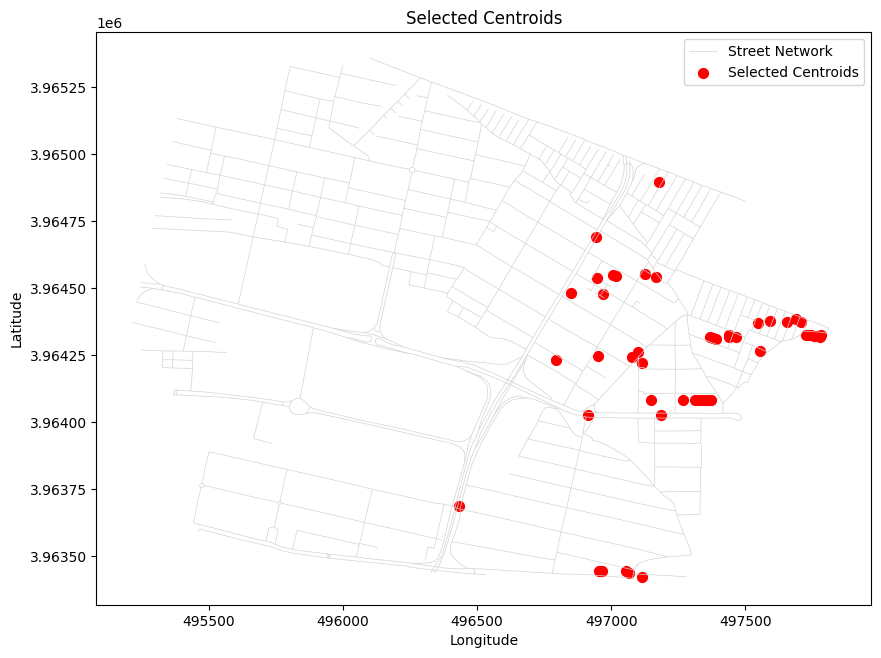

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

street_data.plot(ax=ax, color='lightgrey', linewidth=0.5, label='Street Network')

sample_centroids_gdf.plot(ax=ax, marker='o', color='red', markersize=50, label='Selected Centroids')

plt.legend()
plt.title('Selected Centroids')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

In [ ]:
# Filter the sample_50_centroids_data to select only those with landuse2 as "maskooni"
maskooni_centroids_data = {idx: data for idx, data in sample_50_centroids_data.items() if data["attributes"]["landuse2"] == "maskooni"}

maskooni_centroids_list = []
for idx, data in maskooni_centroids_data.items():
    for range_key, range_data in data["covered_ranges"].items():
        for centroid, attributes in zip(range_data["centroids"], range_data["attributes"]):
            maskooni_centroids_list.append({
                "sample_centroid_id": idx,
                "range": range_key,
                "centroid": centroid,
                **attributes
            })

maskooni_centroids_gdf = gpd.GeoDataFrame(maskooni_centroids_list, geometry="centroid", crs=centroids_gdf.crs)

print(json.dumps(maskooni_centroids_data, indent=2, default=str))


{
  "3": {
    "centroid": "POINT (496971.0869725971 3964476.499816325)",
    "attributes": {
      "landuse2": "maskooni",
      "SHAPE_Area": 130.751440808,
      "centroid": "POINT (496971.0869725971 3964476.499816325)",
      "nearest_node_id": 489,
      "nearest_node_geom": "POINT (496968.60214586835 3964486.218867479)"
    },
    "covered_ranges": {
      "0-50 meters": {
        "centroids": [
          "POINT (496971.0869725971 3964476.499816325)",
          "POINT (496953.6597575492 3964486.6659798333)",
          "POINT (497005.58985022333 3964487.269622818)",
          "POINT (496947.79037316033 3964490.10014167)",
          "POINT (496931.6541777231 3964475.15621382)",
          "POINT (496973.8534510251 3964450.4079790437)",
          "POINT (496967.19175091194 3964452.682765011)",
          "POINT (497001.46436093905 3964444.0303340093)",
          "POINT (496924.4235990703 3964442.1709107575)",
          "POINT (496961.491985963 3964456.1728004045)",
          "POINT (4

In [ ]:
# Define the land use labels of interest
landuse_labels_maskooni = ["tejari", 'khadamati', 'maskooni', 'sanati', 'park']

landuse_counts_maskooni = {}

for idx, data in maskooni_centroids_data.items():
    central_landuse = data['attributes'].get('landuse2')

    centroid_landuse_counts = {
        "central_landuse": central_landuse,
        "0-50 meters": {label: 0 for label in landuse_labels_maskooni},
        "50-100 meters": {label: 0 for label in landuse_labels_maskooni},
        "100-150 meters": {label: 0 for label in landuse_labels_maskooni},
        "150-200 meters": {label: 0 for label in landuse_labels_maskooni}
    }

    for attributes in data["covered_ranges"]["0-50 meters"]["attributes"]:
        landuse = attributes.get('landuse2')
        if landuse in landuse_labels_maskooni:
            centroid_landuse_counts["0-50 meters"][landuse] += 1

    for attributes in data["covered_ranges"]["50-100 meters"]["attributes"]:
        landuse = attributes.get('landuse2')
        if landuse in landuse_labels_maskooni:
            centroid_landuse_counts["50-100 meters"][landuse] += 1

    for attributes in data["covered_ranges"]["100-150 meters"]["attributes"]:
        landuse = attributes.get('landuse2')
        if landuse in landuse_labels_maskooni:
            centroid_landuse_counts["100-150 meters"][landuse] += 1
    for attributes in data["covered_ranges"]["150-200 meters"]["attributes"]:
        landuse = attributes.get('landuse2')
        if landuse in landuse_labels_maskooni:
            centroid_landuse_counts["150-200 meters"][landuse] += 1

    landuse_counts_maskooni[idx] = centroid_landuse_counts

print(json.dumps(landuse_counts_maskooni, indent=2))


{
  "3": {
    "central_landuse": "maskooni",
    "0-50 meters": {
      "tejari": 1,
      "khadamati": 1,
      "maskooni": 30,
      "sanati": 0,
      "park": 0
    },
    "50-100 meters": {
      "tejari": 4,
      "khadamati": 2,
      "maskooni": 16,
      "sanati": 0,
      "park": 0
    },
    "100-150 meters": {
      "tejari": 5,
      "khadamati": 4,
      "maskooni": 11,
      "sanati": 0,
      "park": 0
    },
    "150-200 meters": {
      "tejari": 14,
      "khadamati": 4,
      "maskooni": 28,
      "sanati": 1,
      "park": 0
    }
  },
  "5": {
    "central_landuse": "maskooni",
    "0-50 meters": {
      "tejari": 4,
      "khadamati": 0,
      "maskooni": 25,
      "sanati": 0,
      "park": 0
    },
    "50-100 meters": {
      "tejari": 2,
      "khadamati": 2,
      "maskooni": 20,
      "sanati": 0,
      "park": 0
    },
    "100-150 meters": {
      "tejari": 14,
      "khadamati": 0,
      "maskooni": 26,
      "sanati": 0,
      "park": 0
    },
    "150-

In [ ]:
# Define the land use labels of interest
landuse_labels = ['tejari', 'khadamati', 'maskooni', 'sanati', 'park']

def calculate_total_landuse_counts(landuse_counts, central_label):
    total_landuse_counts = {
        "0-50 meters": {label: 0 for label in landuse_labels},
        "50-100 meters": {label: 0 for label in landuse_labels},
        "100-150 meters": {label: 0 for label in landuse_labels},
        "150-200 meters": {label: 0 for label in landuse_labels}
    }

    for idx, centroid_counts in landuse_counts.items():
        central_centroid_label = centroid_counts.get("central_landuse")

        if central_centroid_label != central_label:
            continue

        for label in landuse_labels:
            total_landuse_counts["0-50 meters"][label] += centroid_counts["0-50 meters"].get(label, 0)

        for label in landuse_labels:
            total_landuse_counts["50-100 meters"][label] += centroid_counts["50-100 meters"].get(label, 0)

        for label in landuse_labels:
            total_landuse_counts["100-150 meters"][label] += centroid_counts["100-150 meters"].get(label, 0)

        for label in landuse_labels:
            total_landuse_counts["150-200 meters"][label] += centroid_counts["150-200 meters"].get(label, 0)

    return total_landuse_counts

total_landuse_counts_maskooni = calculate_total_landuse_counts(landuse_counts_maskooni, "maskooni")

print(json.dumps(total_landuse_counts_maskooni, indent=2))

{
  "0-50 meters": {
    "tejari": 65,
    "khadamati": 9,
    "maskooni": 392,
    "sanati": 1,
    "park": 0
  },
  "50-100 meters": {
    "tejari": 137,
    "khadamati": 18,
    "maskooni": 338,
    "sanati": 1,
    "park": 4
  },
  "100-150 meters": {
    "tejari": 249,
    "khadamati": 18,
    "maskooni": 664,
    "sanati": 3,
    "park": 11
  },
  "150-200 meters": {
    "tejari": 372,
    "khadamati": 19,
    "maskooni": 956,
    "sanati": 11,
    "park": 13
  }
}


In [ ]:
tejari_centroids_data = {idx: data for idx, data in sample_50_centroids_data.items() if data["attributes"]["landuse2"] == "tejari"}

tejari_centroids_list = []
for idx, data in tejari_centroids_data.items():
    for range_key, range_data in data["covered_ranges"].items():
        for centroid, attributes in zip(range_data["centroids"], range_data["attributes"]):
            tejari_centroids_list.append({
                "sample_centroid_id": idx,
                "range": range_key,
                "centroid": centroid,
                **attributes
            })

tejari_centroids_gdf = gpd.GeoDataFrame(tejari_centroids_list, geometry="centroid", crs=centroids_gdf.crs)

In [ ]:
def count_landuse_within_ranges(centroids_data, landuse_labels):
    """
    Count the occurrences of specific land use labels within specified distance ranges for each centroid.

    Parameters:
    centroids_data (dict): A dictionary containing centroids and their attributes.
    landuse_labels (list): A list of land use labels to count.

    Returns:
    dict: A dictionary containing the counts of land use labels for each centroid and each distance range.
    """
    landuse_counts = {}

    for idx, data in centroids_data.items():
        central_landuse = data['attributes'].get('landuse2')

        centroid_landuse_counts = {
            "central_landuse": central_landuse,
            "0-50 meters": {label: 0 for label in landuse_labels},
            "50-100 meters": {label: 0 for label in landuse_labels},
            "100-150 meters": {label: 0 for label in landuse_labels},
            "150-200 meters": {label: 0 for label in landuse_labels}
        }

        for attributes in data["covered_ranges"]["0-50 meters"]["attributes"]:
            landuse = attributes.get('landuse2')
            if landuse in landuse_labels:
                centroid_landuse_counts["0-50 meters"][landuse] += 1

        for attributes in data["covered_ranges"]["50-100 meters"]["attributes"]:
            landuse = attributes.get('landuse2')
            if landuse in landuse_labels:
                centroid_landuse_counts["50-100 meters"][landuse] += 1

        for attributes in data["covered_ranges"]["100-150 meters"]["attributes"]:
            landuse = attributes.get('landuse2')
            if landuse in landuse_labels:
                centroid_landuse_counts["100-150 meters"][landuse] += 1

        for attributes in data["covered_ranges"]["150-200 meters"]["attributes"]:
            landuse = attributes.get('landuse2')
            if landuse in landuse_labels:
                centroid_landuse_counts["150-200 meters"][landuse] += 1

        landuse_counts[idx] = centroid_landuse_counts

    return landuse_counts

landuse_labels_tejari = ["tejari", 'khadamati', 'maskooni', 'sanati', 'park']
tejari_landuse_counts = count_landuse_within_ranges(tejari_centroids_data, landuse_labels_tejari)

In [ ]:
total_landuse_counts_tejari = calculate_total_landuse_counts(tejari_landuse_counts, "tejari")
print(json.dumps(total_landuse_counts_tejari, indent=2))

{
  "0-50 meters": {
    "tejari": 83,
    "khadamati": 7,
    "maskooni": 75,
    "sanati": 6,
    "park": 1
  },
  "50-100 meters": {
    "tejari": 72,
    "khadamati": 3,
    "maskooni": 177,
    "sanati": 0,
    "park": 5
  },
  "100-150 meters": {
    "tejari": 122,
    "khadamati": 13,
    "maskooni": 219,
    "sanati": 0,
    "park": 5
  },
  "150-200 meters": {
    "tejari": 166,
    "khadamati": 11,
    "maskooni": 365,
    "sanati": 5,
    "park": 7
  }
}


In [ ]:
maskooni_centroids_gdf

,sample_centroid_id,range,centroid,landuse2,SHAPE_Area,nearest_node_id,nearest_node_geom
0,3,0-50 meters,POINT (496971.087 3964476.500),maskooni,130.751441,489,POINT (496968.60214586835 3964486.218867479)
1,3,0-50 meters,POINT (496953.660 3964486.666),maskooni,116.587877,430,POINT (496958.59720000066 3964500.557400001)
2,3,0-50 meters,POINT (497005.590 3964487.270),maskooni,134.821912,490,POINT (497000.8127999995 3964475.0270000026)
3,3,0-50 meters,POINT (496947.790 3964490.100),maskooni,111.368460,478,POINT (496939.5454000002 3964482.0743000023)
4,3,0-50 meters,POINT (496931.654 3964475.156),maskooni,142.633297,478,POINT (496939.5454000002 3964482.0743000023)
...,...,...,...,...,...,...,...
3332,49,150-200 meters,POINT (496961.961 3964648.854),tejari,37.203478,2980,POINT (496934.3800530182 3964667.1032521296)
3333,49,150-200 meters,POINT (496963.638 3964651.294),tejari,54.455833,2980,POINT (496934.3800530182 3964667.1032521296)
3334,49,150-200 meters,POINT (496965.392 3964654.007),tejari,45.303171,2980,POINT (496934.3800530182 3964667.1032521296)
3335,49,150-200 meters,POINT (496965.563 3964660.623),tejari,189.155769,2980,POINT (496934.3800530182 3964667.1032521296)


In [ ]:
distance_ranges = ['0-50 meters', '50-100 meters', '100-150 meters', '150-200 meters']

filtered_gdf = maskooni_centroids_gdf[maskooni_centroids_gdf['landuse2'] != 'bayer']
total_area_per_range = filtered_gdf.groupby('range')['SHAPE_Area'].sum().to_dict()
grouped_area = filtered_gdf.groupby(['range', 'landuse2'])['SHAPE_Area'].sum().unstack(fill_value=0)

labels_of_interest = ['maskooni', 'tejari', 'sanati', 'park', 'khadamati']

area_per_label_per_range = {
    range_key: {label: 0 for label in labels_of_interest}
    for range_key in distance_ranges
}

for range_key in distance_ranges:
    range_gdf = maskooni_centroids_gdf[maskooni_centroids_gdf['range'] == range_key]
    for label in labels_of_interest:
        label_gdf = range_gdf[range_gdf['landuse2'] == label]
        area_per_label_per_range[range_key][label] = label_gdf['SHAPE_Area'].sum()

print(f"Area of each label in each distance range: {json.dumps(area_per_label_per_range, indent=2)}")


Area of each label in each distance range: {
  "0-50 meters": {
    "maskooni": 93597.56087053841,
    "tejari": 4400.84900889326,
    "sanati": 24.756378846,
    "park": 0.0,
    "khadamati": 14096.659690506001
  },
  "50-100 meters": {
    "maskooni": 78083.46289993971,
    "tejari": 7592.088885001131,
    "sanati": 246.442979623,
    "park": 3936.838608138,
    "khadamati": 25447.848384915804
  },
  "100-150 meters": {
    "maskooni": 146225.8240185543,
    "tejari": 10445.732277685649,
    "sanati": 1520.6800818880001,
    "park": 7165.4489538344005,
    "khadamati": 15762.749020529
  },
  "150-200 meters": {
    "maskooni": 218215.5976936082,
    "tejari": 20733.5846301221,
    "sanati": 388.3883053851,
    "park": 10994.244961184997,
    "khadamati": 16446.4517045269
  }
}


In [ ]:
total_area_per_label = filtered_gdf.groupby('landuse2')['SHAPE_Area'].sum().to_dict()
total_area_whole = maskooni_centroids_gdf['SHAPE_Area'].sum()

print(f"Total area of each land use label: {total_area_per_label}")
print(f"Total area of the whole area: {total_area_whole}")

Total area of each land use label: {'khadamati': 71753.7088004777, 'maskooni': 536122.4454826406, 'park': 22096.5325231574, 'sanati': 2180.2677457421, 'tejari': 43172.25480170214}
Total area of the whole area: 703528.5163961728


In [ ]:
enrichment_factors = {
    range_key: {label: 0 for label in labels_of_interest}
    for range_key in distance_ranges
}
for range_key in distance_ranges:
    total_area_range = total_area_per_range.get(range_key, 0)
    for label in labels_of_interest:
        area_label_range = grouped_area.at[range_key, label] if range_key in grouped_area.index else 0
        area_label_whole = total_area_per_label.get(label, 0)

        if total_area_range > 0 and total_area_whole > 0 and area_label_whole > 0:
            ef = (area_label_range / total_area_range) / (area_label_whole / total_area_whole)
            enrichment_factors[range_key][label] = ef

print(f"Enrichment factors: {json.dumps(enrichment_factors, indent=2)}"
)

Enrichment factors: {
  "0-50 meters": {
    "maskooni": 1.0954683435808679,
    "tejari": 0.6396332439316209,
    "sanati": 0.07124864029507764,
    "park": 0.0,
    "khadamati": 1.2327390467539545
  },
  "50-100 meters": {
    "maskooni": 0.8886327333637851,
    "tejari": 1.0729606221139165,
    "sanati": 0.68965811716957,
    "park": 1.0870529889168572,
    "khadamati": 2.1638838521706854
  },
  "100-150 meters": {
    "maskooni": 1.0594350625079019,
    "tejari": 0.9398280736334683,
    "sanati": 2.70920758016458,
    "park": 1.2596025559367783,
    "khadamati": 0.8533002274889466
  },
  "150-200 meters": {
    "maskooni": 1.0733789105465334,
    "tejari": 1.266487536394427,
    "sanati": 0.4697724811301792,
    "park": 1.3121169308736993,
    "khadamati": 0.6044482413444551
  }
}


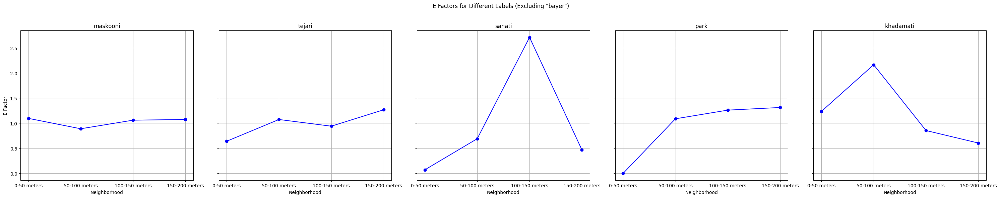

In [ ]:
neighborhoods = distance_ranges

num_labels = len(labels_of_interest)
fig, axes = plt.subplots(nrows=1, ncols=num_labels, figsize=(30, 6), sharey=True)

for ax, label in zip(axes, labels_of_interest):
    e_factors = [enrichment_factors[neighborhood][label] for neighborhood in neighborhoods]

    ax.plot(neighborhoods, e_factors, marker='o', linestyle='-', color='b')
    ax.set_xlabel('Neighborhood')
    ax.set_title(f'{label}')
    ax.grid(True)

axes[0].set_ylabel('E Factor')
fig.suptitle('E Factors for Different Labels (Excluding "bayer")')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
log_enrichment_factors = {
    range_key: {label: np.log(enrichment_factors[range_key][label]) if enrichment_factors[range_key][label] > 0 else 0 for label in labels_of_interest}
    for range_key in distance_ranges
}

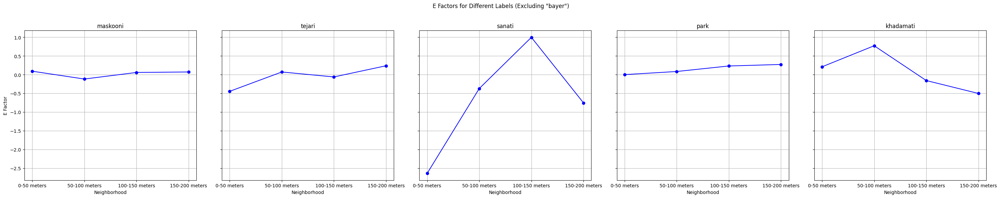

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=num_labels, figsize=(30, 6), sharey=True)

for ax, label in zip(axes, labels_of_interest):
    e_factors = [log_enrichment_factors[neighborhood][label] for neighborhood in neighborhoods]

    ax.plot(neighborhoods, e_factors, marker='o', linestyle='-', color='b')
    ax.set_xlabel('Neighborhood')
    ax.set_title(f'{label}')
    ax.grid(True)

axes[0].set_ylabel('E Factor')
fig.suptitle('E Factors for Different Labels (Excluding "bayer")')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
tejari_centroids_data = {idx: data for idx, data in sample_50_centroids_data.items() if data["attributes"]["landuse2"] == "tejari"}

tejari_filtered_gdf = tejari_centroids_gdf[tejari_centroids_gdf['landuse2'] != 'bayer']
tejari_total_area_per_range = tejari_filtered_gdf.groupby('range')['SHAPE_Area'].sum().to_dict()
tejari_grouped_area = tejari_filtered_gdf.groupby(['range', 'landuse2'])['SHAPE_Area'].sum().unstack(fill_value=0)

tejari_area_per_label_per_range = {
    range_key: {label: 0 for label in labels_of_interest}
    for range_key in distance_ranges
}

for range_key in distance_ranges:
    range_gdf = tejari_centroids_gdf[tejari_centroids_gdf['range'] == range_key]
    for label in labels_of_interest:
        label_gdf = range_gdf[range_gdf['landuse2'] == label]
        tejari_area_per_label_per_range[range_key][label] = label_gdf['SHAPE_Area'].sum()

print(f"Area of each label in each distance range: {json.dumps(tejari_area_per_label_per_range, indent=2)}")


Area of each label in each distance range: {
  "0-50 meters": {
    "maskooni": 18201.6588835962,
    "tejari": 7819.235222867201,
    "sanati": 364.0379347251,
    "park": 304.947719819,
    "khadamati": 2850.3766661297004
  },
  "50-100 meters": {
    "maskooni": 54308.6940579948,
    "tejari": 4764.897705801,
    "sanati": 0.0,
    "park": 4321.305056767,
    "khadamati": 1618.889084323
  },
  "100-150 meters": {
    "maskooni": 68819.128582983,
    "tejari": 7743.869069383501,
    "sanati": 0.0,
    "park": 20189.074451788,
    "khadamati": 10046.531779624002
  },
  "150-200 meters": {
    "maskooni": 96997.7095706469,
    "tejari": 10928.34521979533,
    "sanati": 176.34368992499998,
    "park": 11207.169589059999,
    "khadamati": 3901.3848600791
  }
}


In [ ]:
tejari_total_area_per_label = tejari_filtered_gdf.groupby('landuse2')['SHAPE_Area'].sum().to_dict()
tejari_total_area_whole = tejari_centroids_gdf['SHAPE_Area'].sum()

print(f"Total area of each land use label: {tejari_total_area_per_label}")
print(f"Total area of the whole area: {tejari_total_area_whole}")

Total area of each land use label: {'khadamati': 18417.182390155802, 'maskooni': 238327.1910952209, 'park': 36022.496817434, 'sanati': 540.3816246501001, 'tejari': 31256.34721784703}
Total area of the whole area: 347544.76237315993


In [ ]:
tejari_enrichment_factors = {
    range_key: {label: 0 for label in labels_of_interest}
    for range_key in distance_ranges
}
for range_key in distance_ranges:
    tejari_total_area_range = tejari_total_area_per_range.get(range_key, 0)
    for label in labels_of_interest:
        tejari_area_label_range = tejari_grouped_area.at[range_key, label] if range_key in tejari_grouped_area.index else 0
        tejari_area_label_whole = tejari_total_area_per_label.get(label, 0)

        if tejari_total_area_range > 0 and tejari_total_area_whole > 0 and tejari_area_label_whole > 0:
            tejari_ef = (tejari_area_label_range / tejari_total_area_range) / (tejari_area_label_whole / tejari_total_area_whole)
            tejari_enrichment_factors[range_key][label] = tejari_ef

print(f"Enrichment factors: {json.dumps(tejari_enrichment_factors, indent=2)}"
)

Enrichment factors: {
  "0-50 meters": {
    "maskooni": 0.898532651747188,
    "tejari": 2.9432187553165003,
    "sanati": 7.925789908300194,
    "park": 0.09959741477339476,
    "khadamati": 1.8208557925018534
  },
  "50-100 meters": {
    "maskooni": 1.218150804284815,
    "tejari": 0.8149306458821537,
    "sanati": 0.0,
    "park": 0.6412780949138577,
    "khadamati": 0.4698932396369136
  },
  "100-150 meters": {
    "maskooni": 0.9396816522126769,
    "tejari": 0.8062411328419404,
    "sanati": 0.0,
    "park": 1.8238443427179822,
    "khadamati": 1.7751626261028888
  },
  "150-200 meters": {
    "maskooni": 1.1480196356582597,
    "tejari": 0.9862286494088388,
    "sanati": 0.9204936200700018,
    "park": 0.8775736276571658,
    "khadamati": 0.5975263154857744
  }
}


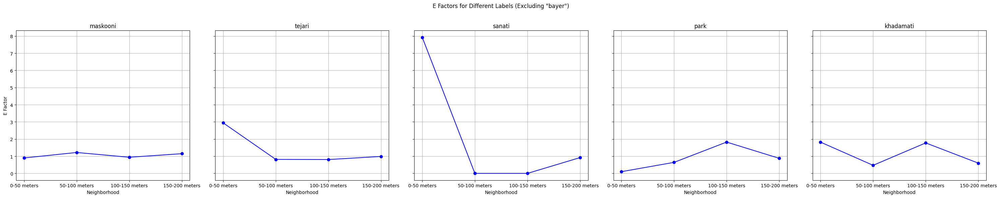

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=num_labels, figsize=(30, 6), sharey=True)

for ax, label in zip(axes, labels_of_interest):
    tejari_e_factors = [tejari_enrichment_factors[neighborhood][label] for neighborhood in neighborhoods]

    ax.plot(neighborhoods, tejari_e_factors, marker='o', linestyle='-', color='b')
    ax.set_xlabel('Neighborhood')
    ax.set_title(f'{label}')
    ax.grid(True)

axes[0].set_ylabel('E Factor')
fig.suptitle('E Factors for Different Labels (Excluding "bayer")')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
tejari_log_enrichment_factors = {
    range_key: {label: np.log(tejari_enrichment_factors[range_key][label]) if tejari_enrichment_factors[range_key][label] > 0 else 0 for label in labels_of_interest}
    for range_key in distance_ranges
}

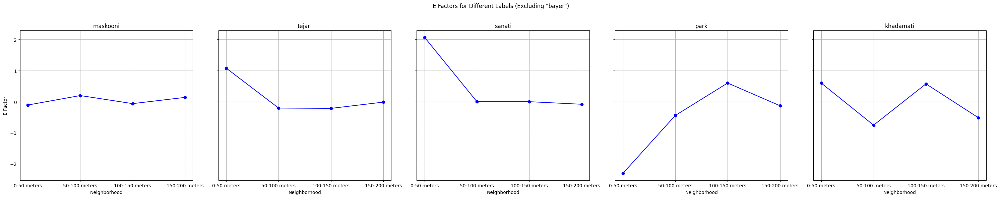

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=num_labels, figsize=(30, 6), sharey=True)

for ax, label in zip(axes, labels_of_interest):
    tejari_e_factors = [tejari_log_enrichment_factors[neighborhood][label] for neighborhood in neighborhoods]

    ax.plot(neighborhoods, tejari_e_factors, marker='o', linestyle='-', color='b')
    ax.set_xlabel('Neighborhood')
    ax.set_title(f'{label}')
    ax.grid(True)

axes[0].set_ylabel('E Factor')
fig.suptitle('E Factors for Different Labels (Excluding "bayer")')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
has_sanati = any(data['attributes'].get('landuse2') == 'sanati' for data in sample_50_centroids_data.values())

if has_sanati:
    print("There is at least one centroid with landuse2 as 'sanati'.")
else:
    print("There is no centroid with landuse2 as 'sanati'.")


There is no centroid with landuse2 as 'sanati'.


In [ ]:
park_centroids_data = {idx: data for idx, data in sample_50_centroids_data.items() if data["attributes"]["landuse2"] == "park"}

park_centroids_list = []
for idx, data in park_centroids_data.items():
    for range_key, range_data in data["covered_ranges"].items():
        for centroid, attributes in zip(range_data["centroids"], range_data["attributes"]):
            park_centroids_list.append({
                "sample_centroid_id": idx,
                "range": range_key,
                "centroid": centroid,
                **attributes
            })

park_centroids_gdf = gpd.GeoDataFrame(park_centroids_list, geometry="centroid", crs=centroids_gdf.crs)

In [ ]:
park_centroids_data = {idx: data for idx, data in sample_50_centroids_data.items() if data["attributes"]["landuse2"] == "park"}

park_filtered_gdf = park_centroids_gdf[park_centroids_gdf['landuse2'] != 'bayer']
park_total_area_per_range = park_filtered_gdf.groupby('range')['SHAPE_Area'].sum().to_dict()
park_grouped_area = park_filtered_gdf.groupby(['range', 'landuse2'])['SHAPE_Area'].sum().unstack(fill_value=0)

park_area_per_label_per_range = {
    range_key: {label: 0 for label in labels_of_interest}
    for range_key in distance_ranges
}

for range_key in distance_ranges:
    range_gdf = park_centroids_gdf[park_centroids_gdf['range'] == range_key]
    for label in labels_of_interest:
        label_gdf = range_gdf[range_gdf['landuse2'] == label]
        park_area_per_label_per_range[range_key][label] = label_gdf['SHAPE_Area'].sum()

print(f"Area of each label in each distance range: {json.dumps(park_area_per_label_per_range, indent=2)}")


Area of each label in each distance range: {
  "0-50 meters": {
    "maskooni": 3114.2280735716,
    "tejari": 2724.4731968060996,
    "sanati": 0.0,
    "park": 2832.2762153539998,
    "khadamati": 2547.01904013
  },
  "50-100 meters": {
    "maskooni": 12962.9900549063,
    "tejari": 6805.3123734828,
    "sanati": 0.0,
    "park": 157.251170371,
    "khadamati": 3883.119198456
  },
  "100-150 meters": {
    "maskooni": 27473.2970252718,
    "tejari": 4501.407709178399,
    "sanati": 61.7244424352,
    "park": 596.007988244,
    "khadamati": 11591.5781127669
  },
  "150-200 meters": {
    "maskooni": 38136.6966330702,
    "tejari": 5633.566620863699,
    "sanati": 0.0,
    "park": 8813.40154297,
    "khadamati": 1935.6671008149
  }
}


In [ ]:
park_total_area_per_label = park_filtered_gdf.groupby('landuse2')['SHAPE_Area'].sum().to_dict()
park_total_area_whole = park_centroids_gdf['SHAPE_Area'].sum()

print(f"Total area of each land use label: {park_total_area_per_label}")
print(f"Total area of the whole area: {park_total_area_whole}")

Total area of each land use label: {'khadamati': 19957.3834521678, 'maskooni': 81687.2117868199, 'park': 12398.936916939001, 'sanati': 61.7244424352, 'tejari': 19664.759900331}
Total area of the whole area: 145569.2870710459


In [ ]:
park_enrichment_factors = {
    range_key: {label: 0 for label in labels_of_interest}
    for range_key in distance_ranges
}
for range_key in distance_ranges:
    park_total_area_range = park_total_area_per_range.get(range_key, 0)
    for label in labels_of_interest:
        park_area_label_range = park_grouped_area.at[range_key, label] if range_key in park_grouped_area.index else 0
        park_area_label_whole = park_total_area_per_label.get(label, 0)

        if park_total_area_range > 0 and park_total_area_whole > 0 and park_area_label_whole > 0:
            park_ef = (park_area_label_range / park_total_area_range) / (park_area_label_whole / park_total_area_whole)
            park_enrichment_factors[range_key][label] = park_ef

print(f"Enrichment factors: {json.dumps(park_enrichment_factors, indent=2)}"
)

Enrichment factors: {
  "0-50 meters": {
    "maskooni": 0.4947101223412925,
    "tejari": 1.797828850160219,
    "sanati": 0.0,
    "park": 2.9641870715115233,
    "khadamati": 1.6560866019093652
  },
  "50-100 meters": {
    "maskooni": 0.9702545403391855,
    "tejari": 2.1158943799223793,
    "sanati": 0.0,
    "park": 0.07754325094369238,
    "khadamati": 1.1896294006536143
  },
  "100-150 meters": {
    "maskooni": 1.1070526925248585,
    "tejari": 0.7534792309416263,
    "sanati": 3.2916343338865293,
    "park": 0.15822649720028745,
    "khadamati": 1.9118356166958685
  },
  "150-200 meters": {
    "maskooni": 1.2465457701537193,
    "tejari": 0.7649164771188097,
    "sanati": 0.0,
    "park": 1.8979218981634416,
    "khadamati": 0.25896811573358075
  }
}


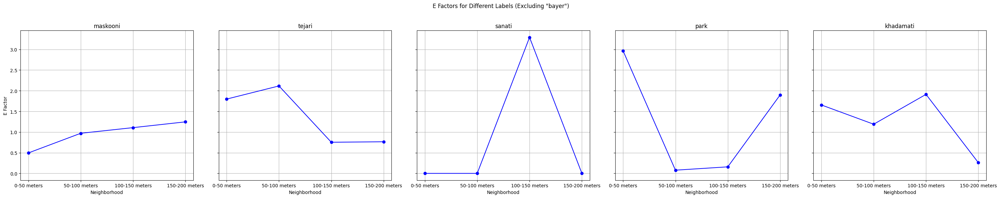

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=num_labels, figsize=(30, 6), sharey=True)

for ax, label in zip(axes, labels_of_interest):
    park_e_factors = [park_enrichment_factors[neighborhood][label] for neighborhood in neighborhoods]

    ax.plot(neighborhoods, park_e_factors, marker='o', linestyle='-', color='b')
    ax.set_xlabel('Neighborhood')
    ax.set_title(f'{label}')
    ax.grid(True)

axes[0].set_ylabel('E Factor')
fig.suptitle('E Factors for Different Labels (Excluding "bayer")')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
park_log_enrichment_factors = {
    range_key: {label: np.log(park_enrichment_factors[range_key][label]) if park_enrichment_factors[range_key][label] > 0 else 0 for label in labels_of_interest}
    for range_key in distance_ranges
}

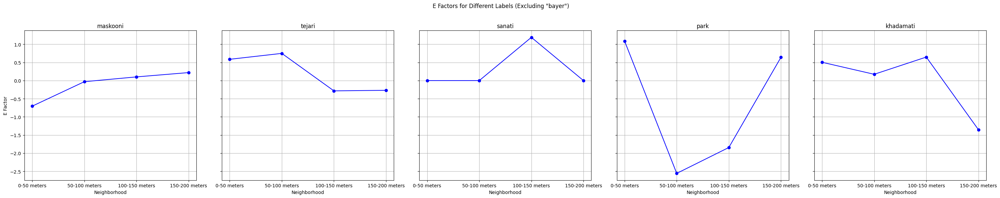

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=num_labels, figsize=(30, 6), sharey=True)

for ax, label in zip(axes, labels_of_interest):
    park_e_factors = [park_log_enrichment_factors[neighborhood][label] for neighborhood in neighborhoods]

    ax.plot(neighborhoods, park_e_factors, marker='o', linestyle='-', color='b')
    ax.set_xlabel('Neighborhood')
    ax.set_title(f'{label}')
    ax.grid(True)

axes[0].set_ylabel('E Factor')
fig.suptitle('E Factors for Different Labels (Excluding "bayer")')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
khadamati_centroids_data = {idx: data for idx, data in sample_50_centroids_data.items() if data["attributes"]["landuse2"] == "khadamati"}

khadamati_centroids_list = []
for idx, data in khadamati_centroids_data.items():
    for range_key, range_data in data["covered_ranges"].items():
        for centroid, attributes in zip(range_data["centroids"], range_data["attributes"]):
            khadamati_centroids_list.append({
                "sample_centroid_id": idx,
                "range": range_key,
                "centroid": centroid,
                **attributes
            })

khadamati_centroids_gdf = gpd.GeoDataFrame(khadamati_centroids_list, geometry="centroid", crs=centroids_gdf.crs)

khadamati_filtered_gdf = khadamati_centroids_gdf[khadamati_centroids_gdf['landuse2'] != 'bayer']
khadamati_total_area_per_range = khadamati_filtered_gdf.groupby('range')['SHAPE_Area'].sum().to_dict()
khadamati_grouped_area = khadamati_filtered_gdf.groupby(['range', 'landuse2'])['SHAPE_Area'].sum().unstack(fill_value=0)

khadamati_area_per_label_per_range = {
    range_key: {label: 0 for label in labels_of_interest}
    for range_key in distance_ranges
}

for range_key in distance_ranges:
    range_gdf = khadamati_centroids_gdf[khadamati_centroids_gdf['range'] == range_key]
    for label in labels_of_interest:
        label_gdf = range_gdf[range_gdf['landuse2'] == label]
        khadamati_area_per_label_per_range[range_key][label] = label_gdf['SHAPE_Area'].sum()

print(f"Area of each label in each distance range: {json.dumps(khadamati_area_per_label_per_range, indent=2)}")

Area of each label in each distance range: {
  "0-50 meters": {
    "maskooni": 1675.672541254,
    "tejari": 114.58516668680001,
    "sanati": 0.0,
    "park": 0.0,
    "khadamati": 1805.000545962
  },
  "50-100 meters": {
    "maskooni": 8661.653687544,
    "tejari": 559.0433923019,
    "sanati": 0.0,
    "park": 2650.32231689,
    "khadamati": 0.0
  },
  "100-150 meters": {
    "maskooni": 10403.4430596311,
    "tejari": 420.64821944060003,
    "sanati": 0.0,
    "park": 0.0,
    "khadamati": 0.0
  },
  "150-200 meters": {
    "maskooni": 14224.018557579797,
    "tejari": 645.9797143817,
    "sanati": 54.9977116833,
    "park": 0.0,
    "khadamati": 0.0
  }
}


In [ ]:
khadamati_total_area_per_label = khadamati_filtered_gdf.groupby('landuse2')['SHAPE_Area'].sum().to_dict()
khadamati_total_area_whole = khadamati_centroids_gdf['SHAPE_Area'].sum()

print(f"Total area of each land use label: {khadamati_total_area_per_label}")
print(f"Total area of the whole area: {khadamati_total_area_whole}")

Total area of each land use label: {'khadamati': 1805.000545962, 'maskooni': 34964.7878460089, 'park': 2650.32231689, 'sanati': 54.9977116833, 'tejari': 1740.256492811}
Total area of the whole area: 41215.3649133552


In [ ]:
khadamati_enrichment_factors = {
    range_key: {label: 0 for label in labels_of_interest}
    for range_key in distance_ranges
}
for range_key in distance_ranges:
    khadamati_total_area_range = khadamati_total_area_per_range.get(range_key, 0)
    for label in labels_of_interest:
        khadamati_area_label_range = khadamati_grouped_area.at[range_key, label] if range_key in khadamati_grouped_area.index else 0
        khadamati_area_label_whole = khadamati_total_area_per_label.get(label, 0)

        if khadamati_total_area_range > 0 and khadamati_total_area_whole > 0 and khadamati_area_label_whole > 0:
            khadamati_ef = (khadamati_area_label_range / khadamati_total_area_range) / (khadamati_area_label_whole / khadamati_total_area_whole)
            khadamati_enrichment_factors[range_key][label] = khadamati_ef

print(f"Enrichment factors: {json.dumps(khadamati_enrichment_factors, indent=2)}")

Enrichment factors: {
  "0-50 meters": {
    "maskooni": 0.5493983021984056,
    "tejari": 0.754821384468429,
    "sanati": 0.0,
    "park": 0.0,
    "khadamati": 11.463812055396643
  },
  "50-100 meters": {
    "maskooni": 0.8600843650947104,
    "tejari": 1.1153300171196647,
    "sanati": 0.0,
    "park": 3.4719313932456326,
    "khadamati": 0.0
  },
  "100-150 meters": {
    "maskooni": 1.1329582349623633,
    "tejari": 0.9203933995501143,
    "sanati": 0.0,
    "park": 0.0,
    "khadamati": 0.0
  },
  "150-200 meters": {
    "maskooni": 1.1234049657093743,
    "tejari": 1.025062966918918,
    "sanati": 2.7614992297833836,
    "park": 0.0,
    "khadamati": 0.0
  }
}


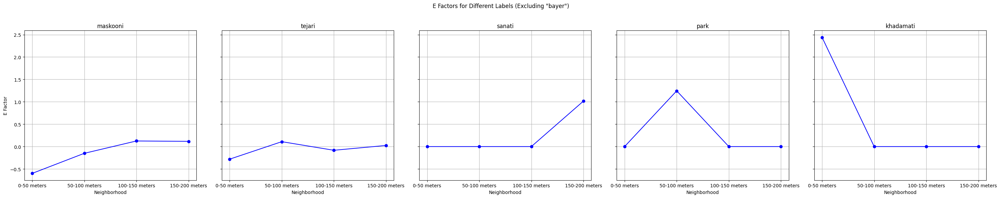

In [ ]:
khadamati_log_enrichment_factors = {
    range_key: {label: np.log(khadamati_enrichment_factors[range_key][label]) if khadamati_enrichment_factors[range_key][label] > 0 else 0 for label in labels_of_interest}
    for range_key in distance_ranges
}

fig, axes = plt.subplots(nrows=1, ncols=num_labels, figsize=(30, 6), sharey=True)

for ax, label in zip(axes, labels_of_interest):
    khadamati_e_factors = [khadamati_log_enrichment_factors[neighborhood][label] for neighborhood in neighborhoods]

    ax.plot(neighborhoods, khadamati_e_factors, marker='o', linestyle='-', color='b')
    ax.set_xlabel('Neighborhood')
    ax.set_title(f'{label}')
    ax.grid(True)

axes[0].set_ylabel('E Factor')
fig.suptitle('E Factors for Different Labels (Excluding "bayer")')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
khadamati_log_enrichment_factors = {
    range_key: {label: np.log(khadamati_enrichment_factors[range_key][label]) if khadamati_enrichment_factors[range_key][label] > 0 else 0 for label in labels_of_interest}
    for range_key in distance_ranges
}

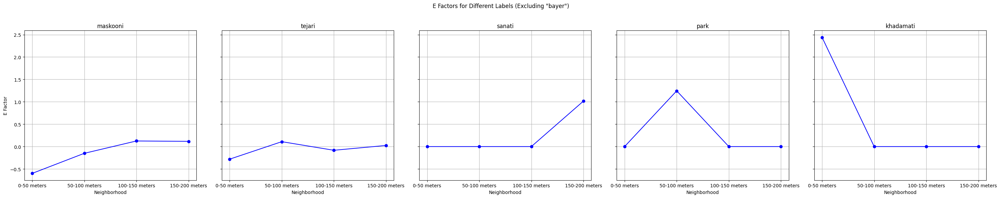

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=num_labels, figsize=(30, 6), sharey=True)

for ax, label in zip(axes, labels_of_interest):
    khadamati_e_factors = [khadamati_log_enrichment_factors[neighborhood][label] for neighborhood in neighborhoods]

    ax.plot(neighborhoods, khadamati_e_factors, marker='o', linestyle='-', color='b')
    ax.set_xlabel('Neighborhood')
    ax.set_title(f'{label}')
    ax.grid(True)

axes[0].set_ylabel('E Factor')
fig.suptitle('E Factors for Different Labels (Excluding "bayer")')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

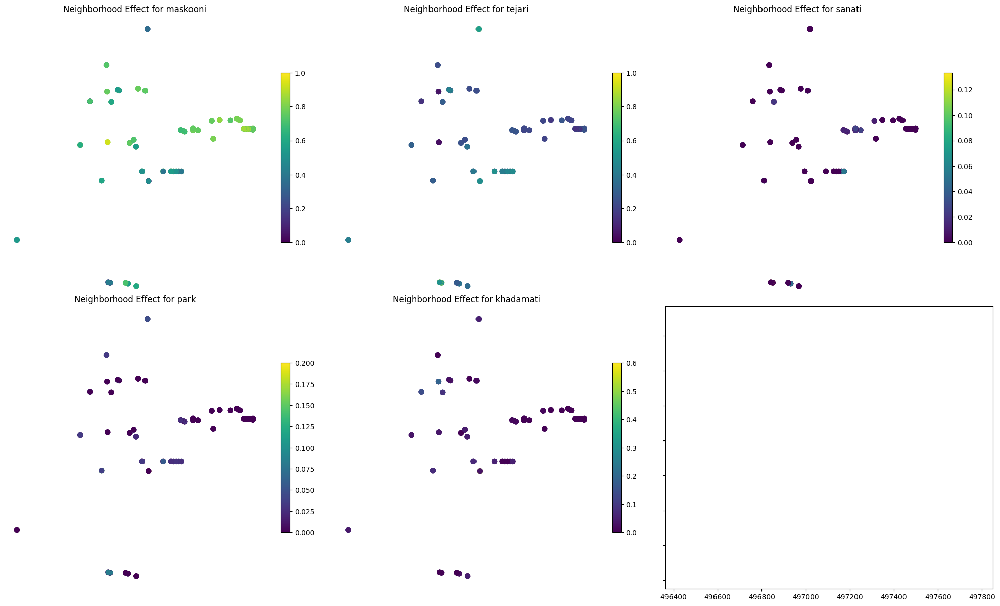

In [ ]:
from shapely.geometry import Point, LineString
from sklearn.neighbors import KDTree


distance_ranges = ['0-50 meters', '50-100 meters', '100-150 meters', '150-200 meters']
labels_of_interest = ['maskooni', 'tejari', 'sanati', 'park', 'khadamati']

neighborhood_effects = []

for idx, data in sample_50_centroids_data.items():
    centroid = data["centroid"]
    covered_ranges = data["covered_ranges"]

    for range_key, range_data in covered_ranges.items():
        landuse_counts = {label: 0 for label in labels_of_interest}

        for attributes in range_data["attributes"]:
            landuse = attributes.get('landuse2')
            if landuse in labels_of_interest:
                landuse_counts[landuse] += 1

        total_count = sum(landuse_counts.values())
        if total_count > 0:
            for label in labels_of_interest:
                landuse_counts[label] /= total_count

        neighborhood_effects.append({
            'centroid': centroid,
            'range': range_key,
            **landuse_counts
        })

neighborhood_effects_gdf = pd.DataFrame(neighborhood_effects)
neighborhood_effects_gdf = gpd.GeoDataFrame(neighborhood_effects_gdf, geometry='centroid', crs=centroids_gdf.crs)

fig, axes = plt.subplots(2, 3, figsize=(20, 12), sharex=True, sharey=True)
axes = axes.flatten()

for i, label in enumerate(labels_of_interest):
    ax = axes[i]
    neighborhood_effects_gdf.plot(column=label, ax=ax, legend=True, cmap='viridis', markersize=50, legend_kwds={'shrink': 0.6})
    ax.set_title(f'Neighborhood Effect for {label}')
    ax.set_axis_off()

plt.tight_layout()
plt.show()


In [ ]:
# Process the entire GeoDataFrame
all_centroids_full_data = {}

for idx, sample_point in tqdm(centroids_gdf.iterrows(), total=centroids_gdf.shape[0], desc="Processing Centroids"):
    nearest_node_id = sample_point['nearest_node_id']
    nearest_node_geom = sample_point['nearest_node_geom']

    centroid_full_data = {
        "centroid": sample_point.centroid,
        "attributes": sample_point.to_dict(),
        "covered_ranges": {
            "0-50 meters": {
                "centroids": [],
                "attributes": []
            },
            "50-100 meters": {
                "centroids": [],
                "attributes": []
            },
            "100-150 meters": {
                "centroids": [],
                "attributes": []
            },
            "150-200 meters": {
                "centroids": [],
                "attributes": []
            }
        }
    }

    service_area_nodes_50_full = nx.single_source_dijkstra_path_length(street_network, (nearest_node_geom.x, nearest_node_geom.y), cutoff=50, weight='weight')

    covered_nodes_50_full = [Point(x, y) for x, y in service_area_nodes_50_full.keys()]
    covered_nodes_gdf_50_full = gpd.GeoDataFrame(geometry=covered_nodes_50_full, crs=nodes_gdf.crs)
    covered_node_ids_50_full = [nodes_gdf[nodes_gdf.geometry == node].node_id.values[0] for node in covered_nodes_gdf_50_full.geometry]
    covered_centroids_50_full = centroids_gdf[centroids_gdf['nearest_node_id'].isin(covered_node_ids_50_full)]

    centroid_full_data["covered_ranges"]["0-50 meters"]["centroids"] = covered_centroids_50_full['centroid'].tolist()
    centroid_full_data["covered_ranges"]["0-50 meters"]["attributes"] = covered_centroids_50_full.drop(columns='centroid').to_dict('records')

    service_area_nodes_100_full = nx.single_source_dijkstra_path_length(street_network, (nearest_node_geom.x, nearest_node_geom.y), cutoff=100, weight='weight')
    covered_nodes_100_full = [Point(x, y) for x, y in service_area_nodes_100_full.keys()]
    covered_nodes_gdf_100_full = gpd.GeoDataFrame(geometry=covered_nodes_100_full, crs=nodes_gdf.crs)
    new_covered_nodes_50_2_full = set(service_area_nodes_100_full.keys()) - set(service_area_nodes_50_full.keys())
    new_covered_nodes_gdf_50_2_full = gpd.GeoDataFrame(geometry=[Point(x, y) for x, y in new_covered_nodes_50_2_full], crs=nodes_gdf.crs)
    new_covered_node_ids_50_2_full = [nodes_gdf[nodes_gdf.geometry == node].node_id.values[0] for node in new_covered_nodes_gdf_50_2_full.geometry]
    new_covered_centroids_50_2_full = centroids_gdf[centroids_gdf['nearest_node_id'].isin(new_covered_node_ids_50_2_full)]

    centroid_full_data["covered_ranges"]["50-100 meters"]["centroids"] = new_covered_centroids_50_2_full['centroid'].tolist()
    centroid_full_data["covered_ranges"]["50-100 meters"]["attributes"] = new_covered_centroids_50_2_full.drop(columns='centroid').to_dict('records')

    service_area_nodes_150_full = nx.single_source_dijkstra_path_length(street_network, (nearest_node_geom.x, nearest_node_geom.y), cutoff=150, weight='weight')
    covered_nodes_150_full = [Point(x, y) for x, y in service_area_nodes_150_full.keys()]
    covered_nodes_gdf_150_full = gpd.GeoDataFrame(geometry=covered_nodes_150_full, crs=nodes_gdf.crs)
    new_covered_nodes_50_3_full = set(service_area_nodes_150_full.keys()) - set(service_area_nodes_100_full.keys())
    new_covered_nodes_gdf_50_3_full = gpd.GeoDataFrame(geometry=[Point(x, y) for x, y in new_covered_nodes_50_3_full], crs=nodes_gdf.crs)
    new_covered_node_ids_50_3_full = [nodes_gdf[nodes_gdf.geometry == node].node_id.values[0] for node in new_covered_nodes_gdf_50_3_full.geometry]
    new_covered_centroids_50_3_full = centroids_gdf[centroids_gdf['nearest_node_id'].isin(new_covered_node_ids_50_3_full)]

    centroid_full_data["covered_ranges"]["100-150 meters"]["centroids"] = new_covered_centroids_50_3_full['centroid'].tolist()
    centroid_full_data["covered_ranges"]["100-150 meters"]["attributes"] = new_covered_centroids_50_3_full.drop(columns='centroid').to_dict('records')

    service_area_nodes_200_full = nx.single_source_dijkstra_path_length(street_network, (nearest_node_geom.x, nearest_node_geom.y), cutoff=200, weight='weight')
    covered_nodes_200_full = [Point(x, y) for x, y in service_area_nodes_200_full.keys()]
    covered_nodes_gdf_200_full = gpd.GeoDataFrame(geometry=covered_nodes_200_full, crs=nodes_gdf.crs)
    new_covered_nodes_50_4_full = set(service_area_nodes_200_full.keys()) - set(service_area_nodes_150_full.keys())
    new_covered_nodes_gdf_50_4_full = gpd.GeoDataFrame(geometry=[Point(x, y) for x, y in new_covered_nodes_50_4_full], crs=nodes_gdf.crs)
    new_covered_node_ids_50_4_full = [nodes_gdf[nodes_gdf.geometry == node].node_id.values[0] for node in new_covered_nodes_gdf_50_4_full.geometry]
    new_covered_centroids_50_4_full = centroids_gdf[centroids_gdf['nearest_node_id'].isin(new_covered_node_ids_50_4_full)]

    centroid_full_data["covered_ranges"]["150-200 meters"]["centroids"] = new_covered_centroids_50_4_full['centroid'].tolist()
    centroid_full_data["covered_ranges"]["150-200 meters"]["attributes"] = new_covered_centroids_50_4_full.drop(columns='centroid').to_dict('records')

    all_centroids_full_data[idx] = centroid_full_data

landuse_counts_full = count_landuse_within_ranges(all_centroids_full_data, labels_of_interest)
total_landuse_counts_full = calculate_total_landuse_counts(landuse_counts_full, "maskooni")

enrichment_factors_full = calculate_enrichment_factors(total_landuse_counts_full, centroids_gdf, labels_of_interest, distance_ranges)

plot_enrichment_factors(enrichment_factors_full, labels_of_interest, distance_ranges)

neighborhood_effects_full = calculate_neighborhood_effects(all_centroids_full_data, labels_of_interest, distance_ranges)
plot_neighborhood_effects(neighborhood_effects_full, labels_of_interest, centroids_gdf)


Processing Centroids:   0%|          | 0/5797 [00:00<?, ?it/s]

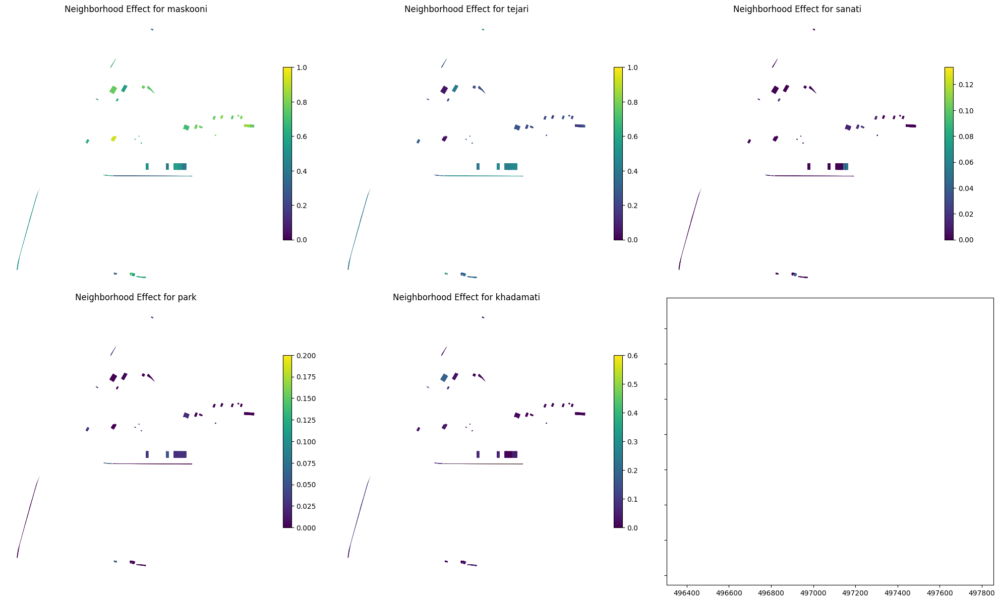

In [ ]:
distance_ranges = ['0-50 meters', '50-100 meters', '100-150 meters', '150-200 meters']
labels_of_interest = ['maskooni', 'tejari', 'sanati', 'park', 'khadamati']

neighborhood_effects = []

for idx, data in sample_50_centroids_data.items():
    centroid = data["centroid"]
    covered_ranges = data["covered_ranges"]

    for range_key, range_data in covered_ranges.items():
        landuse_counts = {label: 0 for label in labels_of_interest}

        for attributes in range_data["attributes"]:
            landuse = attributes.get('landuse2')
            if landuse in labels_of_interest:
                landuse_counts[landuse] += 1

        total_count = sum(landuse_counts.values())
        if total_count > 0:
            for label in labels_of_interest:
                landuse_counts[label] /= total_count

        neighborhood_effects.append({
            'centroid': centroid,
            'range': range_key,
            **landuse_counts
        })

# Convert to GeoDataFrame
neighborhood_effects_gdf = pd.DataFrame(neighborhood_effects)
neighborhood_effects_gdf = gpd.GeoDataFrame(neighborhood_effects_gdf, geometry='centroid', crs=centroids_gdf.crs)

merged_gdf = landuse_gdf.merge(neighborhood_effects_gdf, left_on='centroid', right_on='centroid', how='left')

# Plot the neighborhood effect map for each land use category
fig, axes = plt.subplots(2, 3, figsize=(20, 12), sharex=True, sharey=True)
axes = axes.flatten()

for i, label in enumerate(labels_of_interest):
    ax = axes[i]
    merged_gdf.plot(column=label, ax=ax, legend=True, cmap='viridis', legend_kwds={'shrink': 0.6})
    ax.set_title(f'Neighborhood Effect for {label}')
    ax.set_axis_off()

plt.tight_layout()
plt.show()


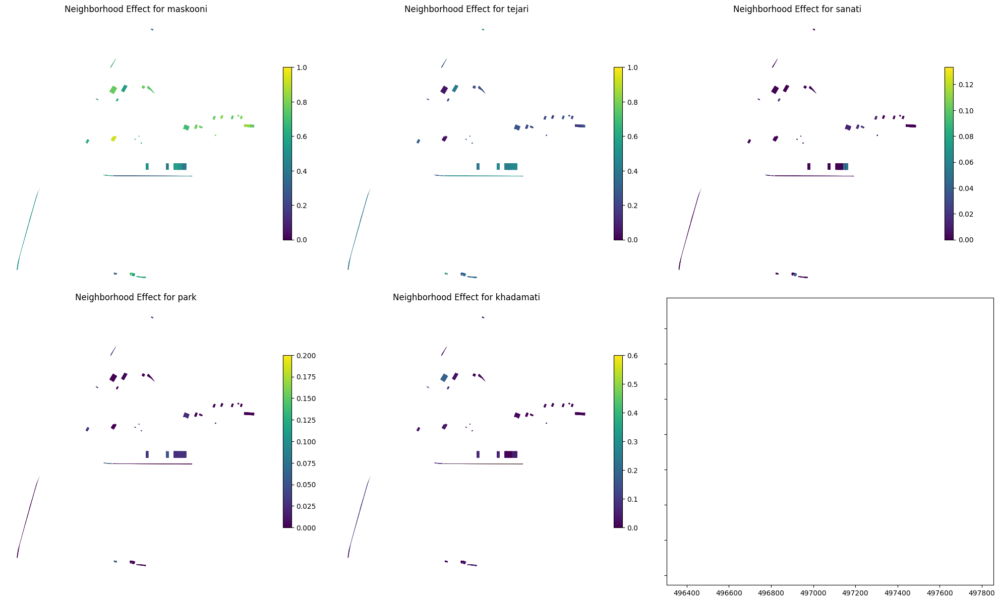

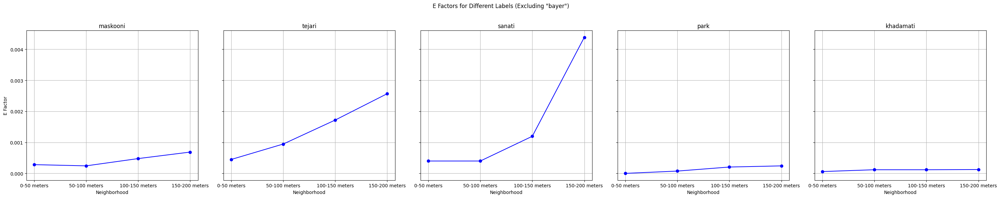

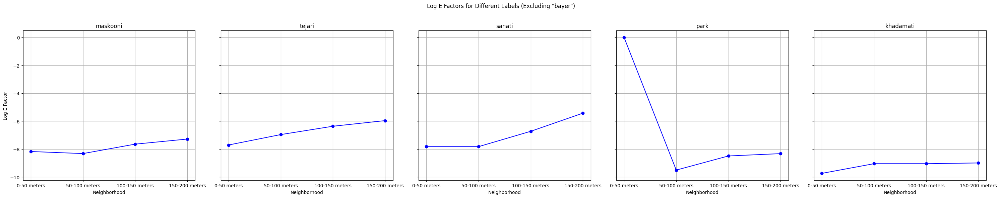

In [ ]:
import matplotlib.pyplot as plt
import geopandas as gpd
import pandas as pd
import numpy as np

# Assuming all your data (landuse_gdf, centroids_gdf, etc.) are already defined

# Define the distance ranges and labels of interest
distance_ranges = ['0-50 meters', '50-100 meters', '100-150 meters', '150-200 meters']
labels_of_interest = ['maskooni', 'tejari', 'sanati', 'park', 'khadamati']

# Calculate the neighborhood effect for each centroid in the whole dataset
neighborhood_effects = []

for idx, data in sample_50_centroids_data.items():
    centroid = data["centroid"]
    covered_ranges = data["covered_ranges"]

    for range_key, range_data in covered_ranges.items():
        landuse_counts = {label: 0 for label in labels_of_interest}

        for attributes in range_data["attributes"]:
            landuse = attributes.get('landuse2')
            if landuse in labels_of_interest:
                landuse_counts[landuse] += 1

        total_count = sum(landuse_counts.values())
        if total_count > 0:
            for label in labels_of_interest:
                landuse_counts[label] /= total_count

        neighborhood_effects.append({
            'centroid': centroid,
            'range': range_key,
            **landuse_counts
        })

# Convert to GeoDataFrame
neighborhood_effects_gdf = pd.DataFrame(neighborhood_effects)
neighborhood_effects_gdf = gpd.GeoDataFrame(neighborhood_effects_gdf, geometry='centroid', crs=centroids_gdf.crs)

# Merge the neighborhood effects with the original landuse_gdf to plot areas instead of points
merged_gdf = landuse_gdf.merge(neighborhood_effects_gdf, left_on='centroid', right_on='centroid', how='left')

# Plot the neighborhood effect map for each land use category
fig, axes = plt.subplots(2, 3, figsize=(20, 12), sharex=True, sharey=True)
axes = axes.flatten()

for i, label in enumerate(labels_of_interest):
    ax = axes[i]
    merged_gdf.plot(column=label, ax=ax, legend=True, cmap='viridis', legend_kwds={'shrink': 0.6})
    ax.set_title(f'Neighborhood Effect for {label}')
    ax.set_axis_off()

plt.tight_layout()
plt.show()

# Calculate and plot the enrichment factors for the whole area

def count_landuse_within_ranges(centroids_data, landuse_labels):
    landuse_counts = {}

    for idx, data in centroids_data.items():
        central_landuse = data['attributes'].get('landuse2')

        centroid_landuse_counts = {
            "central_landuse": central_landuse,
            "0-50 meters": {label: 0 for label in landuse_labels},
            "50-100 meters": {label: 0 for label in landuse_labels},
            "100-150 meters": {label: 0 for label in landuse_labels},
            "150-200 meters": {label: 0 for label in landuse_labels}
        }

        for attributes in data["covered_ranges"]["0-50 meters"]["attributes"]:
            landuse = attributes.get('landuse2')
            if landuse in landuse_labels:
                centroid_landuse_counts["0-50 meters"][landuse] += 1

        for attributes in data["covered_ranges"]["50-100 meters"]["attributes"]:
            landuse = attributes.get('landuse2')
            if landuse in landuse_labels:
                centroid_landuse_counts["50-100 meters"][landuse] += 1

        for attributes in data["covered_ranges"]["100-150 meters"]["attributes"]:
            landuse = attributes.get('landuse2')
            if landuse in landuse_labels:
                centroid_landuse_counts["100-150 meters"][landuse] += 1

        for attributes in data["covered_ranges"]["150-200 meters"]["attributes"]:
            landuse = attributes.get('landuse2')
            if landuse in landuse_labels:
                centroid_landuse_counts["150-200 meters"][landuse] += 1

        landuse_counts[idx] = centroid_landuse_counts

    return landuse_counts

# Get landuse counts for the whole dataset
landuse_counts = count_landuse_within_ranges(sample_50_centroids_data, labels_of_interest)

def calculate_total_landuse_counts(landuse_counts, central_label):
    total_landuse_counts = {
        "0-50 meters": {label: 0 for label in labels_of_interest},
        "50-100 meters": {label: 0 for label in labels_of_interest},
        "100-150 meters": {label: 0 for label in labels_of_interest},
        "150-200 meters": {label: 0 for label in labels_of_interest}
    }

    for idx, centroid_counts in landuse_counts.items():
        central_centroid_label = centroid_counts.get("central_landuse")

        if central_centroid_label != central_label:
            continue

        for label in labels_of_interest:
            total_landuse_counts["0-50 meters"][label] += centroid_counts["0-50 meters"].get(label, 0)

        for label in labels_of_interest:
            total_landuse_counts["50-100 meters"][label] += centroid_counts["50-100 meters"].get(label, 0)

        for label in labels_of_interest:
            total_landuse_counts["100-150 meters"][label] += centroid_counts["100-150 meters"].get(label, 0)

        for label in labels_of_interest:
            total_landuse_counts["150-200 meters"][label] += centroid_counts["150-200 meters"].get(label, 0)

    return total_landuse_counts

# Calculate total landuse counts for all labels of interest
total_landuse_counts = calculate_total_landuse_counts(landuse_counts, "maskooni")

# Calculate enrichment factors
def calculate_enrichment_factors(total_counts, landuse_gdf):
    total_area_per_label = landuse_gdf.groupby('landuse2')['SHAPE_Area'].sum().to_dict()
    total_area_whole = landuse_gdf['SHAPE_Area'].sum()

    enrichment_factors = {
        range_key: {label: 0 for label in labels_of_interest}
        for range_key in distance_ranges
    }

    for range_key in distance_ranges:
        for label in labels_of_interest:
            area_label_range = total_counts[range_key].get(label, 0)
            area_label_whole = total_area_per_label.get(label, 0)

            if total_area_whole > 0 and area_label_whole > 0:
                ef = (area_label_range / total_area_whole) / (area_label_whole / total_area_whole)
                enrichment_factors[range_key][label] = ef

    return enrichment_factors

enrichment_factors = calculate_enrichment_factors(total_landuse_counts, landuse_gdf)

# Plot the enrichment factors
fig, axes = plt.subplots(nrows=1, ncols=len(labels_of_interest), figsize=(30, 6), sharey=True)

for ax, label in zip(axes, labels_of_interest):
    e_factors = [enrichment_factors[neighborhood][label] for neighborhood in distance_ranges]

    ax.plot(distance_ranges, e_factors, marker='o', linestyle='-', color='b')
    ax.set_xlabel('Neighborhood')
    ax.set_title(f'{label}')
    ax.grid(True)

axes[0].set_ylabel('E Factor')
fig.suptitle('E Factors for Different Labels (Excluding "bayer")')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# Plot the logarithm of the enrichment factors
log_enrichment_factors = {
    range_key: {label: np.log(enrichment_factors[range_key][label]) if enrichment_factors[range_key][label] > 0 else 0 for label in labels_of_interest}
    for range_key in distance_ranges
}

fig, axes = plt.subplots(nrows=1, ncols=len(labels_of_interest), figsize=(30, 6), sharey=True)

for ax, label in zip(axes, labels_of_interest):
    e_factors = [log_enrichment_factors[neighborhood][label] for neighborhood in distance_ranges]

    ax.plot(distance_ranges, e_factors, marker='o', linestyle='-', color='b')
    ax.set_xlabel('Neighborhood')
    ax.set_title(f'{label}')
    ax.grid(True)

axes[0].set_ylabel('Log E Factor')
fig.suptitle('Log E Factors for Different Labels (Excluding "bayer")')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


In [ ]:
maskooni_neighborhood_effects = []

for idx, data in sample_50_centroids_data.items():
    effect = 0
    for range_key in distance_ranges:
        effect += enrichment_factors[range_key].get('maskooni', 0)
    maskooni_neighborhood_effects.append(effect)

sample_centroids_gdf['maskooni_effect'] = maskooni_neighborhood_effects

IndexError: list index out of range

In [ ]:
tejari_neighborhood_effects = []

for idx, data in sample_50_centroids_data.items():
    effect = 0
    for range_key in distance_ranges:
        effect += tejari_enrichment_factors[range_key].get('tejari', 0)
    tejari_neighborhood_effects.append(effect)

sample_centroids_gdf['tejari_effect'] = tejari_neighborhood_effects

In [ ]:
park_neighborhood_effects = []

for idx, data in sample_50_centroids_data.items():
    effect = 0
    for range_key in distance_ranges:
        effect += park_enrichment_factors[range_key].get('park', 0)
    park_neighborhood_effects.append(effect)

sample_centroids_gdf['park_effect'] = park_neighborhood_effects

In [ ]:
khadamati_neighborhood_effects = []

for idx, data in sample_50_centroids_data.items():
    effect = 0
    for range_key in distance_ranges:
        effect += khadamati_enrichment_factors[range_key].get('khadamati', 0)
    khadamati_neighborhood_effects.append(effect)

sample_centroids_gdf['khadamati_effect'] = khadamati_neighborhood_effects

In [ ]:
sanati_neighborhood_effects = []

for idx, data in sample_50_centroids_data.items():
    effect = 0
    for range_key in distance_ranges:
        effect += enrichment_factors[range_key].get('sanati', 0)
    sanati_neighborhood_effects.append(effect)

sample_centroids_gdf['sanati_effect'] = sanati_neighborhood_effects

In [ ]:
centroids_gdf = centroids_gdf[['centroid', 'maskooni_effect', 'tejari_effect', 'park_effect', 'khadamati_effect', 'sanati_effect']]

# Function to plot neighborhood effect for polygons
def plot_polygon_neighborhood_effect(gdf, effect_column, title):
    fig, ax = plt.subplots(1, 1, figsize=(10, 10))
    gdf.plot(column=effect_column, ax=ax, cmap='viridis', legend=True, edgecolor='k')
    streets_gdf.plot(ax=ax, color='lightgrey', linewidth=0.5)
    ax.set_title(title)
    ax.set_axis_off()
    plt.show()

# Ensure that landuse_gdf has a unique identifier and the centroid for merging
landuse_gdf['centroid'] = landuse_gdf.geometry.centroid

# Convert centroid columns to strings (optional, but ensures format consistency)
landuse_gdf['centroid_str'] = landuse_gdf['centroid'].astype(str)
centroids_gdf['centroid_str'] = centroids_gdf['centroid'].astype(str)

# Merge neighborhood effects back to the original polygons using unique identifiers
merged_gdf = landuse_gdf.merge(centroids_gdf.drop(columns='centroid'), on='centroid_str', how='left')

# Ensure the geometry is set correctly and CRS is retained
merged_gdf = merged_gdf.set_geometry('geometry')
merged_gdf.crs = landuse_gdf.crs

# Plotting the neighborhood effects
plot_polygon_neighborhood_effect(merged_gdf, 'maskooni_effect', 'Neighborhood Effect for Maskooni')
plot_polygon_neighborhood_effect(merged_gdf, 'tejari_effect', 'Neighborhood Effect for Tejari')
plot_polygon_neighborhood_effect(merged_gdf, 'park_effect', 'Neighborhood Effect for Park')
plot_polygon_neighborhood_effect(merged_gdf, 'khadamati_effect', 'Neighborhood Effect for Khadamati')
plot_polygon_neighborhood_effect(merged_gdf, 'sanati_effect', 'Neighborhood Effect for Sanati')

KeyError: "['maskooni_effect', 'tejari_effect', 'park_effect', 'khadamati_effect', 'sanati_effect'] not in index"

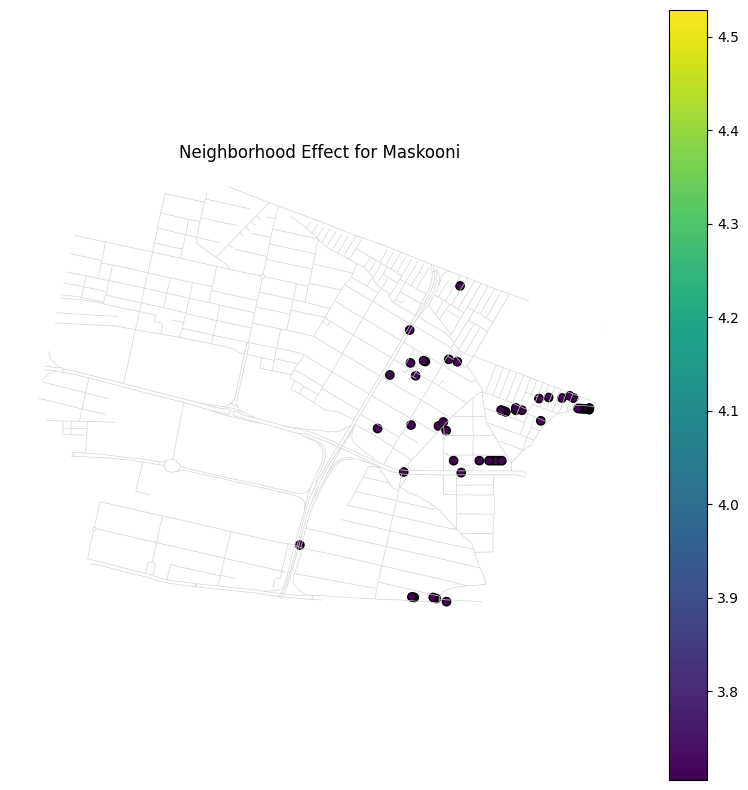

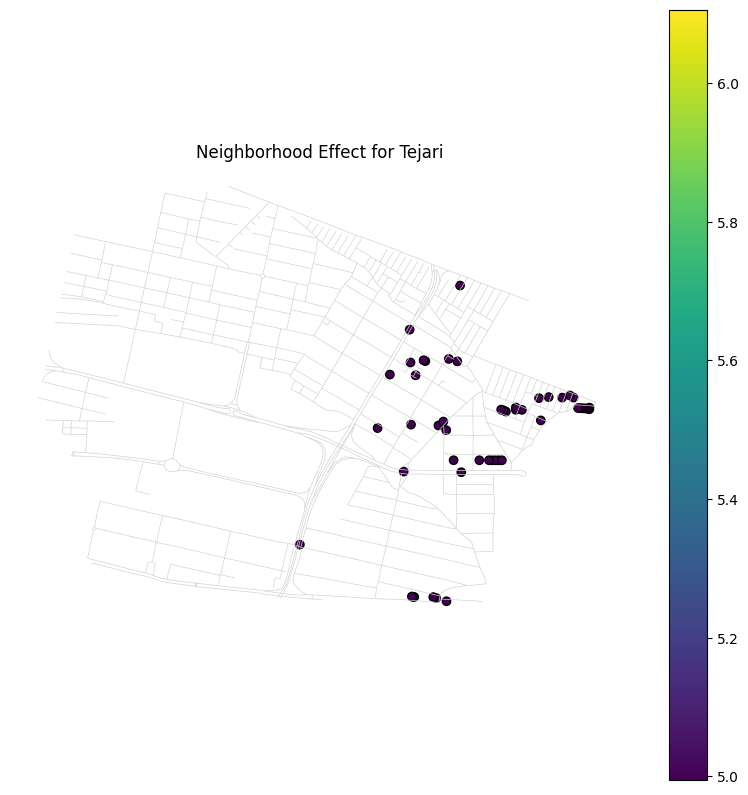

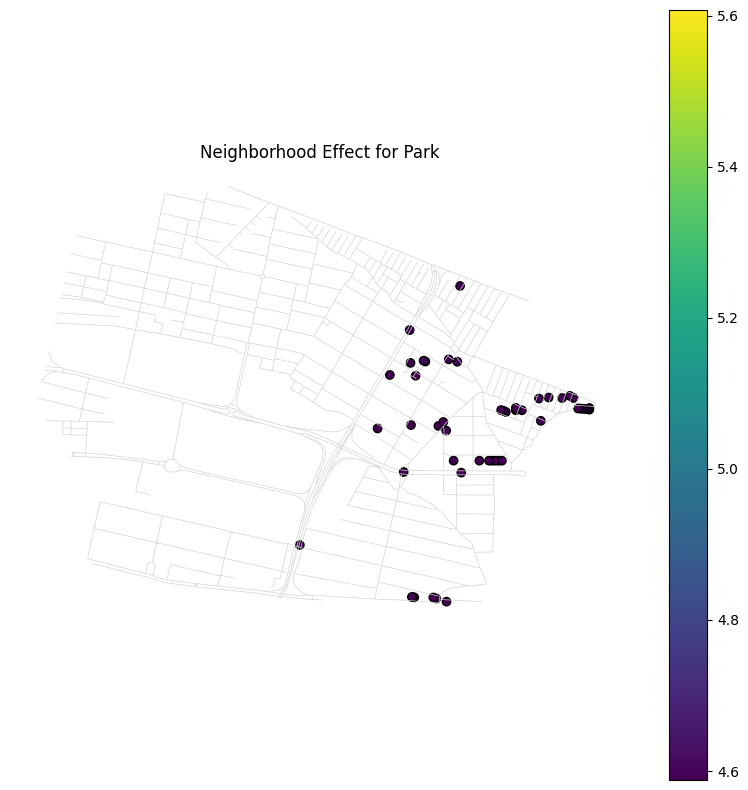

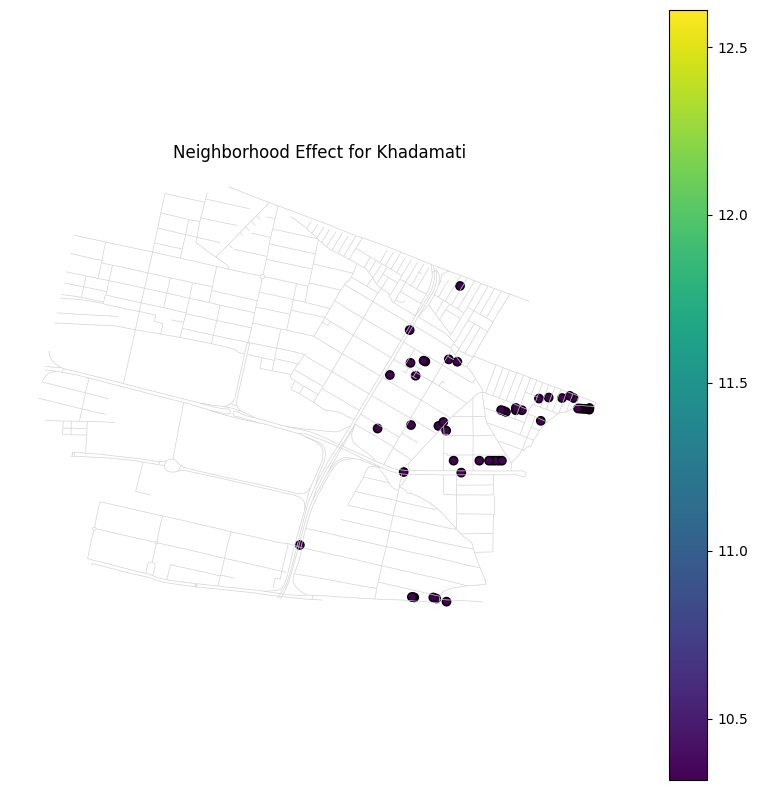

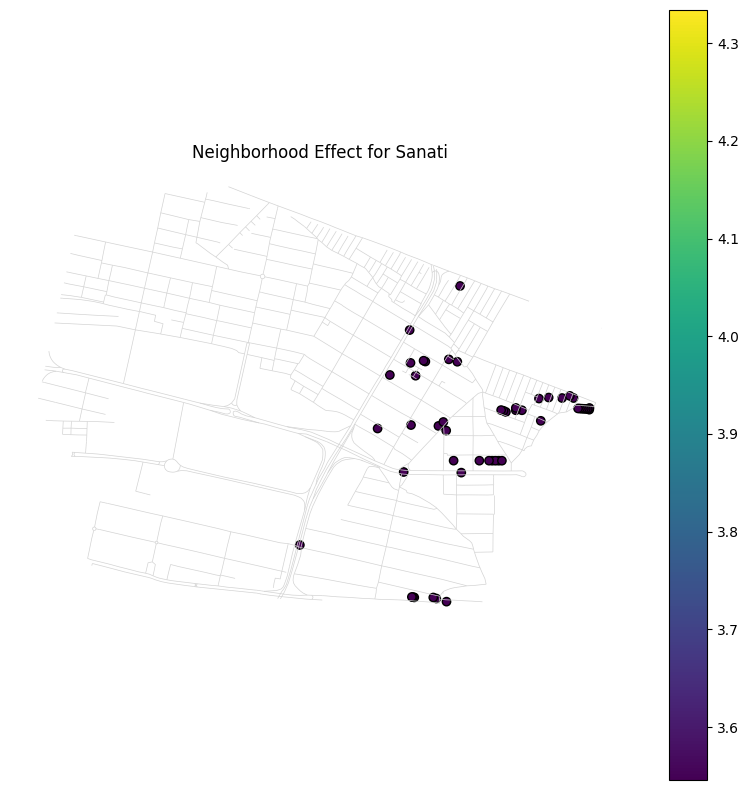

In [ ]:

# Plot for Maskooni
plot_polygon_neighborhood_effect(merged_gdf, 'maskooni_effect', 'Neighborhood Effect for Maskooni')

# Plot for Tejari
plot_polygon_neighborhood_effect(merged_gdf, 'tejari_effect', 'Neighborhood Effect for Tejari')

# Plot for Park
plot_polygon_neighborhood_effect(merged_gdf, 'park_effect', 'Neighborhood Effect for Park')

# Plot for Khadamati
plot_polygon_neighborhood_effect(merged_gdf, 'khadamati_effect', 'Neighborhood Effect for Khadamati')

# Plot for Sanati
plot_polygon_neighborhood_effect(merged_gdf, 'sanati_effect', 'Neighborhood Effect for Sanati')

In [ ]:
# Assuming `centroids_gdf` contains the initial list of centroids
sample_centroids_gdf = centroids_gdf.iloc[:50].reset_index(drop=True)

In [ ]:
landuse_labels_tejari = ["tejari", 'khadamati', 'maskooni', 'sanati', 'park']
park_landuse_counts = count_landuse_within_ranges(park_centroids_data, landuse_labels_tejari)

In [ ]:
# Define the distance ranges
distance_ranges = ['0-50 meters', '50-100 meters', '100-150 meters', '150-200 meters']
labels_of_interest = ['tejari', 'khadamati', 'maskooni', 'sanati', 'park']

In [ ]:
def calculate_log_enrichment_factors(enrichment_factors):
    log_enrichment_factors = {}
    for range_key, counts in enrichment_factors.items():
        log_enrichment_factors[range_key] = {}
        for label, value in counts.items():
            if value > 0:
                log_enrichment_factors[range_key][label] = np.log(value)
            else:
                log_enrichment_factors[range_key][label] = 0
    return log_enrichment_factors

log_enrichment_factors_maskooni = calculate_log_enrichment_factors(total_landuse_counts_maskooni)
log_enrichment_factors_tejari = calculate_log_enrichment_factors(total_landuse_counts_tejari)
log_enrichment_factors_park = calculate_log_enrichment_factors(total_landuse_counts_park)

In [ ]:
def aggregate_log_enrichment_factors(log_enrichment_factors, landuse_gdf):
    aggregated_effect_map = []

    for idx, row in landuse_gdf.iterrows():
        centroid_id = row.name  # use row index as centroid_id
        for range_key in distance_ranges:
            for label in labels_of_interest:
                effect_value = log_enrichment_factors.get(range_key, {}).get(label, 0)
                polygon = row.centroid  # Get the geometry of the polygon
                aggregated_effect_map.append({
                    'centroid_id': centroid_id,
                    'range': range_key,
                    'label': label,
                    'effect_value': effect_value,
                    'geometry': polygon
                })

    return gpd.GeoDataFrame(aggregated_effect_map)


# Aggregate log enrichment factors for the selected centroids
aggregated_effect_map_maskooni = aggregate_log_enrichment_factors(log_enrichment_factors_maskooni, landuse_gdf)
aggregated_effect_map_tejari = aggregate_log_enrichment_factors(log_enrichment_factors_tejari, landuse_gdf)
aggregated_effect_map_park = aggregate_log_enrichment_factors(log_enrichment_factors_park, landuse_gdf)

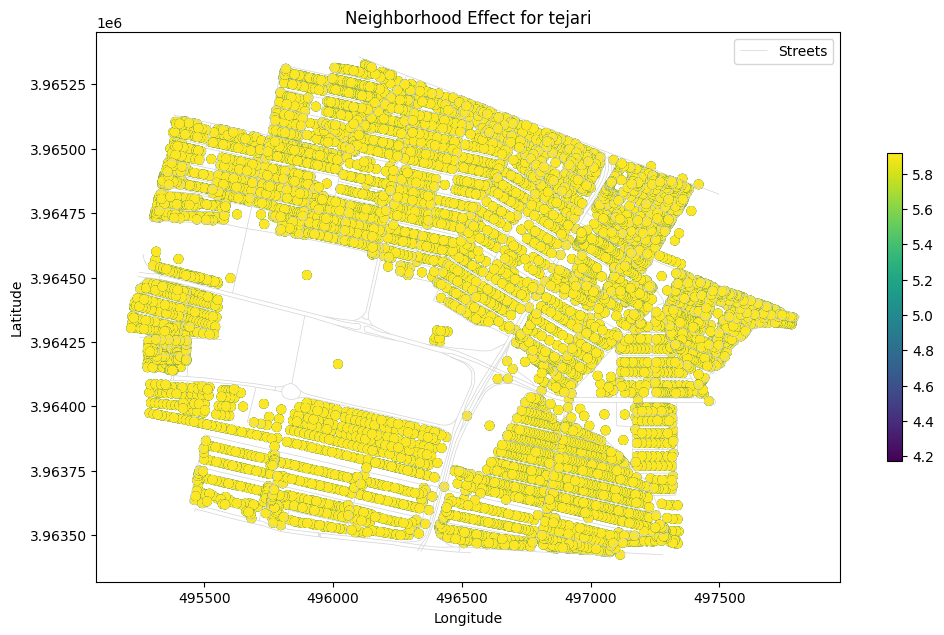

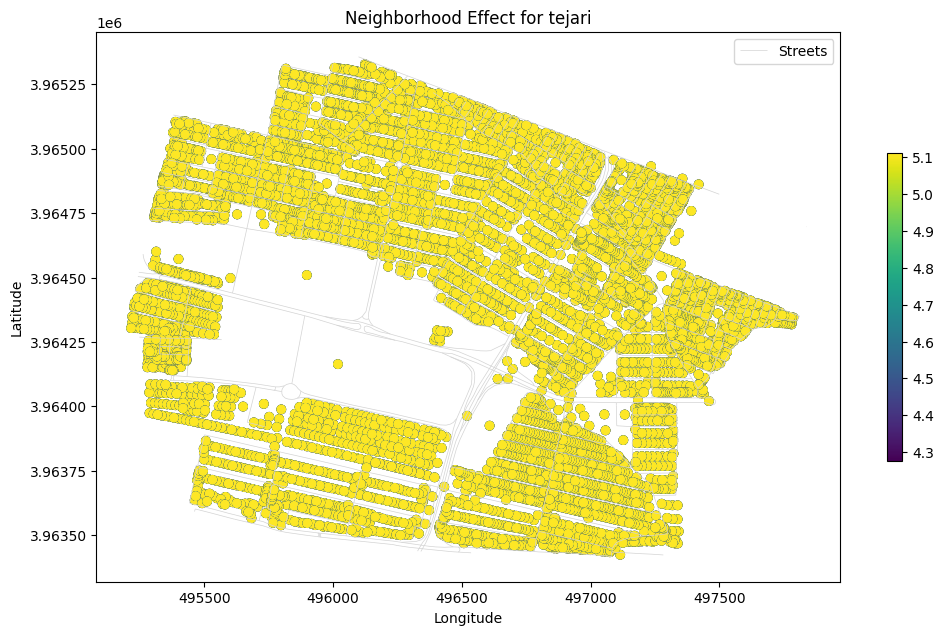

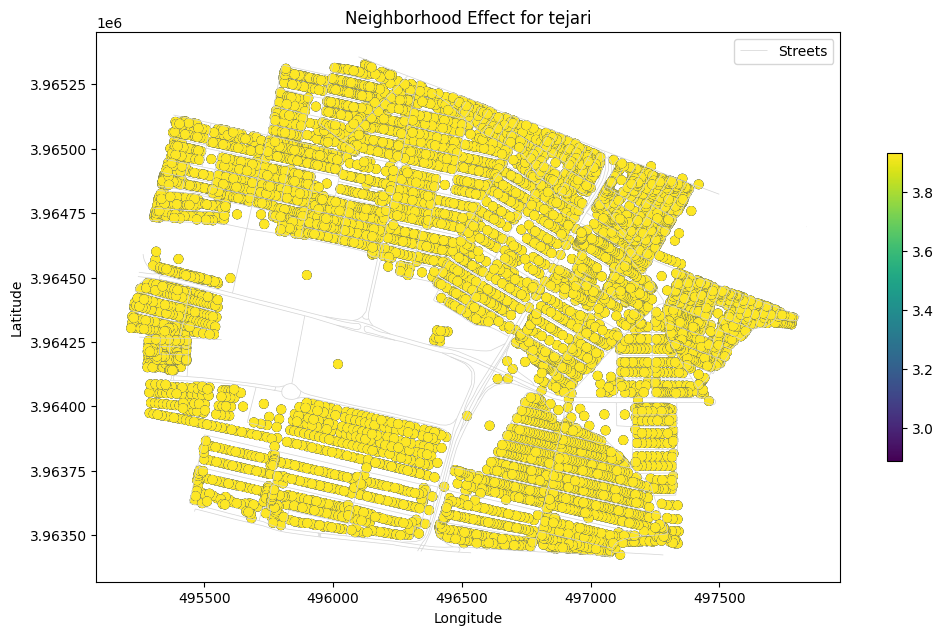

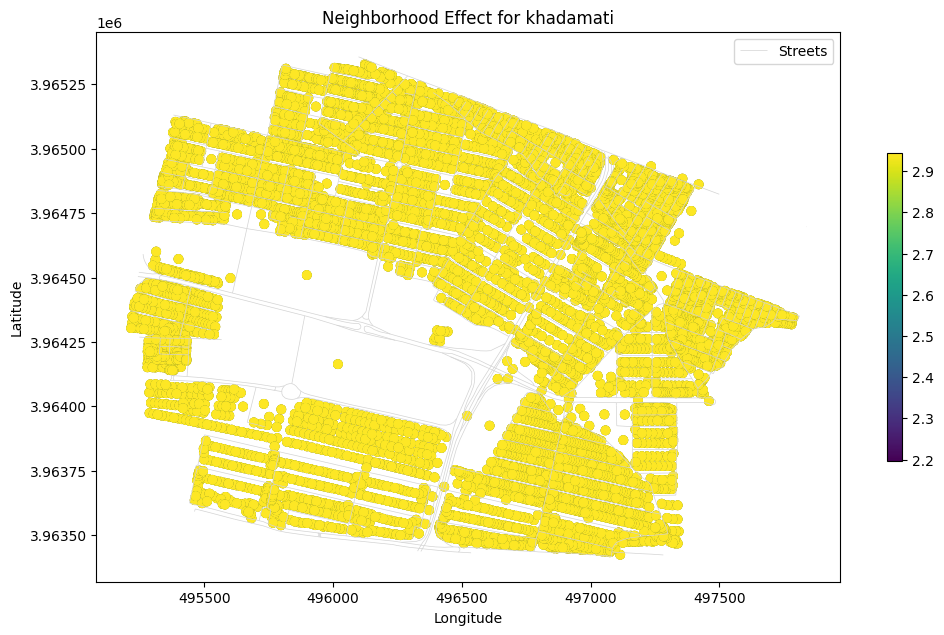

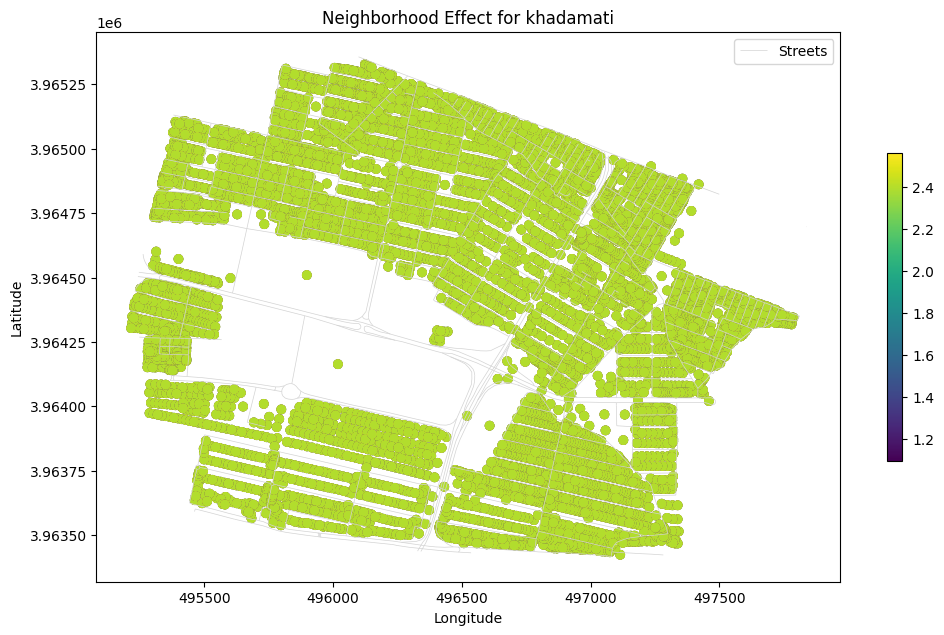

...

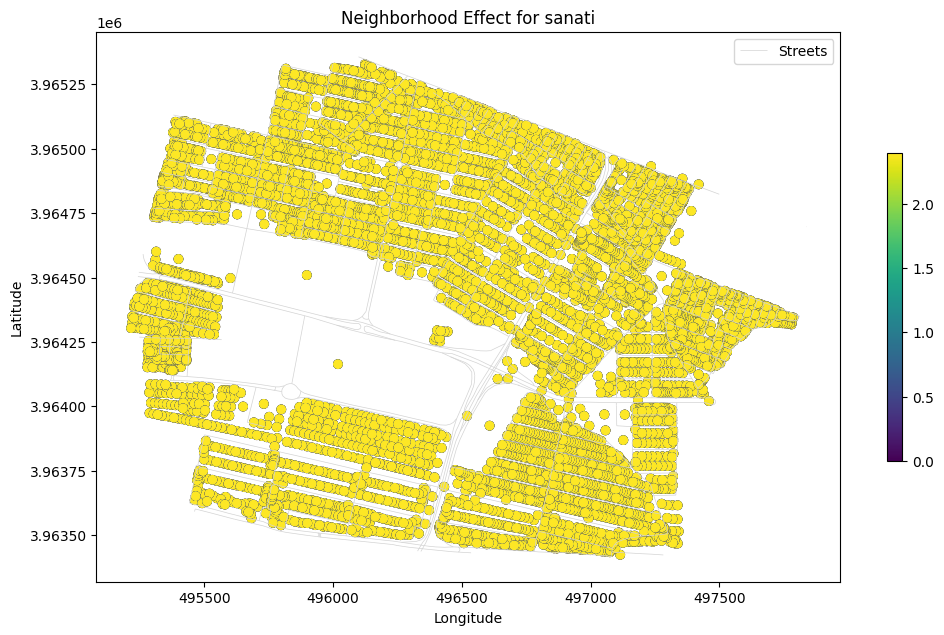

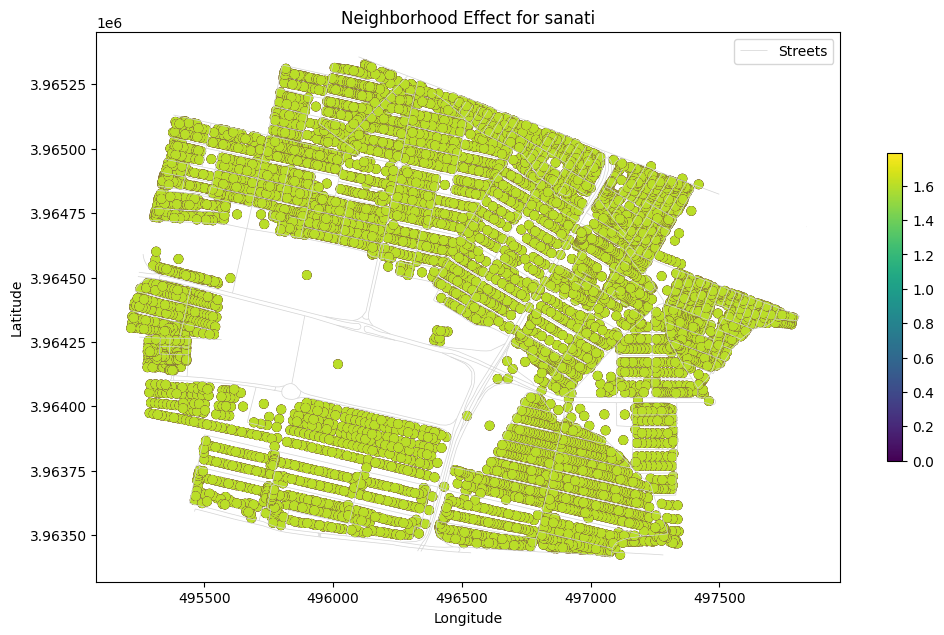

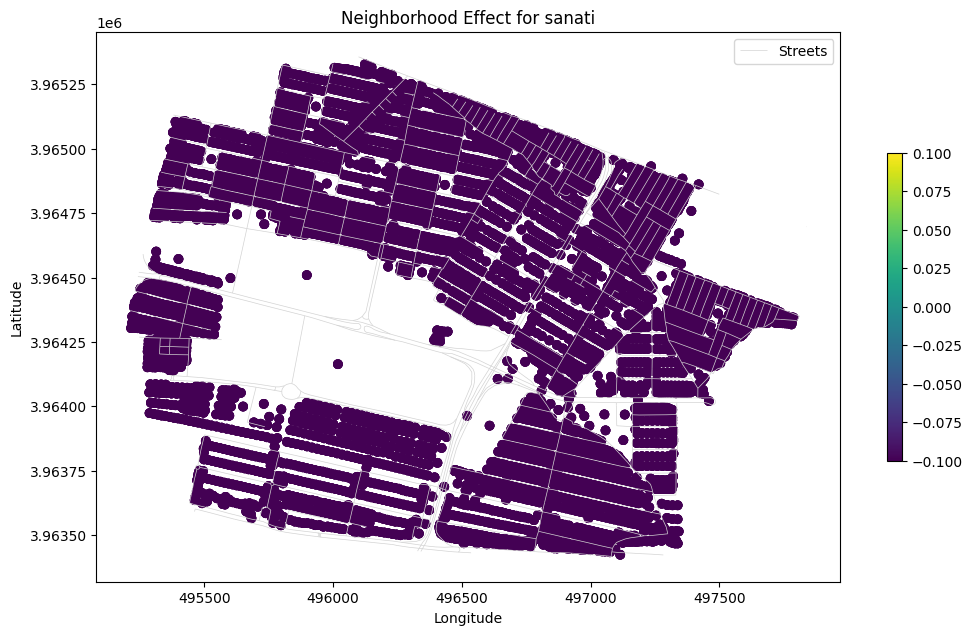

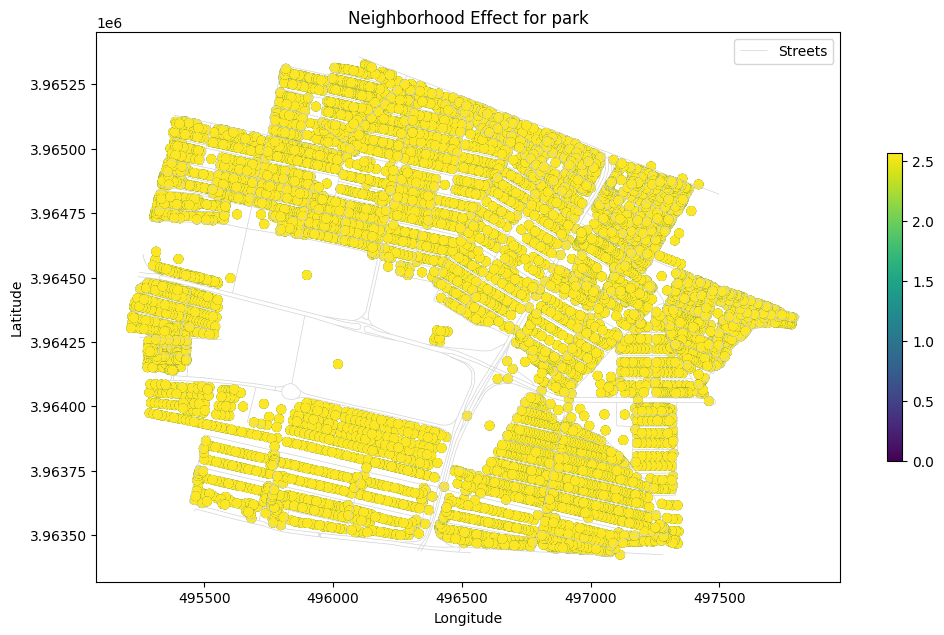

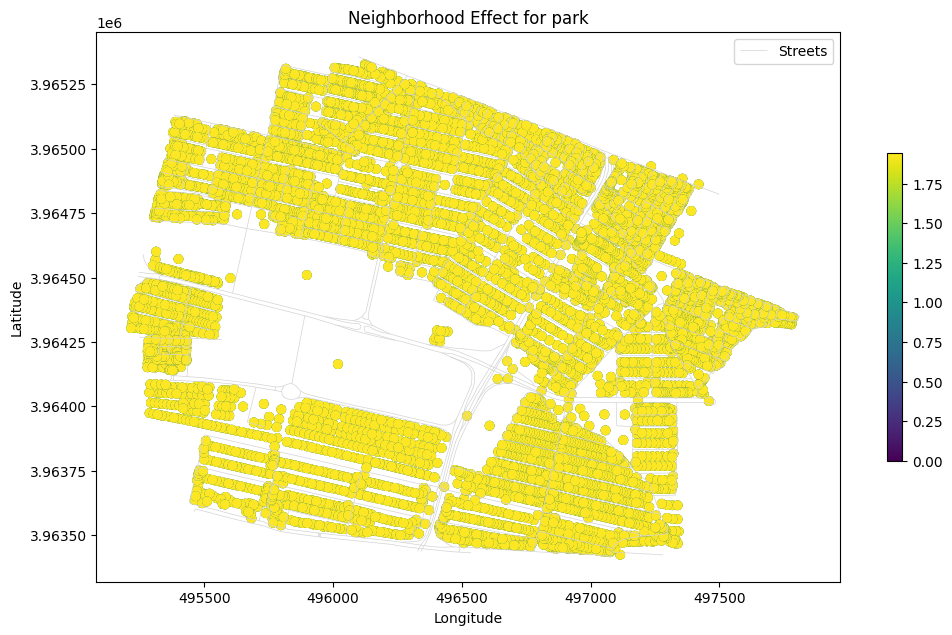

KeyboardInterrupt: 

In [ ]:
def plot_neighborhood_effect_map(aggregated_effect_map, label, cmap):
    fig, ax = plt.subplots(1, 1, figsize=(12, 8))

    # Plot the street data for reference
    street_data.plot(ax=ax, color='lightgrey', linewidth=0.5, label='Streets')

    effect_map_label = aggregated_effect_map[aggregated_effect_map['label'] == label]
    effect_map_label.plot(column='effect_value', ax=ax, legend=True, cmap=cmap, legend_kwds={'shrink': 0.5})

    plt.legend()
    plt.title(f'Neighborhood Effect for {label}')
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.show()


# Plotting the neighborhood effect maps for maskooni, tejari, and park using a different colormap
cmap = 'viridis'

for label in labels_of_interest:
    plot_neighborhood_effect_map(aggregated_effect_map_maskooni, label, cmap)
    plot_neighborhood_effect_map(aggregated_effect_map_tejari, label, cmap)
    plot_neighborhood_effect_map(aggregated_effect_map_park, label, cmap)

In [ ]:
from shapely.geometry import MultiPoint

# Extract the first 50 centroids
sample_centroids_gdf = centroids_gdf.iloc[:50].reset_index(drop=True)

# Create a bounding box around the first 50 centroids
bounding_box = MultiPoint([point for point in sample_centroids_gdf['centroid']]).envelope

In [ ]:
# Filter landuse_gdf to include only those within the bounding box
landuse_within_bbox_gdf = landuse_gdf[landuse_gdf.within(bounding_box)].copy()

# Define distance ranges (in meters)
distance_ranges = [50, 100, 150, 200]

# Initialize the enrichment_factor column
landuse_within_bbox_gdf['enrichment_factor'] = 0

Applying enrichment factors for land use type: maskooni
Initial enrichment factors: {'0-50 meters': {'tejari': 65, 'khadamati': 9, 'maskooni': 392, 'sanati': 1, 'park': 0}, '50-100 meters': {'tejari': 137, 'khadamati': 18, 'maskooni': 338, 'sanati': 1, 'park': 4}, '100-150 meters': {'tejari': 249, 'khadamati': 18, 'maskooni': 664, 'sanati': 3, 'park': 11}, '150-200 meters': {'tejari': 372, 'khadamati': 19, 'maskooni': 956, 'sanati': 11, 'park': 13}}
Number of serviceable polygons at distance 50: 2907
Number of serviceable polygons at distance 100: 2907
Number of serviceable polygons at distance 150: 2907
Number of serviceable polygons at distance 200: 2907
Applying enrichment factors for land use type: tejari
Initial enrichment factors: {'0-50 meters': {'tejari': 83, 'khadamati': 7, 'maskooni': 75, 'sanati': 6, 'park': 1}, '50-100 meters': {'tejari': 72, 'khadamati': 3, 'maskooni': 177, 'sanati': 0, 'park': 5}, '100-150 meters': {'tejari': 122, 'khadamati': 13, 'maskooni': 219, 'sanati

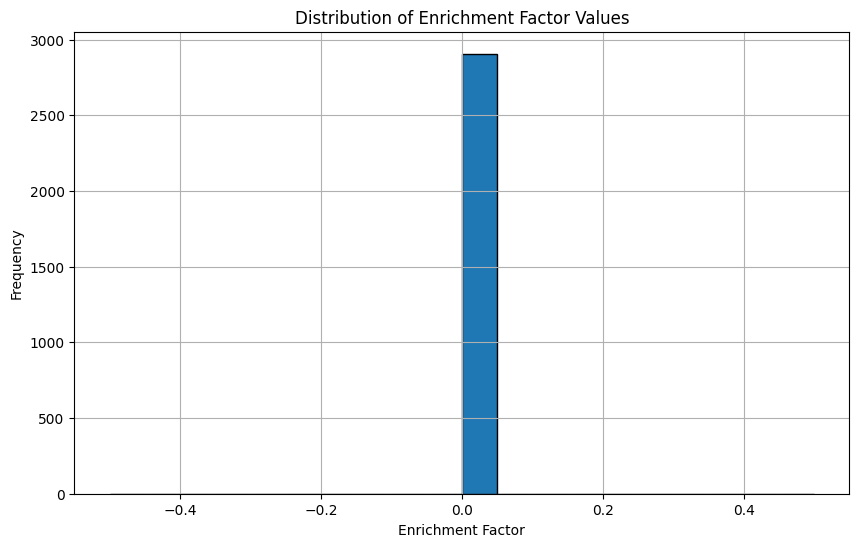

In [ ]:
# Function to apply enrichment factors within the bounding box
def apply_enrichment_factors_within_bbox(gdf, distance_ranges, enrichment_factors):
    print(f"Initial enrichment factors: {enrichment_factors}")

    for distance_idx, distance in enumerate(distance_ranges):
        buffered_streets = streets_gdf.buffer(distance)
        serviceable_polygons = gdf[gdf.geometry.apply(lambda poly: any(poly.intersects(buffer) for buffer in buffered_streets))]

        print(f"Number of serviceable polygons at distance {distance}: {len(serviceable_polygons)}")

        range_key = distance_ranges[distance_idx]

        if range_key in enrichment_factors:
            for land_use_type in enrichment_factors[range_key]:
                same_landuse_polygons = serviceable_polygons[serviceable_polygons['landuse2'] == land_use_type]

                # Debug: Print the indices of polygons being updated and the corresponding enrichment factor
                print(f"Applying enrichment factor {enrichment_factors[range_key][land_use_type]} for land use {land_use_type} at distance {distance}")
                print(f"Indices of serviceable polygons of type {land_use_type}: {same_landuse_polygons.index.tolist()}")

                if not same_landuse_polygons.empty:
                    gdf.loc[same_landuse_polygons.index, 'enrichment_factor'] = enrichment_factors[range_key][land_use_type]
                else:
                    print(f"No polygons of type {land_use_type} found at distance {distance}")

    return gdf

# Apply enrichment factors for each land use type
for land_use_type, e_factors in enrichment_factors_dict.items():
    print(f"Applying enrichment factors for land use type: {land_use_type}")
    landuse_within_bbox_gdf = apply_enrichment_factors_within_bbox(landuse_within_bbox_gdf, distance_ranges, e_factors)

# Check the unique values and counts again
unique_enrichment_factors = landuse_within_bbox_gdf['enrichment_factor'].unique()
print(f"Unique enrichment factor values after applying: {unique_enrichment_factors}")

enrichment_factor_counts = landuse_within_bbox_gdf['enrichment_factor'].value_counts()
print(enrichment_factor_counts)

# Plot the histogram to visualize the distribution of enrichment factors
plt.figure(figsize=(10, 6))
plt.hist(landuse_within_bbox_gdf['enrichment_factor'], bins=20, edgecolor='black')
plt.title('Distribution of Enrichment Factor Values')
plt.xlabel('Enrichment Factor')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

Processing Neighborhood Effects:   0%|          | 0/5 [00:00<?, ?it/s]

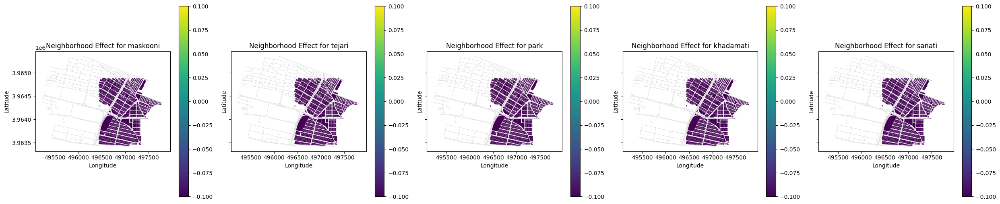

In [ ]:
fig, axes = plt.subplots(5, 5, figsize=(25, 25), sharey=True)
axes = axes.flatten()

# Define land use types to analyze (excluding "bayer")
land_use_types = ["maskooni", "tejari", "park", "khadamati", "sanati"]

# Process each land use type for neighborhood effect maps
for idx, land_use_type in enumerate(tqdm(land_use_types, desc="Processing Neighborhood Effects")):
    ax = axes[idx]

    # Plot the neighborhood effect
    landuse_within_bbox_gdf.plot(column='enrichment_factor', ax=ax, legend=True, cmap='viridis')
    streets_gdf.plot(ax=ax, color='lightgrey', linewidth=0.5, label='Streets')
    ax.set_title(f'Neighborhood Effect for {land_use_type}')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')

# Hide any unused subplots in the neighborhood effect maps
for j in range(len(land_use_types), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [ ]:
unique_enrichment_factors = landuse_within_bbox_gdf['enrichment_factor'].unique()
print(f"Unique enrichment factor values: {unique_enrichment_factors}")

Unique enrichment factor values: [0]


In [ ]:
enrichment_factor_counts = landuse_within_bbox_gdf['enrichment_factor'].value_counts()
print(enrichment_factor_counts)

enrichment_factor
0    2907
Name: count, dtype: int64


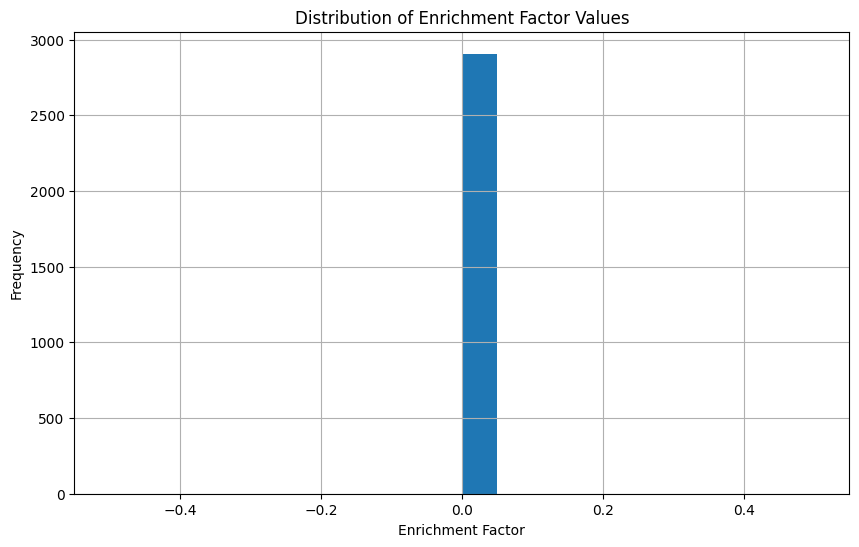

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
landuse_within_bbox_gdf['enrichment_factor'].hist(bins=20)
plt.title('Distribution of Enrichment Factor Values')
plt.xlabel('Enrichment Factor')
plt.ylabel('Frequency')
plt.show()

In [ ]:
# Initialize the plot for neighborhood effect maps
fig, axes = plt.subplots(5, 5, figsize=(25, 25), sharey=True)
axes = axes.flatten()

# Process each land use type for neighborhood effect maps
for idx, land_use_type in enumerate(tqdm(land_use_types, desc="Processing Neighborhood Effects")):
    # Initialize the enrichment_factor column
    landuse_within_bbox_gdf['enrichment_factor'] = 0

    # Use pre-calculated enrichment factors for the current land use type
    enrichment_factors = enrichment_factors_dict[land_use_type]

    for distance_idx, distance in enumerate(distance_ranges):
        buffered_streets = streets_gdf.buffer(distance)
        serviceable_polygons = landuse_within_bbox_gdf[landuse_within_bbox_gdf.geometry.apply(lambda poly: any(poly.intersects(buffer) for buffer in buffered_streets))]
        landuse_within_bbox_gdf.loc[serviceable_polygons.index, 'enrichment_factor'] = enrichment_factors[distance_idx]

    # Plot the neighborhood effect
    ax = axes[idx]
    landuse_within_bbox_gdf.plot(column='enrichment_factor', ax=ax, legend=True, cmap='viridis')
    streets_gdf.plot(ax=ax, color='lightgrey', linewidth=0.5, label='Streets')
    ax.set_title(f'Neighborhood Effect for {land_use_type}')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')

# Hide any unused subplots in the neighborhood effect maps
for j in range(len(land_use_types), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


/usr/local/lib/python3.10/dist-packages/geopandas/geodataframe.py:1538: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
Processing Centroids for maskooni: 100%|██████████| 4/4 [01:30<00:00, 22.68s/it]
/usr/local/lib/python3.10/dist-packages/geopandas/geodataframe.py:1538: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
Processing Centroids for tejari: 100%|██████████| 4/4 [01:31<00:00, 22.90s/it]
/usr/local/lib/python3.10/dist-packages/geopandas/ge

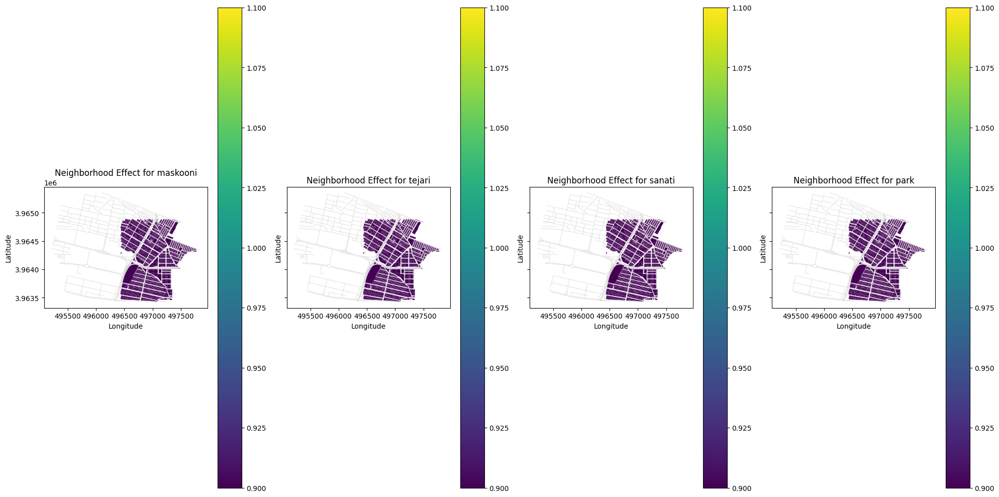

In [ ]:
bounding_box = MultiPoint([point for point in sample_centroids_gdf['centroid']]).envelope

# Filter landuse_gdf to include only those within the bounding box
landuse_within_bbox_gdf = landuse_gdf[landuse_gdf.within(bounding_box)]

# Define distance ranges (in meters)
distance_ranges = [50, 100, 150, 200]

# Function to calculate enrichment factors for given land use type within bounding box
def calculate_enrichment_factors_within_bbox(gdf, distance_ranges, land_use_type):
    total_area = gdf[gdf['landuse2'] == land_use_type]['SHAPE_Area'].sum()
    enrichment_factors = []

    for distance in distance_ranges:
        buffered_streets = streets_gdf.buffer(distance)
        serviceable_polygons = gdf[gdf.geometry.apply(lambda poly: any(poly.intersects(buffer) for buffer in buffered_streets))]
        serviceable_area = serviceable_polygons[serviceable_polygons['landuse2'] == land_use_type]['SHAPE_Area'].sum()

        enrichment_factor = (serviceable_area / total_area) if total_area > 0 else 0
        enrichment_factors.append(enrichment_factor)

    return enrichment_factors

# Initialize the plot
fig, axes = plt.subplots(1, len(land_use_types), figsize=(20, 10), sharey=True)

# Process each land use type
for idx, land_use_type in enumerate(land_use_types):
    # Initialize the enrichment_factor column
    landuse_within_bbox_gdf['enrichment_factor'] = 0

    # Calculate enrichment factors for the current land use type within the bounding box
    for distance_idx, sample_point in tqdm(enumerate(distance_ranges), total=len(distance_ranges), desc=f"Processing Centroids for {land_use_type}"):
        enrichment_factors = calculate_enrichment_factors_within_bbox(landuse_within_bbox_gdf, distance_ranges, land_use_type)

        buffered_streets = streets_gdf.buffer(distance_ranges[distance_idx])
        serviceable_polygons = landuse_within_bbox_gdf[landuse_within_bbox_gdf.geometry.apply(lambda poly: any(poly.intersects(buffer) for buffer in buffered_streets))]
        landuse_within_bbox_gdf.loc[serviceable_polygons.index, 'enrichment_factor'] = enrichment_factors[distance_idx]

    # Plot the neighborhood effect
    ax = axes[idx]
    landuse_within_bbox_gdf.plot(column='enrichment_factor', ax=ax, legend=True, cmap='viridis')
    streets_gdf.plot(ax=ax, color='lightgrey', linewidth=0.5, label='Streets')
    ax.set_title(f'Neighborhood Effect for {land_use_type}')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')

plt.tight_layout()
plt.show()

Processing Land Uses: 100%|██████████| 5/5 [09:01<00:00, 108.20s/it]


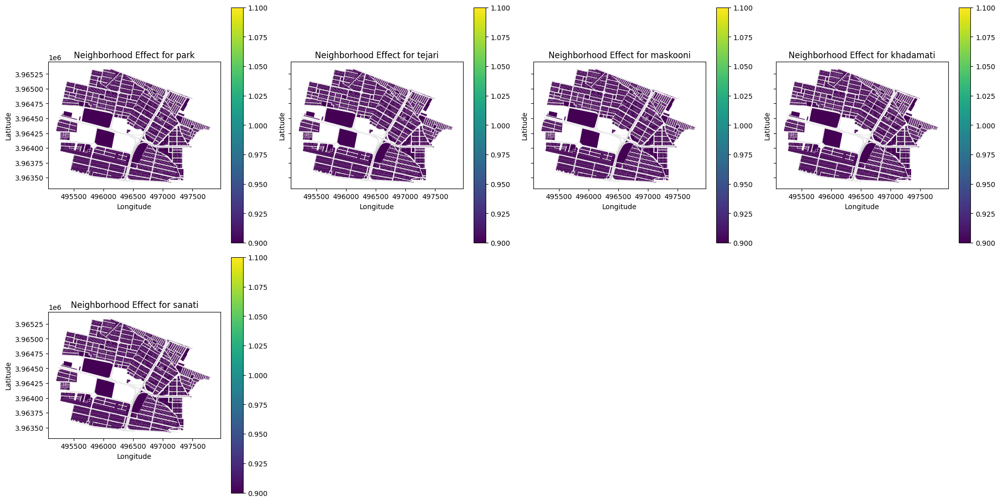

In [ ]:
land_use_types = [use for use in landuse_gdf['landuse2'].unique() if use != 'bayer']

# Calculate centroids
landuse_gdf['centroid'] = landuse_gdf.centroid
centroids_gdf = gpd.GeoDataFrame(landuse_gdf[['landuse2', 'SHAPE_Area', 'centroid']], geometry='centroid')

# Define distance ranges (in meters)
distance_ranges = [50, 100, 150, 200]

# Function to calculate enrichment factors for given land use type
def calculate_enrichment_factors(gdf, distance_ranges, land_use_type):
    total_area = gdf[gdf['landuse2'] == land_use_type]['SHAPE_Area'].sum()
    enrichment_factors = []

    for distance in distance_ranges:
        buffered_streets = streets_gdf.buffer(distance)
        serviceable_polygons = gdf[gdf.geometry.apply(lambda poly: any(poly.intersects(buffer) for buffer in buffered_streets))]
        serviceable_area = serviceable_polygons[serviceable_polygons['landuse2'] == land_use_type]['SHAPE_Area'].sum()

        enrichment_factor = (serviceable_area / total_area) if total_area > 0 else 0
        enrichment_factors.append(enrichment_factor)

    return enrichment_factors

# Initialize the plot
fig, axes = plt.subplots(1, 5, figsize=(20, 20), sharey=True)
axes = axes.flatten()

# Process each land use type
for idx, land_use_type in enumerate(tqdm(land_use_types, desc="Processing Land Uses")):
    # Initialize the enrichment_factor column
    landuse_gdf['enrichment_factor'] = 0

    # Calculate enrichment factors for the current land use type
    enrichment_factors = calculate_enrichment_factors(landuse_gdf, distance_ranges, land_use_type)

    for distance_idx, distance in enumerate(distance_ranges):
        buffered_streets = streets_gdf.buffer(distance)
        serviceable_polygons = landuse_gdf[landuse_gdf.geometry.apply(lambda poly: any(poly.intersects(buffer) for buffer in buffered_streets))]
        landuse_gdf.loc[serviceable_polygons.index, 'enrichment_factor'] = enrichment_factors[distance_idx]

    # Plot the neighborhood effect
    ax = axes[idx]
    landuse_gdf.plot(column='enrichment_factor', ax=ax, legend=True, cmap='viridis')
    streets_gdf.plot(ax=ax, color='lightgrey', linewidth=0.5, label='Streets')
    ax.set_title(f'Neighborhood Effect for {land_use_type}')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')

# Hide any unused subplots
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Calculating and Plotting EF: 100%|██████████| 5/5 [21:46<00:00, 261.24s/it]


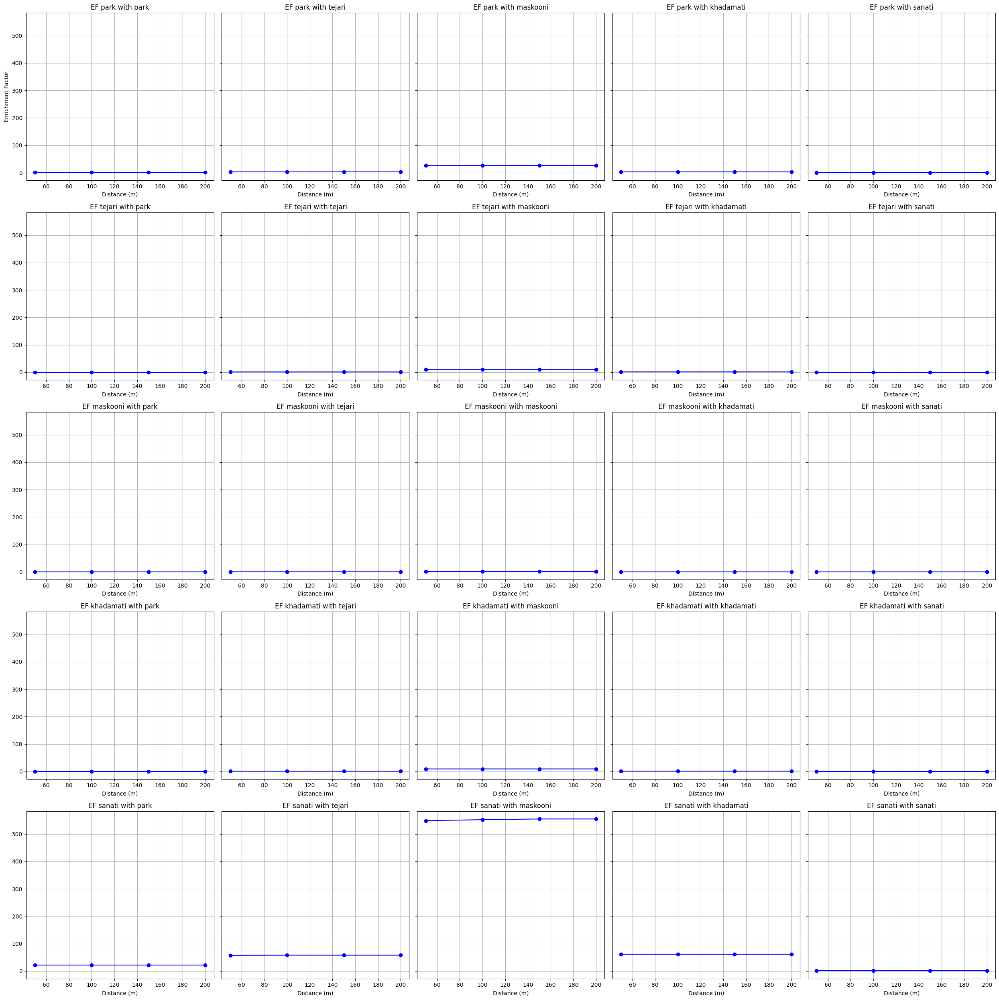

In [ ]:
land_use_types = [use for use in landuse_gdf['landuse2'].unique() if use != 'bayer']

# Calculate centroids
landuse_gdf['centroid'] = landuse_gdf.centroid
centroids_gdf = gpd.GeoDataFrame(landuse_gdf[['landuse2', 'SHAPE_Area', 'centroid']], geometry='centroid')

# Define distance ranges (in meters)
distance_ranges = [50, 100, 150, 200]

# Function to calculate enrichment factors for given land use type
def calculate_enrichment_factors(gdf, distance_ranges, centroid_land_use, target_land_use):
    total_area = gdf[gdf['landuse2'] == centroid_land_use]['SHAPE_Area'].sum()
    enrichment_factors = []

    for distance in distance_ranges:
        buffered_streets = streets_gdf.buffer(distance)
        serviceable_polygons = gdf[gdf.geometry.apply(lambda poly: any(poly.intersects(buffer) for buffer in buffered_streets))]
        serviceable_area = serviceable_polygons[serviceable_polygons['landuse2'] == target_land_use]['SHAPE_Area'].sum()

        enrichment_factor = (serviceable_area / total_area) if total_area > 0 else 0
        enrichment_factors.append(enrichment_factor)

    return enrichment_factors

# Initialize the plot for enrichment factors
fig_ef, axes_ef = plt.subplots(5, 5, figsize=(25, 25), sharey=True)
axes_ef = axes_ef.flatten()

# Calculate and plot the enrichment factors for each combination of land use types
for i, centroid_land_use in enumerate(tqdm(land_use_types, desc="Calculating and Plotting EF")):
    for j, target_land_use in enumerate(land_use_types):
        idx = i * 5 + j
        ax = axes_ef[idx]

        # Calculate enrichment factors
        enrichment_factors = calculate_enrichment_factors(landuse_gdf, distance_ranges, centroid_land_use, target_land_use)

        # Plot enrichment factors
        ax.plot(distance_ranges, enrichment_factors, marker='o', linestyle='-', color='b')
        ax.set_xlabel('Distance (m)')
        ax.set_title(f'EF {centroid_land_use} with {target_land_use}')
        ax.grid(True)

axes_ef[0].set_ylabel('Enrichment Factor')

# Hide any unused subplots in the enrichment factor plots
for j in range(len(land_use_types) * len(land_use_types), len(axes_ef)):
    fig_ef.delaxes(axes_ef[j])

plt.tight_layout()
plt.show()

Processing Neighborhood Effects: 100%|██████████| 5/5 [45:02<00:00, 540.43s/it]


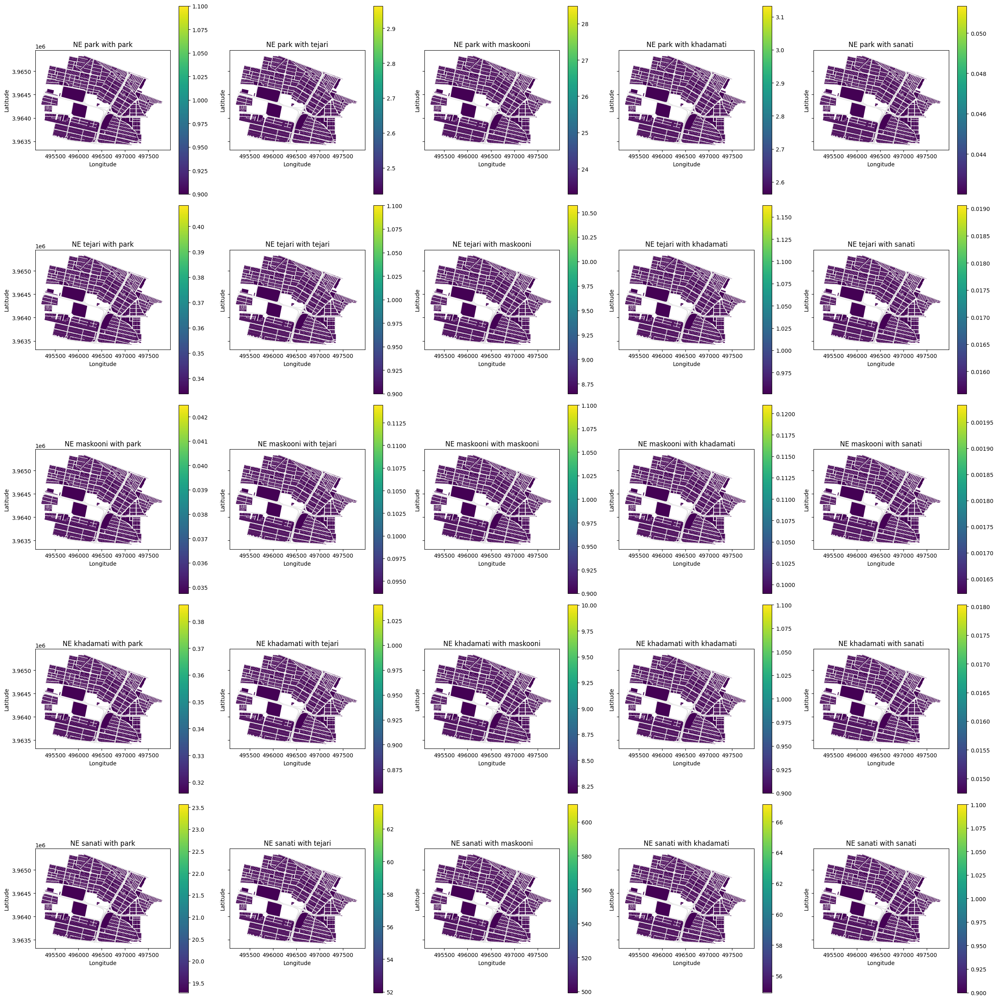

In [ ]:
# Initialize the plot for neighborhood effect maps
fig_ne, axes_ne = plt.subplots(5, 5, figsize=(25, 25), sharey=True)
axes_ne = axes_ne.flatten()

# Process each land use type for neighborhood effect maps
for i, centroid_land_use in enumerate(tqdm(land_use_types, desc="Processing Neighborhood Effects")):
    for j, target_land_use in enumerate(land_use_types):
        idx = i * 5 + j
        ax = axes_ne[idx]

        # Initialize the enrichment_factor column
        landuse_gdf['enrichment_factor'] = 0

        # Use pre-calculated enrichment factors for the current land use type
        enrichment_factors = calculate_enrichment_factors(landuse_gdf, distance_ranges, centroid_land_use, target_land_use)

        for distance_idx, distance in enumerate(distance_ranges):
            buffered_streets = streets_gdf.buffer(distance)
            serviceable_polygons = landuse_gdf[landuse_gdf.geometry.apply(lambda poly: any(poly.intersects(buffer) for buffer in buffered_streets))]
            landuse_gdf.loc[serviceable_polygons.index, 'enrichment_factor'] = enrichment_factors[distance_idx]

        # Plot the neighborhood effect
        landuse_gdf.plot(column='enrichment_factor', ax=ax, legend=True, cmap='viridis')
        streets_gdf.plot(ax=ax, color='lightgrey', linewidth=0.5, label='Streets')
        ax.set_title(f'NE {centroid_land_use} with {target_land_use}')
        ax.set_xlabel('Longitude')
        ax.set_ylabel('Latitude')

# Hide any unused subplots in the neighborhood effect maps
for j in range(len(land_use_types) * len(land_use_types), len(axes_ne)):
    fig_ne.delaxes(axes_ne[j])

plt.tight_layout()
plt.show()


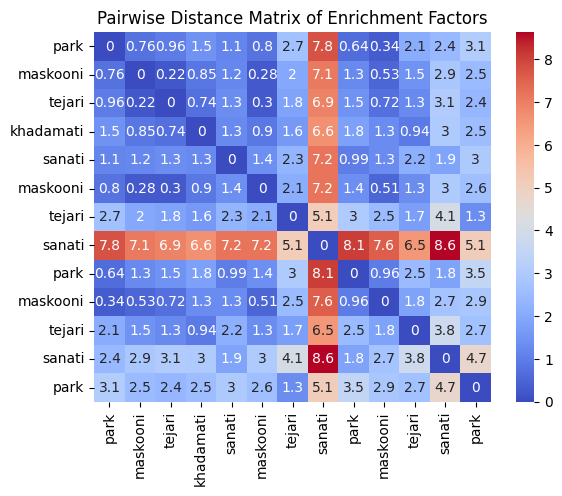

In [ ]:
from scipy.spatial.distance import pdist, squareform
import seaborn as sns

# Combine enrichment factors into a single DataFrame
enrichment_factors_df = pd.DataFrame(enrichment_factors).T
tejari_enrichment_factors_df = pd.DataFrame(tejari_enrichment_factors).T
park_enrichment_factors_df = pd.DataFrame(park_enrichment_factors).T

# Concatenate all enrichment factors
all_enrichment_factors_df = pd.concat([enrichment_factors_df, tejari_enrichment_factors_df, park_enrichment_factors_df], axis=1)

# Calculate pairwise distances (Euclidean distance)
distance_matrix = pd.DataFrame(squareform(pdist(all_enrichment_factors_df.T, metric='euclidean')),
                               index=all_enrichment_factors_df.columns,
                               columns=all_enrichment_factors_df.columns)

# Display the distance matrix
sns.heatmap(distance_matrix, cmap='coolwarm', annot=True)
plt.title('Pairwise Distance Matrix of Enrichment Factors')
plt.show()

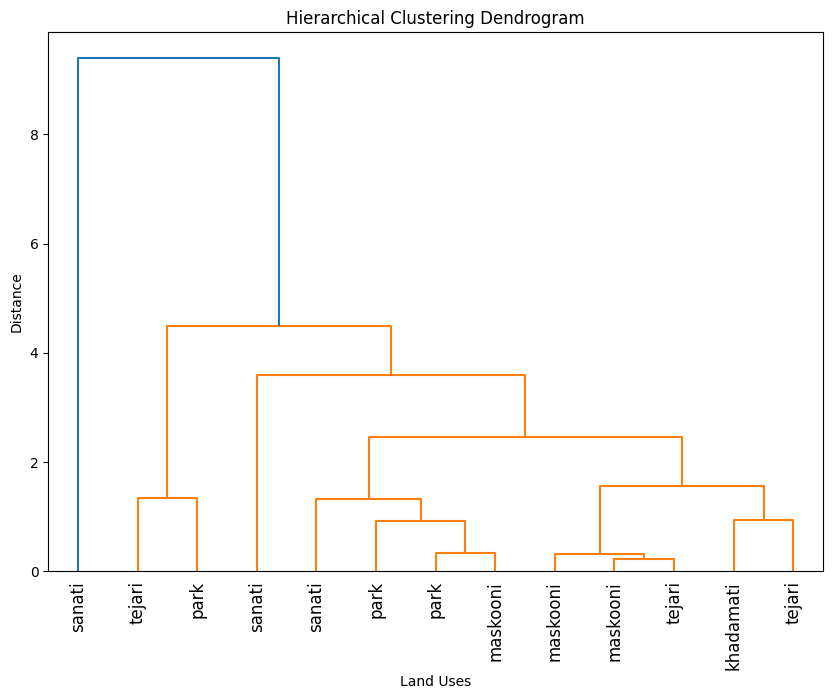

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage

# Perform hierarchical clustering
Z = linkage(pdist(all_enrichment_factors_df.T, metric='euclidean'), method='ward')

# Plot the dendrogram
plt.figure(figsize=(10, 7))
dendrogram(Z, labels=all_enrichment_factors_df.columns, leaf_rotation=90)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Land Uses')
plt.ylabel('Distance')
plt.show()


/usr/local/lib/python3.10/dist-packages/sklearn/manifold/_mds.py:299: FutureWarning: The default value of `normalized_stress` will change to `'auto'` in version 1.4. To suppress this warning, manually set the value of `normalized_stress`.
  warnings.warn(


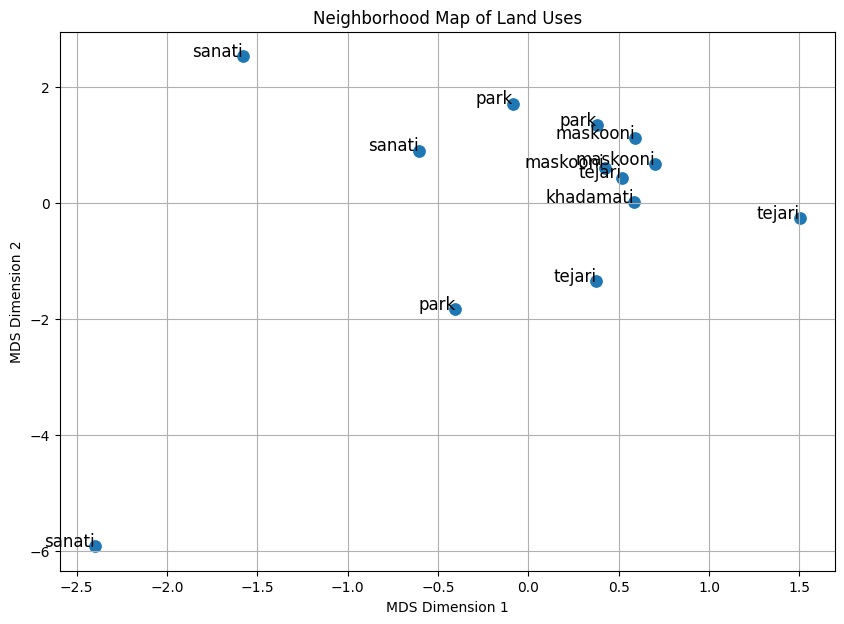

In [ ]:
from sklearn.manifold import MDS

# Apply MDS to reduce dimensions to 2
mds = MDS(n_components=2, dissimilarity='precomputed', random_state=0)
mds_coords = mds.fit_transform(distance_matrix)

# Create a DataFrame with MDS coordinates
mds_df = pd.DataFrame(mds_coords, index=distance_matrix.index, columns=['x', 'y'])

# Plot the neighborhood map
plt.figure(figsize=(10, 7))
sns.scatterplot(data=mds_df, x='x', y='y', s=100)

# Annotate points with their labels
for label, (x, y) in mds_df.iterrows():
    plt.text(x, y, label, fontsize=12, ha='right')

plt.title('Neighborhood Map of Land Uses')
plt.xlabel('MDS Dimension 1')
plt.ylabel('MDS Dimension 2')
plt.grid(True)
plt.show()


In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, LineString, MultiLineString
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.neighbors import KDTree

def nearest_node(street_graph, pos, point):
    distances = {node: Point(x, y).distance(point) for node, (x, y) in pos.items()}
    nearest = min(distances, key=distances.get)
    return nearest

def select_points_in_annulus(points_gdf, center_objectid, inner_radius, outer_radius):
    center_point = points_gdf.loc[points_gdf['OBJECTID'] == center_objectid].geometry.values[0]
    distances = points_gdf.geometry.apply(lambda x: center_point.distance(x))
    annulus_points = points_gdf[(distances > inner_radius) & (distances <= outer_radius)]
    return annulus_points

def euclidean_distance(point1, point2):
    return point1.distance(point2)

def calculate_neighborhood_effects_by_landuse(landuse_points, street_graph, pos, enrichment_factors, distance_matrix):
    neighborhood_effects_by_landuse = {landuse: {} for landuse in landuse_points['landuse2'].unique()}
    for landuse in neighborhood_effects_by_landuse:
        landuse_points_subset = landuse_points[landuse_points['landuse2'] == landuse]
        for index, center_point in landuse_points_subset.iterrows():
            center_objectid = center_point['OBJECTID']
            neighborhood_effect = 0
            center_node = nearest_node(street_graph, pos, center_point['geometry'])
            for inner, outer in [(0, 25), (25, 50), (50, 75), (75, 100)]:
                neighbors = select_points_in_annulus(landuse_points, center_objectid, inner, outer)
                for _, neighbor in neighbors.iterrows():
                    neighbor_objectid = neighbor['OBJECTID']
                    neighbor_landuse = neighbor['landuse2']
                    neighbor_distance = distance_matrix.loc[center_objectid, neighbor_objectid]
                    if np.isinf(neighbor_distance) or neighbor_distance == 0:
                        neighbor_distance = euclidean_distance(center_point['geometry'], neighbor['geometry'])
                    enrichment_factor = enrichment_factors.get((landuse, neighbor_landuse))
                    if enrichment_factor is None:
                        continue
                    neighbor_effect = enrichment_factor[(inner, outer)] * neighbor_distance
                    neighborhood_effect += neighbor_effect
            neighborhood_effects_by_landuse[landuse][center_objectid] = neighborhood_effect
    return neighborhood_effects_by_landuse

In [ ]:
def normalize_columns(df, columns):
    for col in columns:
        max_val = df[col].max()
        min_val = df[col].min()
        df[col] = (df[col] - min_val) / (max_val - min_val) * 0.9
    return df

In [ ]:
def join_neighborhood_effects(landuse_gdf, landuse_points, neighborhood_effects_by_landuse):
    for landuse, neighborhood_effects in neighborhood_effects_by_landuse.items():
        landuse_points[f'neighborhood_effect_{landuse}'] = landuse_points['OBJECTID'].map(neighborhood_effects)
    columns_to_join = ['OBJECTID'] + [f'neighborhood_effect_{landuse}' for landuse in neighborhood_effects_by_landuse]
    landuse_gdf = landuse_gdf.merge(landuse_points[columns_to_join], on='OBJECTID', how='left')
    return landuse_gdf

In [ ]:
def plot_neighborhood_effects(landuse_gdf, neighborhood_effects_columns):
    for column in neighborhood_effects_columns:
        fig, ax = plt.subplots(figsize=(10, 10))
        landuse_gdf.plot(column=column, ax=ax, cmap='viridis', legend=True)
        ax.set_title(f'Neighborhood Effect for {column}')
        plt.show()

In [ ]:
# Assuming you have already loaded your dataframes:
landuse_gdf = gpd.read_file('land_uset.shp')
restrictions_gdf = gpd.read_file('restrictiont.shp')
streets_gdf = gpd.read_file('street.shp')

# Calculate centroids
landuse_gdf['centroid'] = landuse_gdf.centroid
centroids_gdf = gpd.GeoDataFrame(landuse_gdf[['landuse2', 'SHAPE_Area', 'centroid']], geometry='centroid')

# Create street network graph
street_network = nx.Graph()
def add_edges_from_line(line):
    coordinates = list(line.coords)
    for i in range(len(coordinates) - 1):
        start_point = Point(coordinates[i])
        end_point = Point(coordinates[i + 1])
        street_network.add_edge((start_point.x, start_point.y), (end_point.x, end_point.y), weight=start_point.distance(end_point))

for index, row in streets_gdf.iterrows():
    if isinstance(row.geometry, LineString):
        add_edges_from_line(row.geometry)
    elif isinstance(row.geometry, MultiLineString):
        for line in row.geometry:
            add_edges_from_line(line)

positions = {node: node for node in street_network.nodes()}

# Calculate distance matrix (using the previously defined street network)
distance_matrix = nx.adjacency_matrix(street_network)
distance_df = pd.DataFrame(distance_matrix.todense())

# Placeholder for enrichment factors dictionary
enrichment_factors = {}  # Replace with your actual enrichment factors dictionary

# Calculate neighborhood effects
neighborhood_effects_by_landuse = calculate_neighborhood_effects_by_landuse(
    landuse_gdf, street_network, positions, enrichment_factors, distance_df
)

# Normalize the neighborhood effects
columns_to_normalize = [f'neighborhood_effect_{landuse}' for landuse in neighborhood_effects_by_landuse]
landuse_gdf = normalize_columns(landuse_gdf, columns_to_normalize)

# Join the normalized effects back to the main GeoDataFrame
landuse_gdf = join_neighborhood_effects(landuse_gdf, landuse_gdf, neighborhood_effects_by_landuse)

# Plot the neighborhood effects
plot_neighborhood_effects(landuse_gdf, columns_to_normalize)

KeyError: 3142

In [ ]:

labels = sample_50_centroids_gdf['landuse2'].unique()
labels = [label for label in labels if label != "bayer"]

total_area_50_samples = sample_50_centroids_gdf[sample_50_centroids_gdf['landuse2'] != 'bayer']['SHAPE_Area'].sum()

total_area_per_label = sample_50_centroids_gdf[sample_50_centroids_gdf['landuse2'] != 'bayer'].groupby('landuse2')['SHAPE_Area'].sum().to_dict()

total_area_per_range = {range_key: 0 for range_key in ['0-50 meters', '50-100 meters', '100-150 meters', '150-200 meters']}

for data in sample_50_centroids_data.values():
    for range_key, range_data in data["covered_ranges"].items():
        for attributes in range_data["attributes"]:
            if attributes.get('landuse2') != 'bayer':
                total_area_per_range[range_key] += attributes.get('SHAPE_Area', 0)

area_per_label_per_range = {
    range_key: {label: 0 for label in labels}
    for range_key in ['0-50 meters', '50-100 meters', '100-150 meters', '150-200 meters']
}

for data in sample_50_centroids_data.values():
    for range_key, range_data in data["covered_ranges"].items():
        for attributes in range_data["attributes"]:
            label = attributes.get('landuse2')
            if label and label != 'bayer':
                area_per_label_per_range[range_key][label] += attributes.get('SHAPE_Area', 0)

print(f"Total area of the whole area in these 50 samples: {total_area_50_samples}")
print(f"Total area of each land use label in these 50 samples: {total_area_per_label}")
print(f"Total area of each distance range: {total_area_per_range}")
print(f"Area of each label in each distance range: {area_per_label_per_range}")

def calculate_enrichment_factor(area_per_label_per_range, total_area_per_range, total_area_per_label, total_area_50_samples):
    enrichment_factors = {
        range_key: {label: 0 for label in labels}
        for range_key in ['0-50 meters', '50-100 meters', '100-150 meters', '150-200 meters']
    }

Total area of the whole area in these 50 samples: 1232487.108400698
Total area of each land use label in these 50 samples: {'khadamati': 124804.2592487432, 'maskooni': 929848.5572472299, 'park': 74800.0823252724, 'sanati': 2837.3715245107, 'tejari': 100196.83805494197}
Total area of each distance range: {'0-50 meters': 166215.1491058978, '50-100 meters': 228960.86306027134, '100-150 meters': 357450.86680883175, '150-200 meters': 479860.22942569817}
Area of each label in each distance range: {'0-50 meters': {'park': 3137.2239351730004, 'maskooni': 121865.06430569522, 'tejari': 15130.68469124076, 'khadamati': 25693.38186021771, 'sanati': 388.79431357109996}, '50-100 meters': {'park': 11065.717152166, 'maskooni': 166590.73482390502, 'tejari': 20108.111436882613, 'khadamati': 30949.856667694803, 'sanati': 246.442979623}, '100-150 meters': {'park': 27950.5313938664, 'maskooni': 261668.02119288803, 'tejari': 24865.385094726036, 'khadamati': 41384.52460302689, 'sanati': 1582.4045243232001}, '

In [ ]:
def calculate_enrichment_factor(area_per_label_per_range, total_area_per_range, total_area_per_label, total_area_50_samples):
    enrichment_factors = {
        range_key: {label: 0 for label in labels}
        for range_key in ['0-50 meters', '50-100 meters', '100-150 meters', '150-200 meters']
    }

    for range_key, labels_areas in area_per_label_per_range.items():
        for label, area in labels_areas.items():
            if total_area_per_range[range_key] == 0 or total_area_per_label.get(label, 0) == 0:
                enrichment_factors[range_key][label] = 0
            else:
                ef = (area / total_area_per_range[range_key]) / (total_area_per_label[label] / total_area_50_samples)
                enrichment_factors[range_key][label] = ef

    return enrichment_factors

enrichment_factors = calculate_enrichment_factor(area_per_label_per_range, total_area_per_range, total_area_per_label, total_area_50_samples)

print(f"Enrichment factors: {json.dumps(enrichment_factors, indent=2)}")

Enrichment factors: {
  "0-50 meters": {
    "park": 0.31099630255518984,
    "maskooni": 0.9718042236135632,
    "tejari": 1.1197378180403794,
    "khadamati": 1.5265240340991804,
    "sanati": 1.016050936099406
  },
  "50-100 meters": {
    "park": 0.7963401656436083,
    "maskooni": 0.9644056679951457,
    "tejari": 1.080285131330696,
    "khadamati": 1.334905022256327,
    "sanati": 0.467542803826399
  },
  "100-150 meters": {
    "park": 1.2884098132916457,
    "maskooni": 0.9702964878358188,
    "tejari": 0.855671769355551,
    "khadamati": 1.1433378856267384,
    "sanati": 1.922947116897991
  },
  "150-200 meters": {
    "park": 1.1209949115026057,
    "maskooni": 1.048876357914754,
    "tejari": 1.0277286136531592,
    "khadamati": 0.5510512186093899,
    "sanati": 0.5609882136627216
  }
}


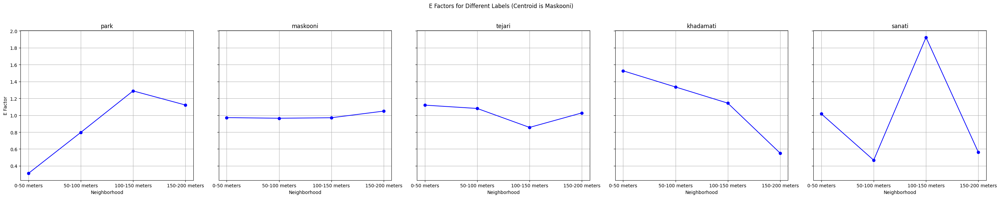

In [ ]:
labels = sample_50_centroids_gdf['landuse2'].unique()
labels = [label for label in labels if label != "bayer"]
neighborhoods = ["0-50 meters", "50-100 meters", "100-150 meters", "150-200 meters"]

num_labels = len(labels)

fig, axes = plt.subplots(nrows=1, ncols=num_labels, figsize=(30, 6), sharey=True)

for ax, label in zip(axes, labels):
    e_factors = [enrichment_factors[neighborhood][label] for neighborhood in neighborhoods]

    ax.plot(neighborhoods, e_factors, marker='o', linestyle='-', color='b')
    ax.set_xlabel('Neighborhood')
    ax.set_title(f'{label}')
    ax.grid(True)

axes[0].set_ylabel('E Factor')
fig.suptitle('E Factors for Different Labels (Centroid is Maskooni)')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


In [ ]:
def calculate_e_factor(landuse_counts, label):
    total_landuse_counts = {
        lbl: sum(
            landuse_counts[neighborhood].get(lbl, 0) for neighborhood in ["0-50 meters", "50-100 meters", "100-150 meters", "150-200 meters"]
        ) / 200
        for lbl in landuse_labels
    }

    total_landuse_200m = total_landuse_counts.get(label, 0)

    if total_landuse_200m == 0:
        return [0, 0, 0, 0]

    e_factors = [
        (landuse_counts["0-50 meters"].get(label, 0) / 50) / total_landuse_200m,
        (landuse_counts["50-100 meters"].get(label, 0) / 50) / total_landuse_200m,
        (landuse_counts["100-150 meters"].get(label, 0) / 50) / total_landuse_200m,
        (landuse_counts["150-200 meters"].get(label, 0) / 50) / total_landuse_200m
    ]

    return e_factors

label = 'maskooni'

e_factors = calculate_e_factor(total_landuse_counts_maskooni, "maskooni")
print(f"E factors for {label}: {e_factors}")


E factors for maskooni: [0.6672340425531915, 0.5753191489361702, 1.1302127659574468, 1.6272340425531915]


In [ ]:
def calculate_area_within_distance_ranges(centroids_gdf, landuse_gdf, distance_ranges):
    """
    Calculate the area of land use polygons within specified distance ranges from centroids.

    Parameters:
    centroids_gdf (GeoDataFrame): GeoDataFrame containing centroid points.
    landuse_gdf (GeoDataFrame): GeoDataFrame containing land use polygons.
    distance_ranges (list): List of distance ranges as tuples of (inner, outer) in meters.

    Returns:
    dict: A dictionary containing the area of land use polygons within each distance range.
    """
    areas = {f"{distance[0]}-{distance[1]} meters": 0 for distance in distance_ranges}

    for centroid in centroids_gdf.geometry:
        for distance in distance_ranges:
            buffer_inner = centroid.buffer(distance[0])
            buffer_outer = centroid.buffer(distance[1])
            ring = buffer_outer.difference(buffer_inner)
            intersection = gpd.overlay(landuse_gdf, gpd.GeoDataFrame(geometry=[ring], crs=landuse_gdf.crs), how='intersection')
            areas[f"{distance[0]}-{distance[1]} meters"] += intersection["SHAPE_Area"].sum()

    return areas

def calculate_enrichment_factor(label_area_ranges, total_area_ranges, label_total_area, total_area):
    """
    Calculate the enrichment factor for a specified land use label.

    Parameters:
    label_area_ranges (dict): Dictionary containing areas of the label within distance ranges.
    total_area_ranges (dict): Dictionary containing total areas of the distance ranges.
    label_total_area (float): Total area of the label in the whole study area.
    total_area (float): Total area of the whole study area.

    Returns:
    dict: A dictionary containing the enrichment factors for each distance range.
    """
    enrichment_factors = {}
    for range_key, label_area in label_area_ranges.items():
        total_area_range = total_area_ranges[range_key]
        if total_area_range == 0 or label_total_area == 0:
            enrichment_factors[range_key] = 0
        else:
            ef = (label_area / total_area_range) / (label_total_area / total_area)
            enrichment_factors[range_key] = ef

    return enrichment_factors

In [ ]:
landuse_gdf.head()

,OBJECTID,landuse2,SHAPE_Leng,SHAPE_Area,geometry,centroid
0,1,park,105.455958,136.512665,"POLYGON ((496940.491 3964027.419, 496940.621 3...",POINT (496915.431 3964027.831)
1,2,park,947.914231,1245.557294,"POLYGON ((497351.336 3964025.545, 497380.877 3...",POINT (497183.976 3964024.884)
2,3,tejari,34.123117,45.584853,"POLYGON ((496857.933 3964477.785, 496856.737 3...",POINT (496851.133 3964479.844)
3,4,maskooni,48.355071,130.751441,"POLYGON ((496978.598 3964481.452, 496975.810 3...",POINT (496971.087 3964476.500)
4,5,tejari,22.322830,30.951847,"POLYGON ((497557.699 3964268.273, 497556.913 3...",POINT (497554.328 3964266.334)


In [ ]:
total_area = landuse_gdf['SHAPE_Area'].sum()
print(f"Total area of the study area: {total_area}")

label_total_areas = landuse_gdf.groupby('landuse2')['SHAPE_Area'].sum().to_dict()
print(f"Total area of each label in the study area: {label_total_areas}")

Total area of the study area: 2200791.1244981503
Total area of each label in the study area: {'bayer': 455047.6224311397, 'khadamati': 153053.0495684792, 'maskooni': 1391652.8773920385, 'park': 53735.0387038716, 'sanati': 2508.3533699218, 'tejari': 144794.18303269942}


In [ ]:
total_areas = calculate_area_within_distance_ranges(centroids_gdf, landuse_gdf, distance_ranges)

label_total_area = landuse_gdf[landuse_gdf['landuse'] == label]["SHAPE_Area"].sum()
total_area = landuse_gdf["SHAPE_Area"].sum()

TypeError: ufunc 'isfinite' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

In [ ]:
# Calculate enrichment factors
enrichment_factors = calculate_enrichment_factor(label_areas, total_areas, label_total_area, total_area)

# Display the results
print(f"Enrichment factors for {label}: {enrichment_factors}")

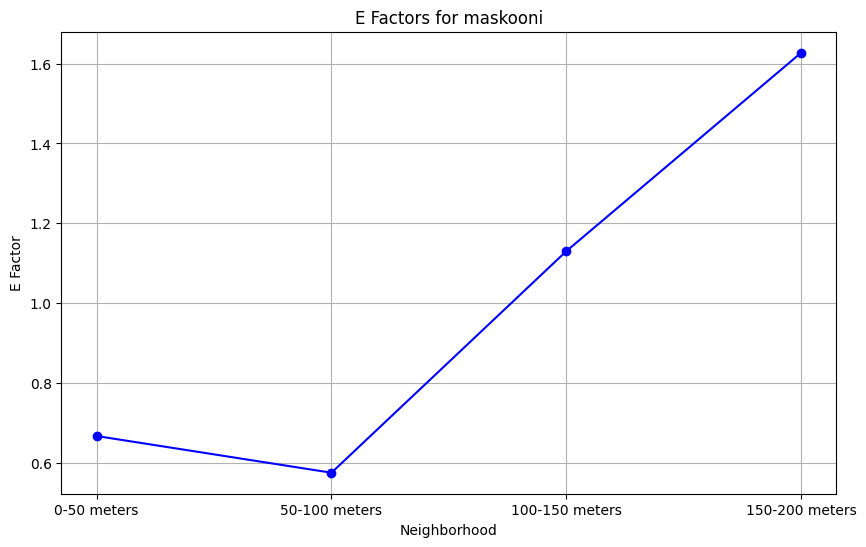

In [ ]:
neighborhoods = ["0-50 meters", "50-100 meters", "100-150 meters", "150-200 meters"]

plt.figure(figsize=(10, 6))
plt.plot(neighborhoods, e_factors, marker='o', linestyle='-', color='b')

plt.xlabel('Neighborhood')
plt.ylabel('E Factor')
plt.title(f'E Factors for {label}')
plt.grid(True)
plt.show()

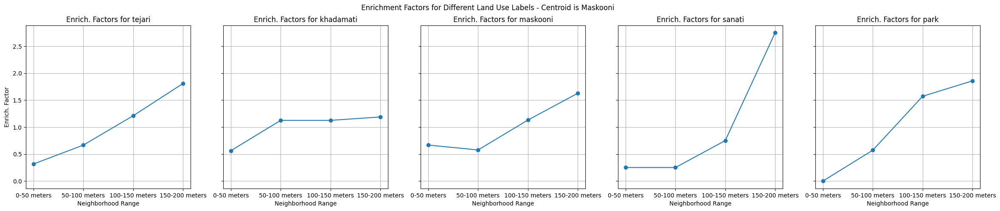

In [ ]:
# Calculate local factors for each label
e_factors_dict = {label: calculate_e_factor(total_landuse_counts_maskooni, label) for label in landuse_labels}

# Plot the local factors for each label in separate graphs
neighborhoods = ["0-50 meters", "50-100 meters", "100-150 meters", "150-200 meters"]
x = range(len(neighborhoods))

fig, axs = plt.subplots(1, len(landuse_labels), figsize=(29, 5), sharey=True)

for i, label in enumerate(landuse_labels):
    axs[i].plot(x, e_factors_dict[label], marker='o', label=label)
    axs[i].set_xticks(x)
    axs[i].set_xticklabels(neighborhoods)
    axs[i].set_xlabel('Neighborhood Range')
    axs[i].set_title(f'Enrich. Factors for {label}')
    axs[i].grid(True)
    if i == 0:
        axs[i].set_ylabel('Enrich. Factor')

plt.suptitle('Enrichment Factors for Different Land Use Labels - Centroid is Maskooni')
plt.show()

<ipython-input-65-e68b5ac50b5c>:4: RuntimeWarning: divide by zero encountered in log
  log_factors = np.log(e_factors_dict[label])


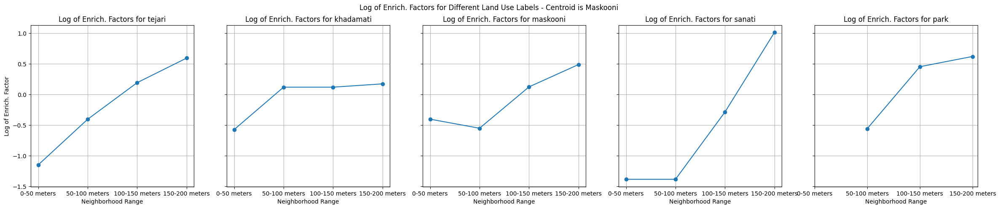

In [ ]:
fig, axs = plt.subplots(1, len(landuse_labels), figsize=(29, 5), sharey=True)

for i, label in enumerate(landuse_labels):
    log_factors = np.log(e_factors_dict[label])
    axs[i].plot(x, log_factors, marker='o', label=label)
    axs[i].set_xticks(x)
    axs[i].set_xticklabels(neighborhoods)
    axs[i].set_xlabel('Neighborhood Range')
    axs[i].set_title(f'Log of Enrich. Factors for {label}')
    axs[i].grid(True)
    if i == 0:
        axs[i].set_ylabel('Log of Enrich. Factor')

plt.suptitle('Log of Enrich. Factors for Different Land Use Labels - Centroid is Maskooni')
plt.show()

In [ ]:
def filter_centroids_by_label(centroids_data, label):
    """
    Filters centroids based on a given landuse label.

    Args:
        centroids_data (dict): The dictionary containing centroid data.
        label (str): The landuse label to filter by.

    Returns:
        dict: A dictionary containing centroids that match the given label.
    """
    # Filter the centroids_data to select only those with the given landuse label
    filtered_centroids_data = {idx: data for idx, data in centroids_data.items() if data["attributes"]["landuse2"] == label}

    # Convert the filtered data to a list of dictionaries
    filtered_centroids_list = []
    for idx, data in filtered_centroids_data.items():
        for range_key, range_data in data["covered_ranges"].items():
            for centroid, attributes in zip(range_data["centroids"], range_data["attributes"]):
                filtered_centroids_list.append({
                    "sample_centroid_id": idx,
                    "range": range_key,
                    "centroid": centroid,
                    **attributes
                })

    # Convert the list to a dictionary grouped by sample_centroid_id
    filtered_centroids_dict = {}
    for item in filtered_centroids_list:
        centroid_id = item.pop("sample_centroid_id")
        if centroid_id not in filtered_centroids_dict:
            filtered_centroids_dict[centroid_id] = {
                "central_landuse": filtered_centroids_data[centroid_id]["attributes"]["landuse2"],
                "covered_ranges": {
                    "0-50 meters": [],
                    "50-100 meters": [],
                    "100-150 meters": [],
                    "150-200 meters": []
                }
            }
        filtered_centroids_dict[centroid_id]["covered_ranges"][item["range"]].append(item)

    return filtered_centroids_dict

In [ ]:
tejari_centroids_dict = filter_centroids_by_label(sample_50_centroids_data, "tejari")
park_centroids_dict = filter_centroids_by_label(sample_50_centroids_data, "park")
khadamati_centroids_dict = filter_centroids_by_label(sample_50_centroids_data, "khadamati")

In [ ]:
tejari_centroids_dict

{2: {'central_landuse': 'tejari',
  'covered_ranges': {'0-50 meters': [{'range': '0-50 meters',
     'centroid': <POINT (496851.133 3964479.844)>,
     'landuse2': 'tejari',
     'SHAPE_Area': 45.5848525957,
     'nearest_node_id': 2316,
     'nearest_node_geom': <POINT (496835.553 3964457.322)>},
    {'range': '0-50 meters',
     'centroid': <POINT (496856.927 3964490.978)>,
     'landuse2': 'tejari',
     'SHAPE_Area': 48.9645259134,
     'nearest_node_id': 2984,
     'nearest_node_geom': <POINT (496820.87 3964475.934)>},
    {'range': '0-50 meters',
     'centroid': <POINT (496853.044 3964482.908)>,
     'landuse2': 'tejari',
     'SHAPE_Area': 52.3793704693,
     'nearest_node_id': 2316,
     'nearest_node_geom': <POINT (496835.553 3964457.322)>},
    {'range': '0-50 meters',
     'centroid': <POINT (496854.651 3964487.072)>,
     'landuse2': 'tejari',
     'SHAPE_Area': 59.1892483033,
     'nearest_node_id': 2316,
     'nearest_node_geom': <POINT (496835.553 3964457.322)>},
    {'

In [ ]:
def count_landuses_by_distance(filtered_centroids_data, landuse_labels):
    """
    Counts the occurrences of specified land uses within various distance ranges around filtered centroids.

    Args:
        filtered_centroids_data (dict): The dictionary containing filtered centroid data.
        landuse_labels (list): The list of land use labels to count.

    Returns:
        dict: A dictionary with the counts of land uses within different distance ranges.
    """
    # Initialize a dictionary to store the land use counts for each neighborhood
    landuse_counts = {}

    # Iterate over each centroid's data in the filtered centroids data
    for idx, data in filtered_centroids_data.items():
        central_landuse = data["attributes"].get('landuse2')

        # Initialize a dictionary to store the counts for the current centroid
        centroid_landuse_counts = {
            "central_landuse": central_landuse,
            "0-50 meters": {label: 0 for label in landuse_labels},
            "50-100 meters": {label: 0 for label in landuse_labels},
            "100-150 meters": {label: 0 for label in landuse_labels},
            "150-200 meters": {label: 0 for label in landuse_labels}
        }

        # Count the land uses in the 0-50 meters range
        for attributes in data["covered_ranges"]["0-50 meters"]["attributes"]:
            landuse = attributes.get('landuse2')
            if landuse in landuse_labels:
                centroid_landuse_counts["0-50 meters"][landuse] += 1

        # Count the land uses in the 50-100 meters range
        for attributes in data["covered_ranges"]["50-100 meters"]["attributes"]:
            landuse = attributes.get('landuse2')
            if landuse in landuse_labels:
                centroid_landuse_counts["50-100 meters"][landuse] += 1

        # Count the land uses in the 100-150 meters range
        for attributes in data["covered_ranges"]["100-150 meters"]["attributes"]:
            landuse = attributes.get('landuse2')
            if landuse in landuse_labels:
                centroid_landuse_counts["100-150 meters"][landuse] += 1

        # Count the land uses in the 150-200 meters range
        for attributes in data["covered_ranges"]["150-200 meters"]["attributes"]:
            landuse = attributes.get('landuse2')
            if landuse in landuse_labels:
                centroid_landuse_counts["150-200 meters"][landuse] += 1

        # Store the counts in the main dictionary
        landuse_counts[idx] = centroid_landuse_counts

    return landuse_counts

In [ ]:
landuse_counts_tejari = count_landuses_by_distance(tejari_centroids_dict, landuse_labels_maskooni)

# Display the land use counts
landuse_counts_tejari

KeyError: 'attributes'

In [ ]:
# Initialize the dictionary to store the data for all centroids
all_centroids_data = {}

# Iterate over each centroid in the dataframe
for idx, sample_point in centroids_gdf.iterrows():
    nearest_node_id = sample_point['nearest_node_id']
    nearest_node_geom = sample_point['nearest_node_geom']

    # Initialize the dictionary for the current centroid
    centroid_data = {
        "centroid": sample_point.centroid,
        "attributes": sample_point.to_dict(),
        "covered_ranges": {
            "0-50 meters": {
                "centroids": [],
                "attributes": []
            },
            "50-120 meters": {
                "centroids": [],
                "attributes": []
            },
            "120-200 meters": {
                "centroids": [],
                "attributes": []
            }
        }
    }

    # Perform a network analysis to find the service area within a 50-meter distance
    service_area_nodes_50 = nx.single_source_dijkstra_path_length(street_network, (nearest_node_geom.x, nearest_node_geom.y), cutoff=50, weight='weight')

    covered_nodes_50 = [Point(x, y) for x, y in service_area_nodes_50.keys()]
    covered_nodes_gdf_50 = gpd.GeoDataFrame(geometry=covered_nodes_50, crs=nodes_gdf.crs)
    covered_node_ids_50 = [nodes_gdf[nodes_gdf.geometry == node].node_id.values[0] for node in covered_nodes_gdf_50.geometry]
    covered_centroids_50 = centroids_gdf[centroids_gdf['nearest_node_id'].isin(covered_node_ids_50)]

    centroid_data["covered_ranges"]["0-50 meters"]["centroids"] = covered_centroids_50['centroid'].tolist()
    centroid_data["covered_ranges"]["0-50 meters"]["attributes"] = covered_centroids_50.drop(columns='centroid').to_dict('records')

    service_area_nodes_120 = nx.single_source_dijkstra_path_length(street_network, (nearest_node_geom.x, nearest_node_geom.y), cutoff=120, weight='weight')
    covered_nodes_120 = [Point(x, y) for x, y in service_area_nodes_120.keys()]
    covered_nodes_gdf_120 = gpd.GeoDataFrame(geometry=covered_nodes_120, crs=nodes_gdf.crs)
    new_covered_nodes_70 = set(service_area_nodes_120.keys()) - set(service_area_nodes_50.keys())
    new_covered_nodes_gdf_70 = gpd.GeoDataFrame(geometry=[Point(x, y) for x, y in new_covered_nodes_70], crs=nodes_gdf.crs)
    new_covered_node_ids_70 = [nodes_gdf[nodes_gdf.geometry == node].node_id.values[0] for node in new_covered_nodes_gdf_70.geometry]
    new_covered_centroids_70 = centroids_gdf[centroids_gdf['nearest_node_id'].isin(new_covered_node_ids_70)]

    centroid_data["covered_ranges"]["50-120 meters"]["centroids"] = new_covered_centroids_70['centroid'].tolist()
    centroid_data["covered_ranges"]["50-120 meters"]["attributes"] = new_covered_centroids_70.drop(columns='centroid').to_dict('records')

    service_area_nodes_200 = nx.single_source_dijkstra_path_length(street_network, (nearest_node_geom.x, nearest_node_geom.y), cutoff=200, weight='weight')
    covered_nodes_200 = [Point(x, y) for x, y in service_area_nodes_200.keys()]
    covered_nodes_gdf_200 = gpd.GeoDataFrame(geometry=covered_nodes_200, crs=nodes_gdf.crs)
    new_covered_nodes_80 = set(service_area_nodes_200.keys()) - set(service_area_nodes_120.keys())
    new_covered_nodes_gdf_80 = gpd.GeoDataFrame(geometry=[Point(x, y) for x, y in new_covered_nodes_80], crs=nodes_gdf.crs)
    new_covered_node_ids_80 = [nodes_gdf[nodes_gdf.geometry == node].node_id.values[0] for node in new_covered_nodes_gdf_80.geometry]
    new_covered_centroids_80 = centroids_gdf[centroids_gdf['nearest_node_id'].isin(new_covered_node_ids_80)]

    centroid_data["covered_ranges"]["120-200 meters"]["centroids"] = new_covered_centroids_80['centroid'].tolist()
    centroid_data["covered_ranges"]["120-200 meters"]["attributes"] = new_covered_centroids_80.drop(columns='centroid').to_dict('records')

    all_centroids_data[idx] = centroid_data

all_centroids_list = []
for idx, data in all_centroids_data.items():
    for range_key, range_data in data["covered_ranges"].items():
        for centroid, attributes in zip(range_data["centroids"], range_data["attributes"]):
            all_centroids_list.append({
                "sample_centroid_id": idx,
                "range": range_key,
                "centroid": centroid,
                **attributes
            })

# Create a GeoDataFrame from the list
all_centroids_gdf = gpd.GeoDataFrame(all_centroids_list, geometry="centroid", crs=centroids_gdf.crs)

print(json.dumps(all_centroids_data, indent=2, default=str))

KeyboardInterrupt: 